In [ ]:
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import seaborn as sns
import time
import os
from PIL import Image
import math

In [ ]:
class FashionDataset(Dataset):
    def __init__(self, csv_file, transform = None):
        data = pd.read_csv(csv_file)
        self.pixels = data.iloc[:, 1:].values.astype('float32')
        self.labels = data.iloc[:, 0].values
        self.transform = transform
    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        image = self.pixels[idx]
        image = image / 255.0
        image = torch.tensor(image)

        if self.transform:
            image = self.transform(image)

        return image, self.labels[idx]


In [ ]:
path_to_dataset = "fashion-mnist_train.csv"
train_dataset = FashionDataset(path_to_dataset)
train_loader = DataLoader(train_dataset, batch_size=256, shuffle=True)

In [ ]:
train_size = int(0.8 * len(train_dataset))
val_size = len(train_dataset) - train_size
train_subset, val_subset = torch.utils.data.random_split(train_dataset, [train_size, val_size])

BATCH_SIZE = 256
train_loader = DataLoader(train_subset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_subset, batch_size=BATCH_SIZE, shuffle=False)
temp_loader = DataLoader(val_subset, batch_size=BATCH_SIZE, shuffle=True)

history_dictionary = {}

In [ ]:
class EarlyStopping:
    def __init__(self, patience=10, min_delta=0, verbose=False, path='best_model.pth'):
        self.patience = patience
        self.min_delta = min_delta
        self.verbose = verbose
        self.path = path
        self.counter = 0
        self.best_loss = None
        self.early_stop = False

    def __call__(self, val_loss, model):
        if self.best_loss is None:
            self.best_loss = val_loss
            self.save_checkpoint(val_loss, model)
        elif val_loss > self.best_loss - self.min_delta:
            self.counter += 1
            if self.verbose:
                print(f'EarlyStopping counter: {self.counter} out of {self.patience}')
            if self.counter >= self.patience:
                self.early_stop = True
        else:
            self.best_loss = val_loss
            self.save_checkpoint(val_loss, model)
            self.counter = 0

    def save_checkpoint(self, val_loss, model):
        if self.verbose:
            print(f'Validation loss decreased. Saving model to {self.path}...')
        torch.save(model.state_dict(), self.path)

In [ ]:
def evaluate_model(model, loader, device):
    model.eval()
    running_loss = 0.0
    criterion = nn.MSELoss()

    with torch.no_grad():
        for images, _ in loader:
            images = images.to(device)

            reconstructed = model(images)
            loss = criterion(reconstructed, images.view_as(reconstructed))
            running_loss += loss.item()

    epoch_loss = running_loss / len(loader)
    return epoch_loss

In [ ]:
def perform_learning(model, EPOCHS, optimizer, train_loader, val_loader, device, early_stopping = None):
    history = {
        'train_loss': [],
        'val_loss': [],
        'epoch_time': []
    }
    criterion = nn.MSELoss()
    for epoch in range(EPOCHS):
        start_time = time.time()
        model.train()

        running_loss = 0.0

        for images, _ in train_loader:
            images = images.to(device)

            optimizer.zero_grad()
            outputs = model(images)

            loss = criterion(outputs, images.view_as(outputs))
            loss.backward()
            optimizer.step()

            running_loss += loss.item()

        epoch_loss = running_loss / len(train_loader)
        val_loss = evaluate_model(model, val_loader, device)

        end_time = time.time()
        epoch_duration = end_time - start_time

        history['train_loss'].append(epoch_loss)
        history['val_loss'].append(val_loss)
        history['epoch_time'].append(epoch_duration)

        print(f"Epoch [{epoch+1}/{EPOCHS}] - {epoch_duration:.2f}s")
        print(f"  Train MSE Loss: {epoch_loss:.4f} | Val MSE Loss: {val_loss:.4f}")

        if early_stopping is not None:
            early_stopping(val_loss, model)
            if early_stopping.early_stop:
                print("--- Early stopping triggered ---")
                model.load_state_dict(torch.load(early_stopping.path))
                break
        print("-" * 50)

    return history

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")

Device: cuda


In [ ]:
def plot_history(history, title, ylim=None, log_scale=False, start_epoch=0):
    plt.figure(figsize=(10, 6))
    train_loss = history['train_loss'][start_epoch:]
    val_loss = history['val_loss'][start_epoch:]
    epochs = range(start_epoch + 1, start_epoch + len(train_loss) + 1)

    plt.plot(epochs, train_loss, label='Train Loss', color='blue', linewidth=2)
    plt.plot(epochs, val_loss, label='Validation Loss', color='orange', linestyle='--', linewidth=2)

    if log_scale:
        plt.yscale('log')
        plt.ylabel('MSE Loss (Log Scale)', fontsize=12)
    else:
        plt.ylabel('MSE Loss', fontsize=12)

    if ylim:
        plt.ylim(ylim)

    plt.title(f'Model Training History: {title}', fontsize=14)
    plt.xlabel('Epochs', fontsize=12)
    plt.grid(True, linestyle=':', alpha=0.7)
    plt.legend()
    plt.tight_layout()
    plt.show()

In [ ]:
def visualize_reconstructions(model, loader, device, n=10):
    model.eval()
    with torch.no_grad():
        images, _ = next(iter(loader))
        images = images.to(device)

        reconstructed = model(images)

        images = images.cpu().numpy()
        reconstructed = reconstructed.cpu().numpy()

        plt.figure(figsize=(20, 4))
        for i in range(n):
            ax = plt.subplot(2, n, i + 1)
            plt.imshow(images[i].reshape(28, 28), cmap='gray')
            plt.title("Original")
            plt.axis('off')

            ax = plt.subplot(2, n, i + 1 + n)
            plt.imshow(reconstructed[i].reshape(28, 28), cmap='gray')
            plt.title("Reconstructed")
            plt.axis('off')

        plt.tight_layout()
        plt.show()

In [ ]:
class DeepAutoEncoder(nn.Module):
    def __init__(self): #10
        super(DeepAutoEncoder, self).__init__()

        self.encoder = nn.Sequential(
            nn.Linear(784, 1500),
            nn.ReLU(),
            nn.Linear(1500, 1000),
            nn.ReLU(),
            nn.Linear(1000, 500),
            nn.ReLU(),
            nn.Linear(500, 10),
            nn.Sigmoid()
        )

        self.decoder = nn.Sequential(
            nn.Linear(10, 500),
            nn.ReLU(),
            nn.Linear(500, 1000),
            nn.ReLU(),
            nn.Linear(1000, 1500),
            nn.ReLU(),
            nn.Linear(1500, 784),
            nn.Sigmoid()
        )

    def forward(self, x):
        x = x.view(-1, 784)
        encoded = self.encoder(x)
        decoded = self.decoder(encoded)
        return decoded

In [ ]:
deep_autoencoder_model_v1 = DeepAutoEncoder().to(device)
deep_autoencoder_model_v1_optimizer = optim.Adam(deep_autoencoder_model_v1.parameters(), lr=1e-3)
early_stop = EarlyStopping(patience=10, min_delta=0.0001, verbose=False, path='deep_autoencoder_model_v1.pth')

In [ ]:
history_dictionary["DeepAutoEncoder_v1"] = perform_learning(deep_autoencoder_model_v1, 100, deep_autoencoder_model_v1_optimizer, train_loader, val_loader, device, early_stop)

Epoch [1/100] - 2.52s
  Train MSE Loss: 0.0548 | Val MSE Loss: 0.0346
--------------------------------------------------
Epoch [2/100] - 2.27s
  Train MSE Loss: 0.0308 | Val MSE Loss: 0.0267
--------------------------------------------------
Epoch [3/100] - 2.30s
  Train MSE Loss: 0.0256 | Val MSE Loss: 0.0238
--------------------------------------------------
Epoch [4/100] - 2.24s
  Train MSE Loss: 0.0231 | Val MSE Loss: 0.0221
--------------------------------------------------
Epoch [5/100] - 2.62s
  Train MSE Loss: 0.0214 | Val MSE Loss: 0.0205
--------------------------------------------------
Epoch [6/100] - 2.60s
  Train MSE Loss: 0.0201 | Val MSE Loss: 0.0195
--------------------------------------------------
Epoch [7/100] - 2.31s
  Train MSE Loss: 0.0193 | Val MSE Loss: 0.0188
--------------------------------------------------
Epoch [8/100] - 2.27s
  Train MSE Loss: 0.0183 | Val MSE Loss: 0.0182
--------------------------------------------------
Epoch [9/100] - 2.28s
  Train MS

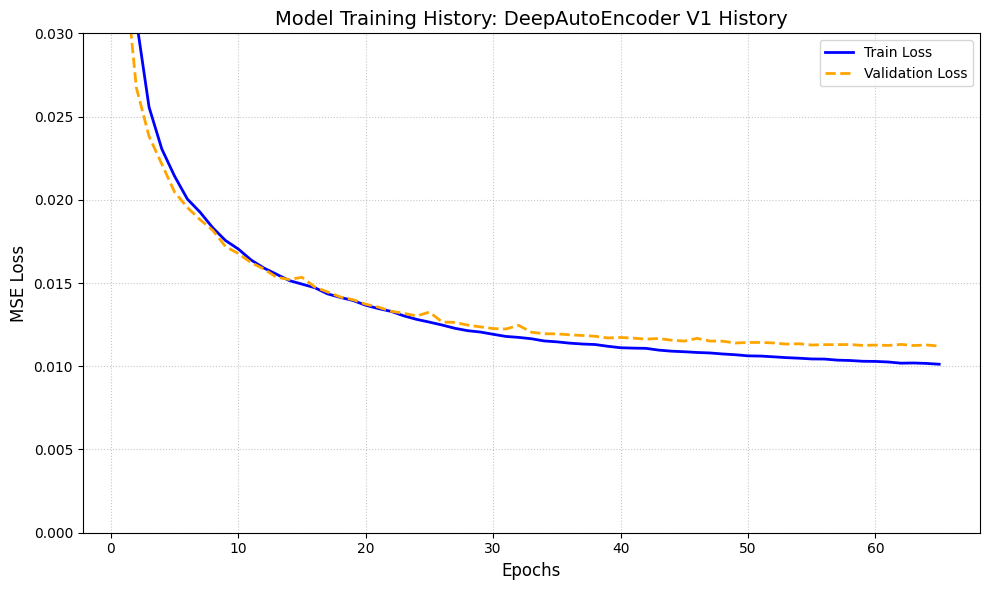

In [ ]:
plot_history(history_dictionary['DeepAutoEncoder_v1'], "DeepAutoEncoder V1 History", (0, 0.03))

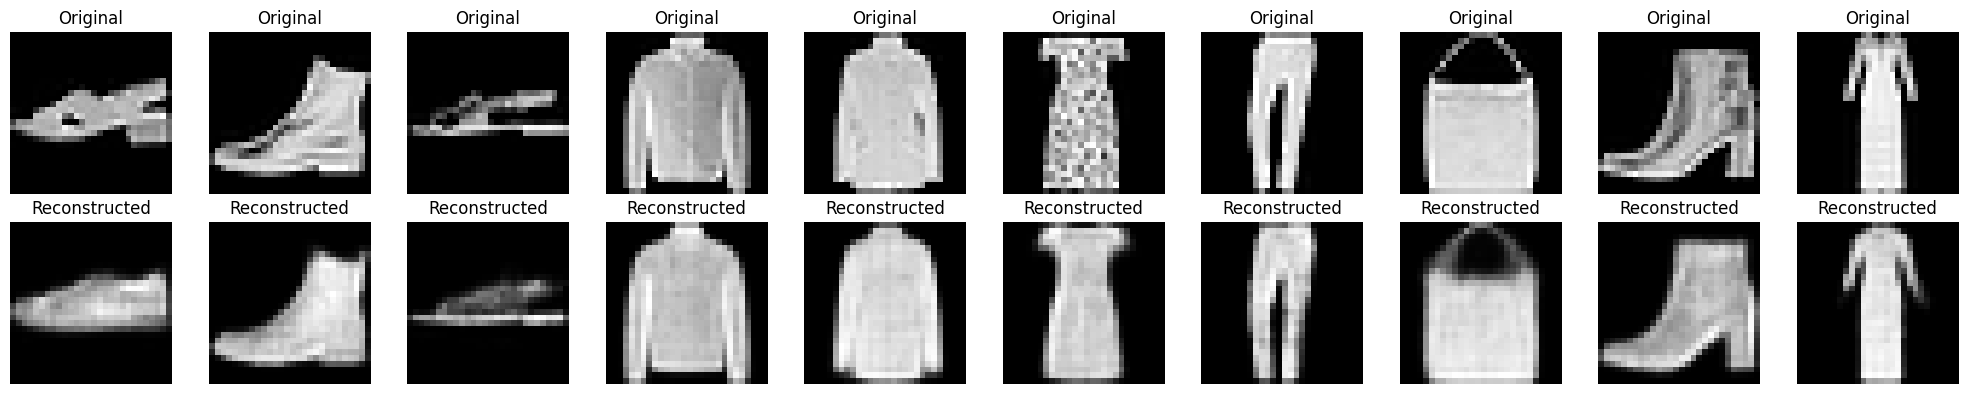

In [ ]:
visualize_reconstructions(deep_autoencoder_model_v1, temp_loader, device)

In [ ]:
class DeepAutoEncoder_v2(nn.Module): #32
    def __init__(self):
        super(DeepAutoEncoder_v2, self).__init__()
        self.encoder = nn.Sequential(
            nn.Linear(784, 512),
            nn.LeakyReLU(0.2),
            nn.Linear(512, 256),
            nn.LeakyReLU(0.2),
            nn.Linear(256, 32),
            nn.Sigmoid()
        )
        self.decoder = nn.Sequential(
            nn.Linear(32, 256),
            nn.LeakyReLU(0.2),
            nn.Linear(256, 512),
            nn.LeakyReLU(0.2),
            nn.Linear(512, 784),
            nn.Sigmoid()
        )

    def forward(self, x):
        x = x.view(-1, 784)
        return self.decoder(self.encoder(x))

In [ ]:
deep_autoencoder_model_v2 = DeepAutoEncoder_v2().to(device)
deep_autoencoder_model_v2_optimizer = optim.Adam(deep_autoencoder_model_v2.parameters(), lr=1e-3)
early_stop = EarlyStopping(patience=10, min_delta=0.0001, verbose=False, path='deep_autoencoder_model_v2.pt')

In [ ]:
history_dictionary["DeepAutoEncoder_v2"] = perform_learning(deep_autoencoder_model_v2, 100, deep_autoencoder_model_v2_optimizer, train_loader, val_loader, device, early_stop)

Epoch [1/100] - 1.87s
  Train MSE Loss: 0.0639 | Val MSE Loss: 0.0348
--------------------------------------------------
Epoch [2/100] - 1.82s
  Train MSE Loss: 0.0274 | Val MSE Loss: 0.0231
--------------------------------------------------
Epoch [3/100] - 1.80s
  Train MSE Loss: 0.0214 | Val MSE Loss: 0.0200
--------------------------------------------------
Epoch [4/100] - 2.22s
  Train MSE Loss: 0.0188 | Val MSE Loss: 0.0181
--------------------------------------------------
Epoch [5/100] - 2.08s
  Train MSE Loss: 0.0174 | Val MSE Loss: 0.0170
--------------------------------------------------
Epoch [6/100] - 1.77s
  Train MSE Loss: 0.0164 | Val MSE Loss: 0.0159
--------------------------------------------------
Epoch [7/100] - 1.77s
  Train MSE Loss: 0.0154 | Val MSE Loss: 0.0149
--------------------------------------------------
Epoch [8/100] - 1.78s
  Train MSE Loss: 0.0146 | Val MSE Loss: 0.0142
--------------------------------------------------
Epoch [9/100] - 1.78s
  Train MS

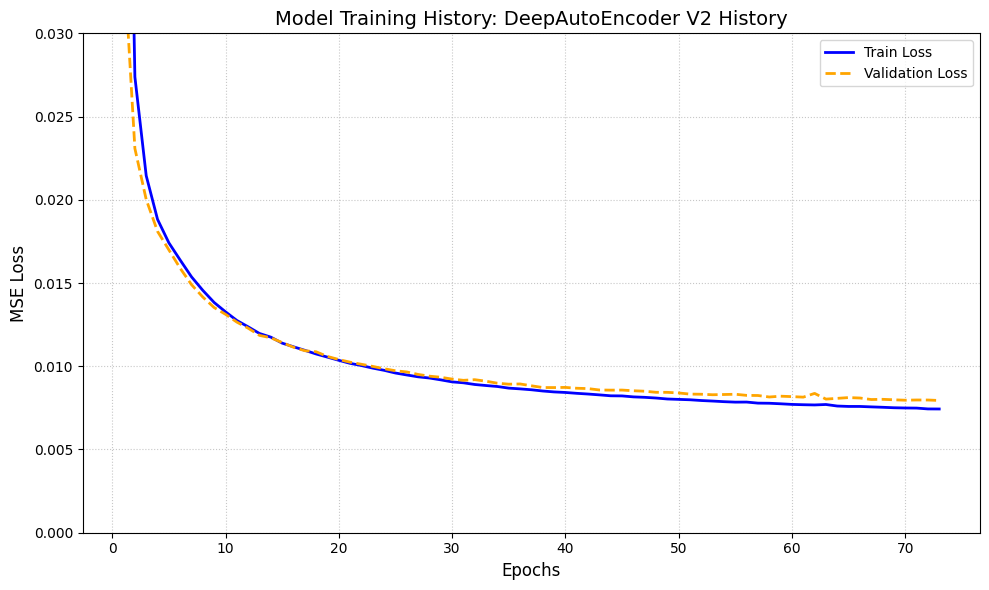

In [ ]:
plot_history(history_dictionary['DeepAutoEncoder_v2'], "DeepAutoEncoder V2 History", (0, 0.03))

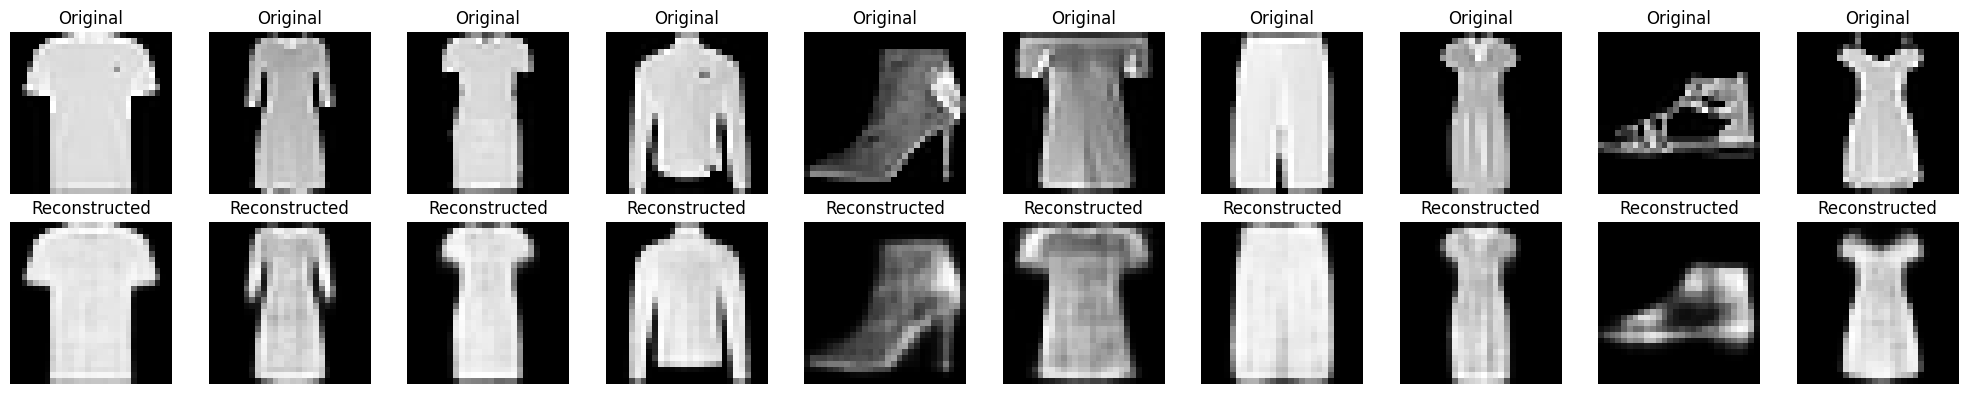

In [ ]:
visualize_reconstructions(deep_autoencoder_model_v2, temp_loader, device)

In [ ]:
class DeepAutoEncoder_v3(nn.Module): #64
    def __init__(self):
        super(DeepAutoEncoder_v3, self).__init__()
        self.encoder = nn.Sequential(
            nn.Linear(784, 1024),
            nn.ReLU(),
            nn.Linear(1024, 512),
            nn.ReLU(),
            nn.Linear(512, 64),
            nn.Sigmoid()
        )
        self.decoder = nn.Sequential(
            nn.Linear(64, 512),
            nn.ReLU(),
            nn.Linear(512, 1024),
            nn.ReLU(),
            nn.Linear(1024, 784),
            nn.Sigmoid()
        )

    def forward(self, x):
        x = x.view(-1, 784)
        return self.decoder(self.encoder(x))

In [ ]:
deep_autoencoder_model_v3 = DeepAutoEncoder_v3().to(device)
deep_autoencoder_model_v3_optimizer = optim.Adam(deep_autoencoder_model_v3.parameters(), lr=1e-3)
early_stop = EarlyStopping(patience=10, min_delta=0.0001, verbose=False, path='deep_autoencoder_model_v3.pth')

In [ ]:
history_dictionary["DeepAutoEncoder_v3"] = perform_learning(deep_autoencoder_model_v3, 100, deep_autoencoder_model_v3_optimizer, train_loader, val_loader, device, early_stop)

Epoch [1/100] - 2.00s
  Train MSE Loss: 0.0559 | Val MSE Loss: 0.0324
--------------------------------------------------
Epoch [2/100] - 2.00s
  Train MSE Loss: 0.0270 | Val MSE Loss: 0.0239
--------------------------------------------------
Epoch [3/100] - 2.24s
  Train MSE Loss: 0.0218 | Val MSE Loss: 0.0213
--------------------------------------------------
Epoch [4/100] - 2.25s
  Train MSE Loss: 0.0195 | Val MSE Loss: 0.0183
--------------------------------------------------
Epoch [5/100] - 2.02s
  Train MSE Loss: 0.0179 | Val MSE Loss: 0.0175
--------------------------------------------------
Epoch [6/100] - 2.04s
  Train MSE Loss: 0.0167 | Val MSE Loss: 0.0164
--------------------------------------------------
Epoch [7/100] - 2.02s
  Train MSE Loss: 0.0157 | Val MSE Loss: 0.0151
--------------------------------------------------
Epoch [8/100] - 2.01s
  Train MSE Loss: 0.0147 | Val MSE Loss: 0.0144
--------------------------------------------------
Epoch [9/100] - 2.35s
  Train MS

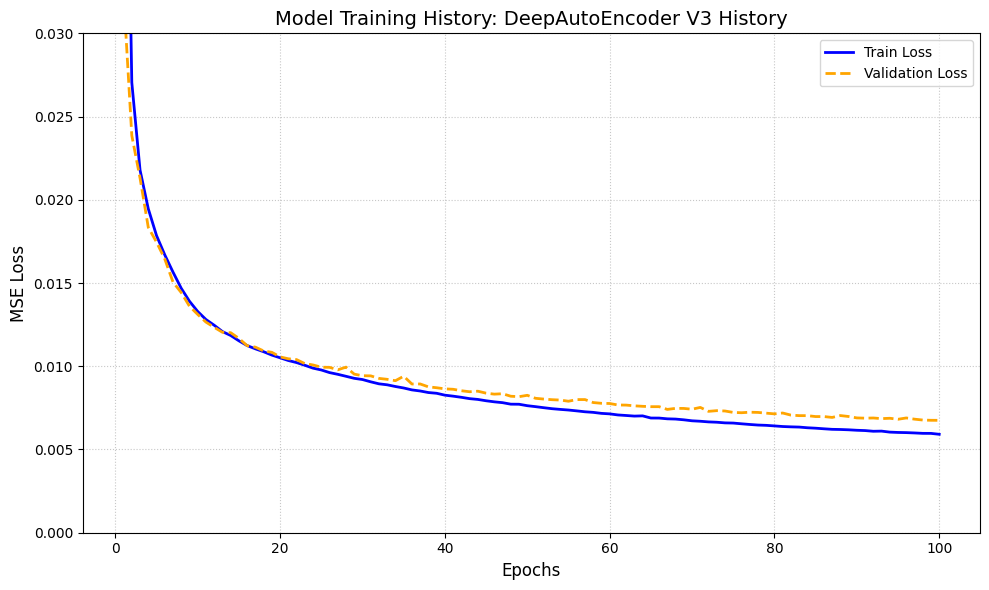

In [ ]:
plot_history(history_dictionary['DeepAutoEncoder_v3'], "DeepAutoEncoder V3 History", (0, 0.03))

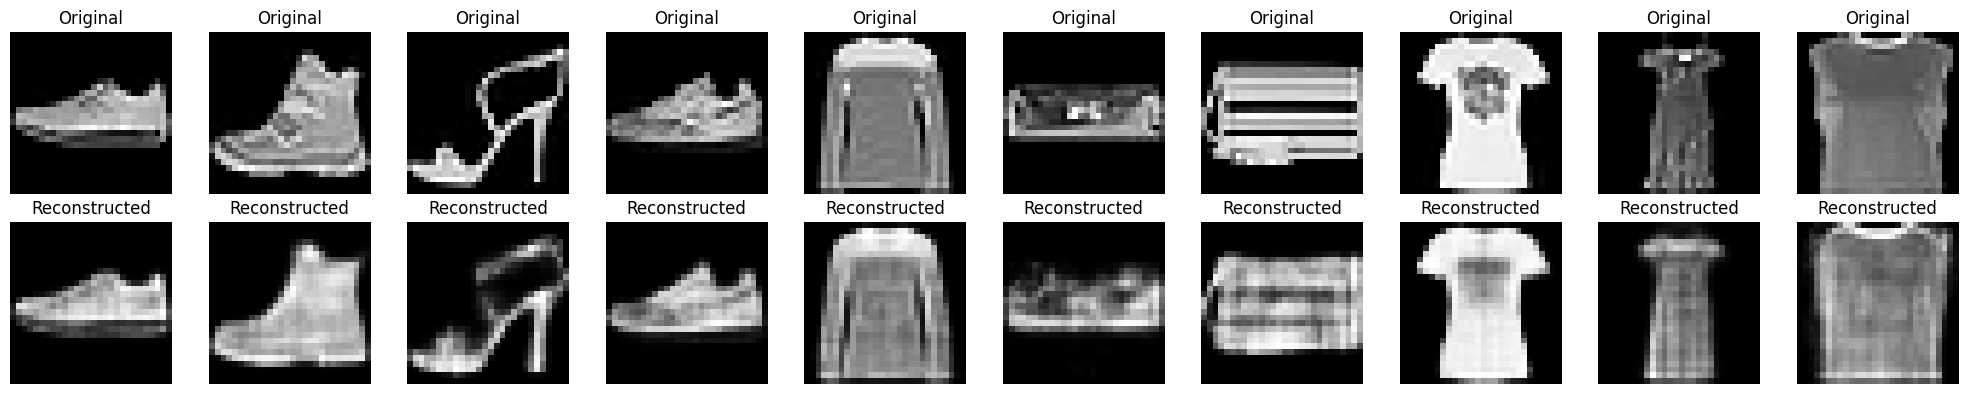

In [ ]:
visualize_reconstructions(deep_autoencoder_model_v3, temp_loader, device)

In [ ]:
class ConvolutionalAutoEncoder(nn.Module):
    def __init__(self): #16x4x4
        super(ConvolutionalAutoEncoder, self).__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(1, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            nn.Conv2d(64, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            nn.Conv2d(32, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2, padding = 1)
        )

        self.decoder = nn.Sequential(
            nn.Conv2d(16, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Upsample(scale_factor=2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Upsample(scale_factor=2),

            nn.Conv2d(32, 64, kernel_size=3, padding=0),
            nn.ReLU(),
            nn.Upsample(scale_factor=2),

            nn.Conv2d(64, 1, kernel_size=3, padding=1),
            nn.Sigmoid()
        )

    def forward(self, x):
        if(len(x.shape) == 2):
            x = x.view(-1, 1, 28, 28)

        encoded = self.encoder(x)
        decoded = self.decoder(encoded)
        return decoded

In [ ]:
convolutional_autoencoder_model_v1 = ConvolutionalAutoEncoder() .to(device)
convolutional_autoencoder_model_v1_optimizer = optim.Adam(convolutional_autoencoder_model_v1.parameters(), lr=1e-4)
early_stop = EarlyStopping(patience=10, min_delta=0.0001, verbose=False, path='convolutional_autoencoder_model_v1.pth')

In [ ]:
history_dictionary["ConvolutionalAutoEncoder_v1"] = perform_learning(convolutional_autoencoder_model_v1, 100, convolutional_autoencoder_model_v1_optimizer, train_loader, val_loader, device, early_stop)

Epoch [1/100] - 5.31s
  Train MSE Loss: 0.0995 | Val MSE Loss: 0.0365
--------------------------------------------------
Epoch [2/100] - 4.25s
  Train MSE Loss: 0.0310 | Val MSE Loss: 0.0273
--------------------------------------------------
Epoch [3/100] - 4.39s
  Train MSE Loss: 0.0255 | Val MSE Loss: 0.0238
--------------------------------------------------
Epoch [4/100] - 4.41s
  Train MSE Loss: 0.0228 | Val MSE Loss: 0.0218
--------------------------------------------------
Epoch [5/100] - 4.28s
  Train MSE Loss: 0.0212 | Val MSE Loss: 0.0205
--------------------------------------------------
Epoch [6/100] - 4.42s
  Train MSE Loss: 0.0200 | Val MSE Loss: 0.0195
--------------------------------------------------
Epoch [7/100] - 4.35s
  Train MSE Loss: 0.0192 | Val MSE Loss: 0.0189
--------------------------------------------------
Epoch [8/100] - 4.28s
  Train MSE Loss: 0.0186 | Val MSE Loss: 0.0183
--------------------------------------------------
Epoch [9/100] - 4.60s
  Train MS

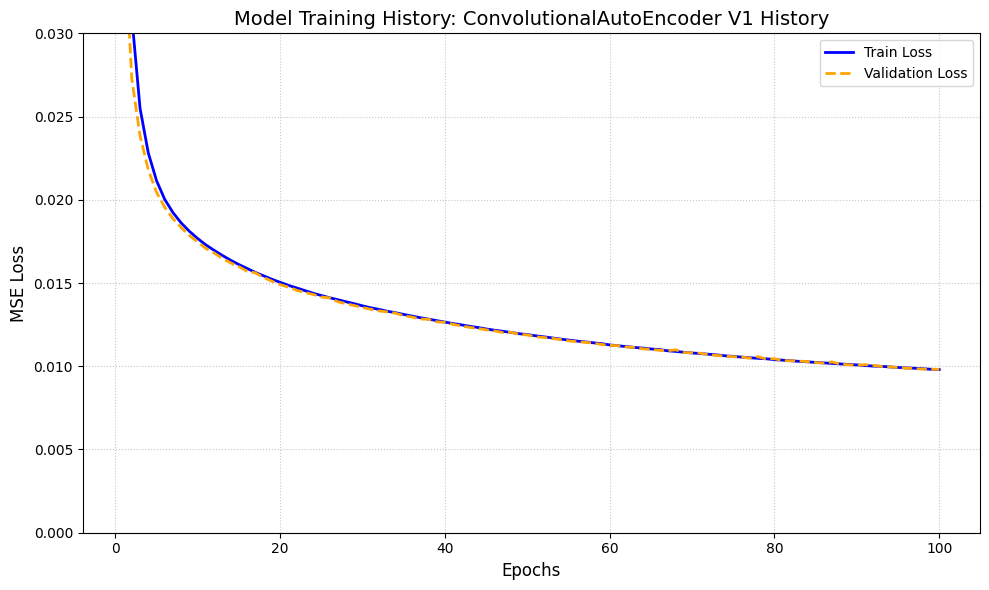

In [ ]:
plot_history(history_dictionary['ConvolutionalAutoEncoder_v1'], "ConvolutionalAutoEncoder V1 History", (0, 0.03))

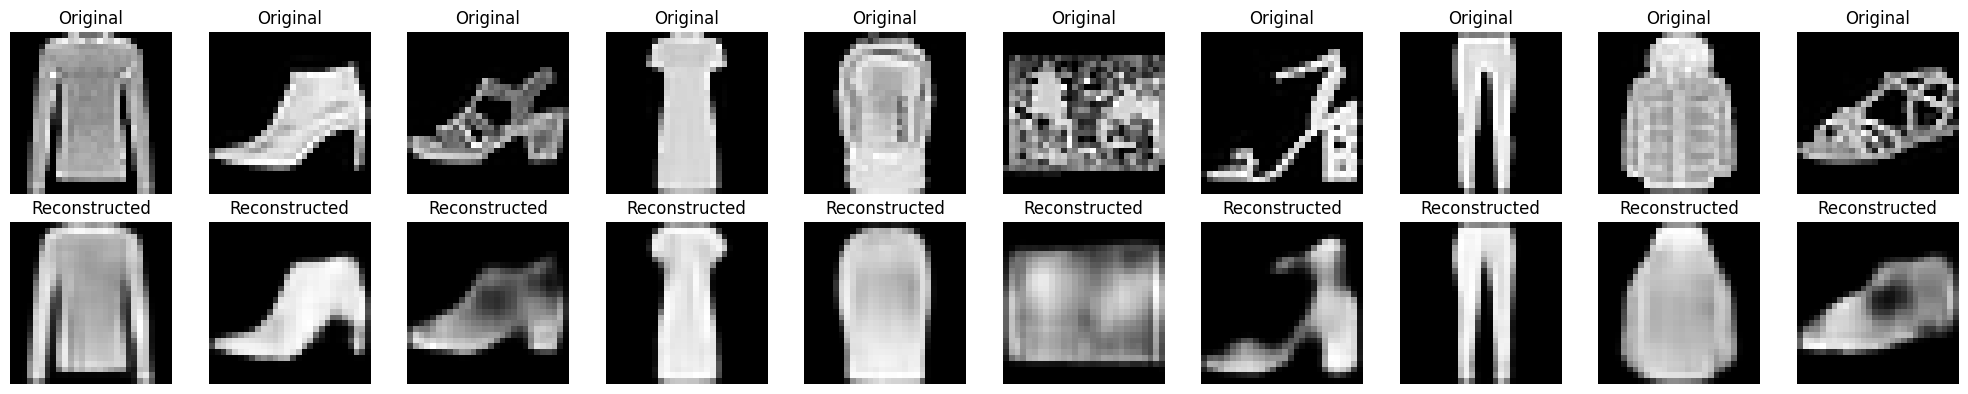

In [ ]:
visualize_reconstructions(convolutional_autoencoder_model_v1, temp_loader, device)

In [ ]:
class ConvolutionalAutoEncoder_v2(nn.Module):
    def __init__(self): #64x1x1
        super(ConvolutionalAutoEncoder_v2, self).__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(1, 16, 3, stride=2, padding=1),
            nn.ReLU(),
            nn.Conv2d(16, 32, 3, stride=2, padding=1),
            nn.ReLU(),
            nn.Conv2d(32, 64, 7)
        )


        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(64, 32, 7),
            nn.ReLU(),
            nn.ConvTranspose2d(32, 16, 3, stride=2, padding=1, output_padding=1),
            nn.ReLU(),
            nn.ConvTranspose2d(16, 1, 3, stride=2, padding=1, output_padding=1),
            nn.Sigmoid()
        )

    def forward(self, x):
        if len(x.shape) == 2:
            x = x.view(-1, 1, 28, 28)
        return self.decoder(self.encoder(x))

In [ ]:
convolutional_autoencoder_model_v2 = ConvolutionalAutoEncoder_v2().to(device)
convolutional_autoencoder_v2_optimizer = optim.Adam(convolutional_autoencoder_model_v2.parameters(), lr=1e-4)
early_stop = EarlyStopping(patience=10, min_delta=0.0001, verbose=False, path='convolutional_autoencoder_model_v2.pth')

In [ ]:
history_dictionary["ConvolutionalAutoEncoder_v2"] = perform_learning(convolutional_autoencoder_model_v2, 100, convolutional_autoencoder_v2_optimizer, train_loader, val_loader, device, early_stop)

Epoch [1/100] - 2.43s
  Train MSE Loss: 0.1262 | Val MSE Loss: 0.0951
--------------------------------------------------
Epoch [2/100] - 2.24s
  Train MSE Loss: 0.0803 | Val MSE Loss: 0.0550
--------------------------------------------------
Epoch [3/100] - 2.30s
  Train MSE Loss: 0.0440 | Val MSE Loss: 0.0355
--------------------------------------------------
Epoch [4/100] - 2.68s
  Train MSE Loss: 0.0311 | Val MSE Loss: 0.0284
--------------------------------------------------
Epoch [5/100] - 2.21s
  Train MSE Loss: 0.0267 | Val MSE Loss: 0.0253
--------------------------------------------------
Epoch [6/100] - 2.15s
  Train MSE Loss: 0.0241 | Val MSE Loss: 0.0229
--------------------------------------------------
Epoch [7/100] - 2.14s
  Train MSE Loss: 0.0220 | Val MSE Loss: 0.0210
--------------------------------------------------
Epoch [8/100] - 2.17s
  Train MSE Loss: 0.0203 | Val MSE Loss: 0.0197
--------------------------------------------------
Epoch [9/100] - 2.50s
  Train MS

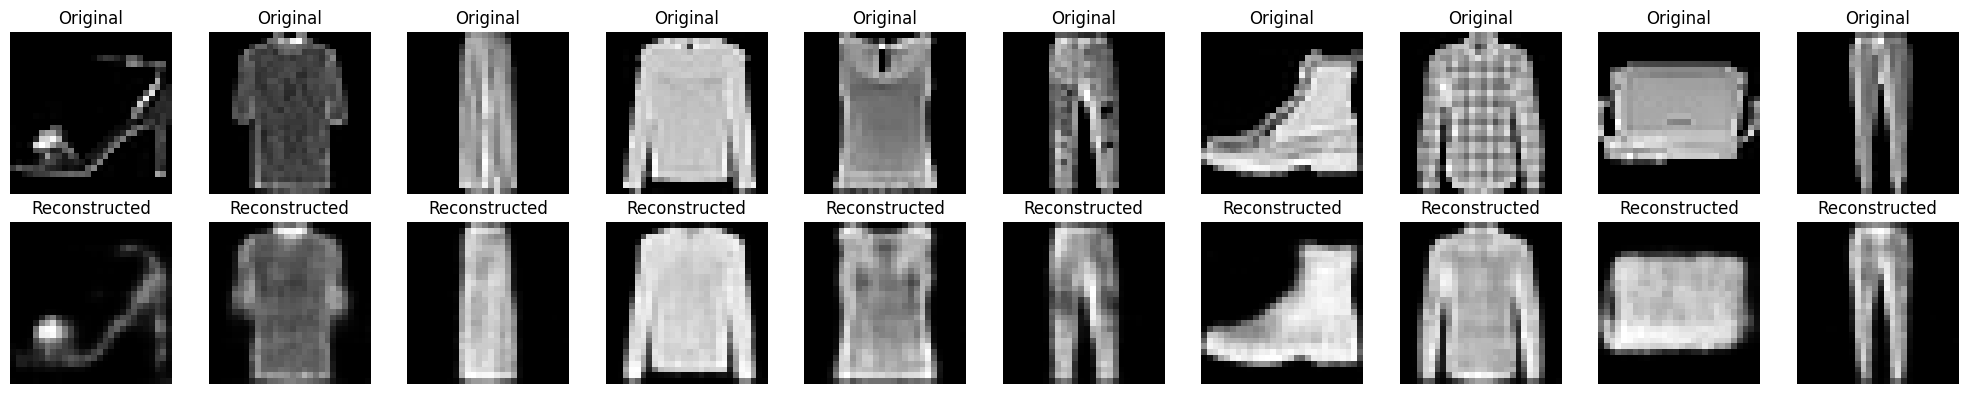

In [ ]:
visualize_reconstructions(convolutional_autoencoder_model_v2, temp_loader, device)

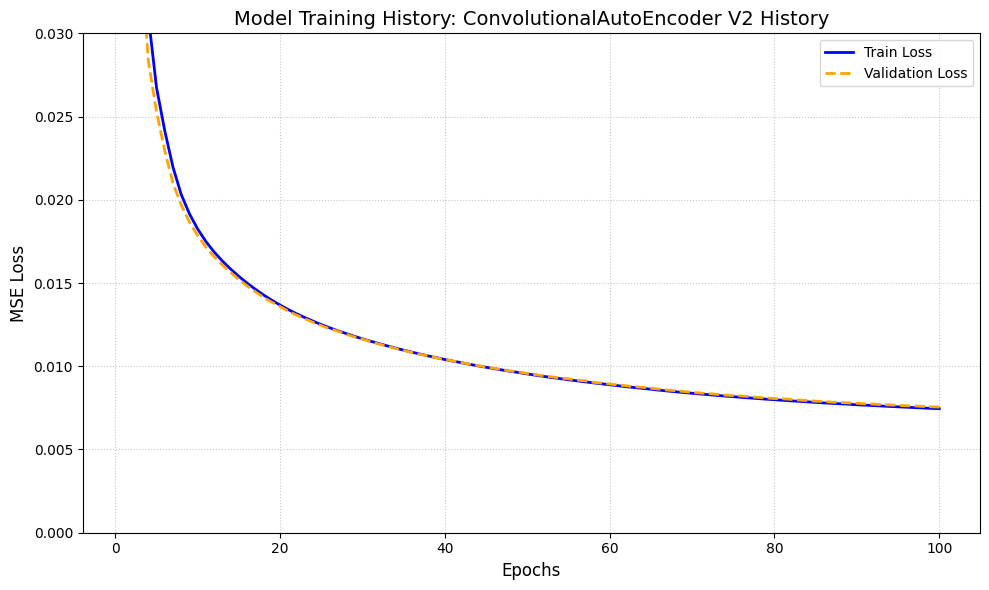

In [ ]:
plot_history(history_dictionary['ConvolutionalAutoEncoder_v2'], "ConvolutionalAutoEncoder V2 History", (0, 0.03))

In [ ]:
class ConvolutionalAutoEncoder_v3(nn.Module):
    def __init__(self): #128x4x4
        super(ConvolutionalAutoEncoder_v3, self).__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2, padding=1)
        )

        self.decoder = nn.Sequential(
            nn.Conv2d(128, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Upsample(scale_factor=2),

            nn.Conv2d(64, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Upsample(scale_factor=2),

            nn.Conv2d(32, 32, kernel_size=3, padding=0),
            nn.ReLU(),
            nn.Upsample(scale_factor=2),

            nn.Conv2d(32, 1, kernel_size=3, padding=1),
            nn.Sigmoid()
        )

    def forward(self, x):
        if len(x.shape) == 2:
            x = x.view(-1, 1, 28, 28)
        return self.decoder(self.encoder(x))

In [ ]:
convolutional_autoencoder_model_v3 = ConvolutionalAutoEncoder_v3().to(device)
convolutional_autoencoder_v3_optimizer = optim.Adam(convolutional_autoencoder_model_v3.parameters(), lr=1e-4)
early_stop = EarlyStopping(patience=10, min_delta=0.0001, verbose=False, path='convolutional_autoencoder_model_v3.pth')

In [ ]:
history_dictionary["ConvolutionalAutoEncoder_v3"] = perform_learning(convolutional_autoencoder_model_v3, 100, convolutional_autoencoder_v3_optimizer, train_loader, val_loader, device, early_stop)

Epoch [1/100] - 5.52s
  Train MSE Loss: 0.0585 | Val MSE Loss: 0.0276
--------------------------------------------------
Epoch [2/100] - 4.17s
  Train MSE Loss: 0.0246 | Val MSE Loss: 0.0217
--------------------------------------------------
Epoch [3/100] - 4.34s
  Train MSE Loss: 0.0206 | Val MSE Loss: 0.0198
--------------------------------------------------
Epoch [4/100] - 4.32s
  Train MSE Loss: 0.0189 | Val MSE Loss: 0.0178
--------------------------------------------------
Epoch [5/100] - 4.27s
  Train MSE Loss: 0.0174 | Val MSE Loss: 0.0167
--------------------------------------------------
Epoch [6/100] - 4.49s
  Train MSE Loss: 0.0163 | Val MSE Loss: 0.0159
--------------------------------------------------
Epoch [7/100] - 4.27s
  Train MSE Loss: 0.0157 | Val MSE Loss: 0.0160
--------------------------------------------------
Epoch [8/100] - 4.22s
  Train MSE Loss: 0.0150 | Val MSE Loss: 0.0155
--------------------------------------------------
Epoch [9/100] - 4.44s
  Train MS

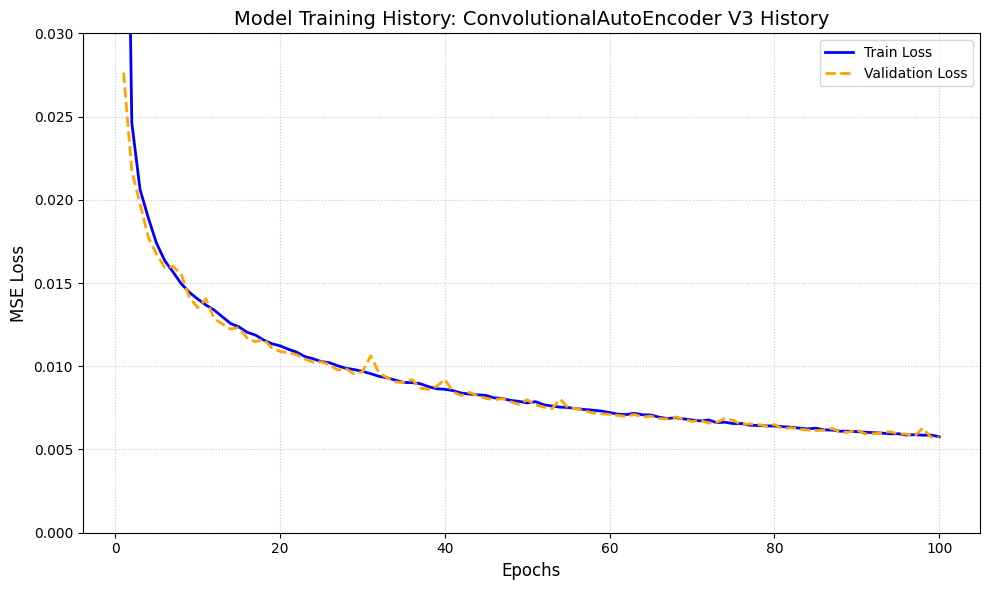

In [ ]:
plot_history(history_dictionary['ConvolutionalAutoEncoder_v3'], "ConvolutionalAutoEncoder V3 History", (0, 0.03))

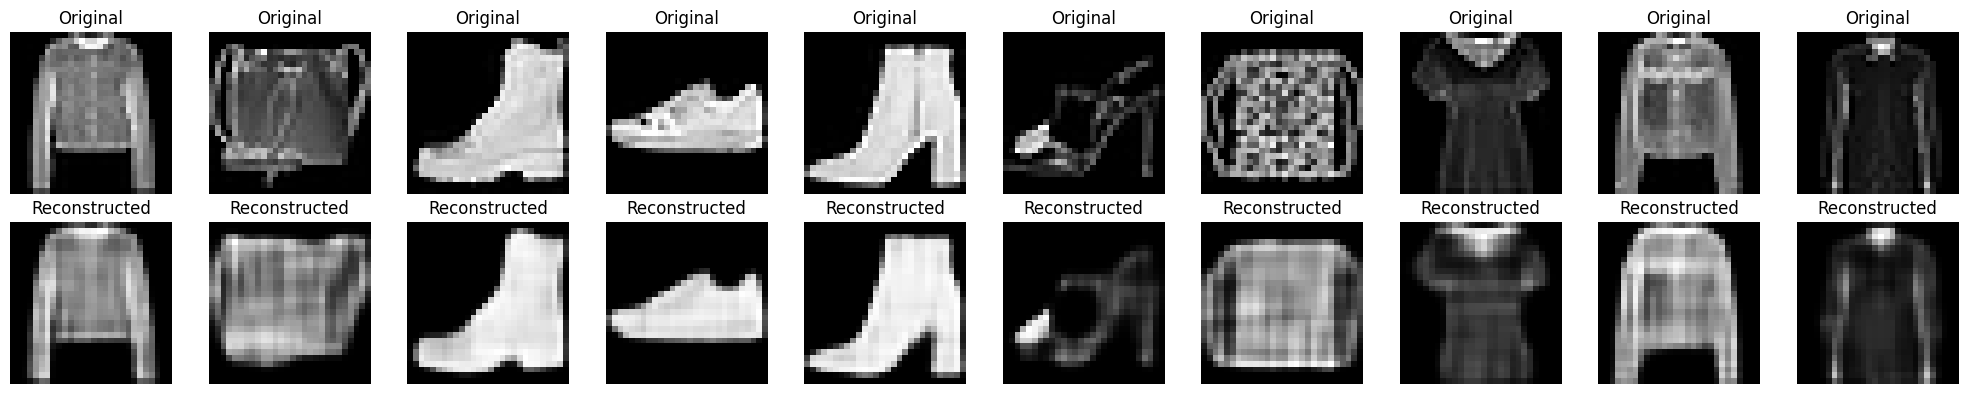

In [ ]:
visualize_reconstructions(convolutional_autoencoder_model_v3, temp_loader, device)

In [ ]:
class ResidualBlock(nn.Module):
    def __init__(self, channels):
        super(ResidualBlock, self).__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(channels, channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(channels),
            nn.ReLU(),
            nn.Conv2d(channels, channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(channels)
        )
        self.relu = nn.ReLU()

    def forward(self, x):
        residual = x
        out = self.conv(x)
        out += residual
        return self.relu(out)

class ResidualAutoEncoder_v4(nn.Module):
    def __init__(self):
        super(ResidualAutoEncoder_v4, self).__init__()

        self.encoder = nn.Sequential(
            nn.Conv2d(1, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            ResidualBlock(64),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            ResidualBlock(128),

            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2, padding=1)
        )

        self.decoder = nn.Sequential(
            nn.Conv2d(256, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Upsample(scale_factor=2),

            ResidualBlock(128),

            nn.Conv2d(128, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Upsample(scale_factor=2),

            ResidualBlock(64),

            nn.Conv2d(64, 32, kernel_size=3, padding=0),
            nn.ReLU(),
            nn.Upsample(scale_factor=2),

            nn.Conv2d(32, 1, kernel_size=3, padding=1),
            nn.Sigmoid()
        )

    def forward(self, x):
        if len(x.shape) == 2: x = x.view(-1, 1, 28, 28)
        return self.decoder(self.encoder(x))

In [ ]:
convolutional_autoencoder_model_v4 = ResidualAutoEncoder_v4().to(device)
convolutional_autoencoder_v4_optimizer = optim.Adam(convolutional_autoencoder_model_v4.parameters(), lr=1e-4)
early_stop = EarlyStopping(patience=10, min_delta=0.0001, verbose=False, path='convolutional_autoencoder_model_v4.pth')

In [ ]:
convolutional_autoencoder_model_v4.load_state_dict(torch.load("convolutional_autoencoder_model_v4.pth"))

<All keys matched successfully>

In [ ]:
history_dictionary["ConvolutionalAutoEncoder_v4"] = perform_learning(convolutional_autoencoder_model_v4, 100, convolutional_autoencoder_v4_optimizer, train_loader, val_loader, device, early_stop)

Epoch [1/100] - 12.57s
  Train MSE Loss: 0.0279 | Val MSE Loss: 0.0146
--------------------------------------------------
Epoch [2/100] - 13.13s
  Train MSE Loss: 0.0130 | Val MSE Loss: 0.0114
--------------------------------------------------
Epoch [3/100] - 13.79s
  Train MSE Loss: 0.0106 | Val MSE Loss: 0.0097
--------------------------------------------------
Epoch [4/100] - 12.87s
  Train MSE Loss: 0.0093 | Val MSE Loss: 0.0091
--------------------------------------------------
Epoch [5/100] - 12.51s
  Train MSE Loss: 0.0082 | Val MSE Loss: 0.0080
--------------------------------------------------
Epoch [6/100] - 12.50s
  Train MSE Loss: 0.0077 | Val MSE Loss: 0.0073
--------------------------------------------------
Epoch [7/100] - 12.91s
  Train MSE Loss: 0.0071 | Val MSE Loss: 0.0071
--------------------------------------------------
Epoch [8/100] - 12.84s
  Train MSE Loss: 0.0067 | Val MSE Loss: 0.0066
--------------------------------------------------
Epoch [9/100] - 12.98s
 

In [ ]:
convolutional_autoencoder_model_v4.load_state_dict(torch.load("convolutional_autoencoder_model_v4.pth"))

<All keys matched successfully>

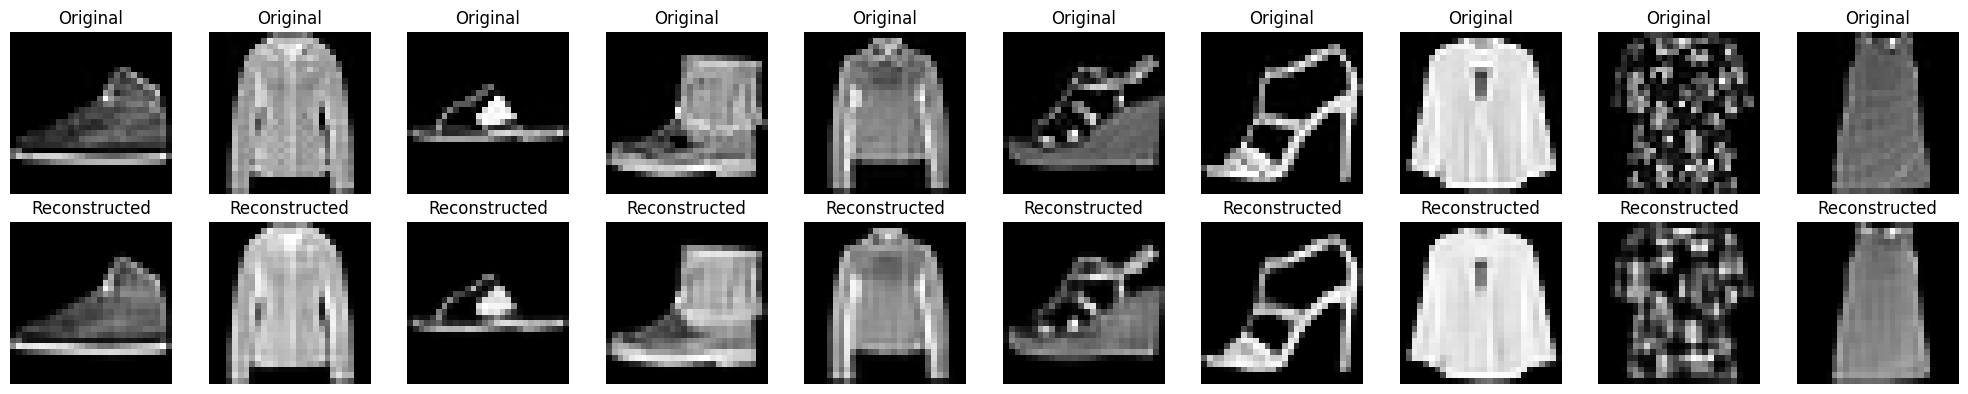

In [ ]:
visualize_reconstructions(convolutional_autoencoder_model_v4, temp_loader, device)

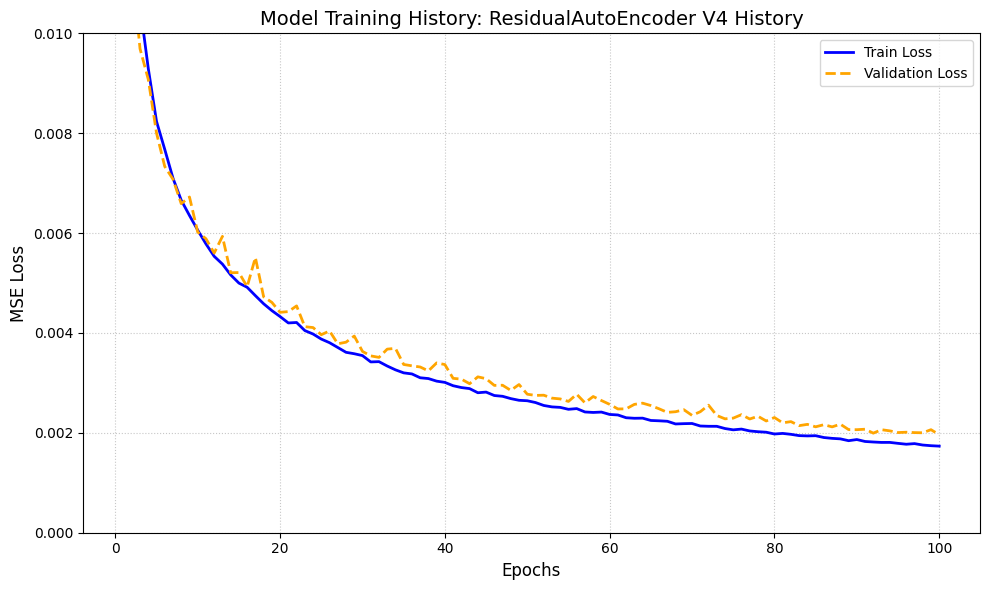

In [ ]:
plot_history(history_dictionary['ConvolutionalAutoEncoder_v4'], "ResidualAutoEncoder V4 History", (0, 0.01))

In [ ]:
torch.save(history_dictionary, 'autoencoders_history.pt')

In [ ]:
history = torch.load('autoencoders_history.pt')

In [ ]:
def add_gaussian_noise(images, std=0.1):
    noisy = images + torch.randn_like(images) * std
    return torch.clamp(noisy, 0., 1.)

def add_speckle_noise(images, std=0.1):
    noise = torch.randn_like(images) * std
    noisy = images + images * noise
    return torch.clamp(noisy, 0., 1.)

def add_salt_and_pepper_noise(images, amount=0.1):
    noisy_images = images.clone()
    salt = torch.rand_like(noisy_images) < (amount / 2)
    pepper = torch.rand_like(noisy_images) < (amount / 2)
    noisy_images[salt] = 1.0
    noisy_images[pepper] = 0.0
    return noisy_images

In [ ]:
def evaluate_denoising_model(model, loader, device, noise_function, noise_parameter):
    model.eval()
    running_loss = 0.0
    criterion = nn.MSELoss()
    with torch.no_grad():
        for images, _ in loader:
            images = images.to(device)
            noisy_images = noise_function(images, noise_parameter)
            outputs = model(noisy_images)
            loss = criterion(outputs, images.view_as(outputs))
            running_loss += loss.item()
    epoch_loss = running_loss / len(loader)
    return epoch_loss

In [ ]:
def perform_denoising_learning(model, EPOCHS, optimizer, train_loader, val_loader, device, noise_function, noise_parameter, early_stopping=None):
    history = {
         'train_loss': [],
         'val_loss': []
     }
    criterion = nn.MSELoss()

    for epoch in range(EPOCHS):
        model.train()
        start_time = time.time()
        running_loss = 0.0
        for images, _ in train_loader:
            images = images.to(device)
            noisy_images = noise_function(images, noise_parameter)

            optimizer.zero_grad()
            outputs = model(noisy_images)

            loss = criterion(outputs, images.view_as(outputs))
            loss.backward()
            optimizer.step()
            running_loss += loss.item()

        epoch_loss = running_loss / len(train_loader)
        val_loss = evaluate_denoising_model(model, val_loader, device, noise_function, noise_parameter)
        end_time = time.time()
        epoch_duration = end_time - start_time
        history['train_loss'].append(epoch_loss)
        history['val_loss'].append(val_loss)

        print(f"Epoch [{epoch+1}/{EPOCHS}] - {epoch_duration:.2f}s")
        print(f"  Train MSE Loss: {epoch_loss:.4f} | Val MSE Loss: {val_loss:.4f}")

        if early_stopping:
            early_stopping(val_loss, model)
            if early_stopping.early_stop:
              break

    return history


In [ ]:
def visualize_denoising(model, loader, device, noise_function, noise_parameter, n=5):
    model.eval()
    with torch.no_grad():
        images, _ = next(iter(loader))
        images = images.to(device)
        noisy_images = noise_function(images, noise_parameter)
        reconstructed = model(noisy_images)

        plt.figure(figsize=(15, 10))
        for i in range(n):
            ax = plt.subplot(3, n, i + 1)
            plt.imshow(images[i].cpu().reshape(28, 28), cmap='gray')
            if i == 0: ax.set_title("Original", fontsize=14, loc='left', pad=10)
            plt.axis('off')

            ax = plt.subplot(3, n, i + 1 + n)
            plt.imshow(noisy_images[i].cpu().reshape(28, 28), cmap='gray')
            if i == 0: ax.set_title("Noisy Input", fontsize=14, loc='left', pad=10)
            plt.axis('off')

            ax = plt.subplot(3, n, i + 1 + 2 * n)
            plt.imshow(reconstructed[i].cpu().reshape(28, 28), cmap='gray')
            if i == 0: ax.set_title("Reconstructed", fontsize=14, loc='left', pad=10)
            plt.axis('off')

        plt.tight_layout()
        plt.show()

In [ ]:
def plot_denoising_history(history, model_name, noise_name, ylim=None, log_scale=False, start_epoch=0):
    plt.figure(figsize=(10, 6))


    train_loss = history['train_loss'][start_epoch:]
    val_loss = history['val_loss'][start_epoch:]
    epochs = range(start_epoch + 1, start_epoch + len(train_loss) + 1)

    plt.plot(epochs, train_loss, label='Train MSE Loss', color='#1f77b4', linewidth=2.5)
    plt.plot(epochs, val_loss, label='Validation MSE Loss', color='#ff7f0e', linestyle='--', linewidth=2.5)

    if log_scale:
        plt.yscale('log')
        plt.ylabel('MSE Loss (Log Scale)', fontsize=12, fontweight='bold')
    else:
        plt.ylabel('MSE Loss', fontsize=12, fontweight='bold')

    if ylim:
        plt.ylim(ylim)

    plt.title(f'Denoising Training History\nModel: {model_name} | Noise: {noise_name}', fontsize=14, fontweight='bold')
    plt.xlabel('Epochs', fontsize=12, fontweight='bold')
    plt.grid(True, which="both", linestyle=':', alpha=0.5)
    plt.legend(frameon=True, shadow=True, loc='upper right')

    min_val_loss = min(val_loss)
    plt.axhline(y=min_val_loss, color='r', linestyle=':', alpha=0.3, label=f'Min Val Loss: {min_val_loss:.5f}')

    plt.tight_layout()
    plt.show()

In [ ]:
models_config = {
    "Deep_v3": DeepAutoEncoder_v3,
    "Conv_v3": ConvolutionalAutoEncoder_v3,
    "Res_v4": ResidualAutoEncoder_v4
}

noise_functions = {
    "Gaussian": add_gaussian_noise,
    "Salt_And_Pepper": add_salt_and_pepper_noise,
    "Speckle": add_speckle_noise
}

denoising_history_01 = {noise: {} for noise in noise_functions.keys()}
denoising_history_03 = {noise: {} for noise in noise_functions.keys()}


EXPERIMENT: Noise Type = Gaussian

--- Training Deep_v3 on Gaussian noise ---
Epoch [1/100] - 3.35s
  Train MSE Loss: 0.0581 | Val MSE Loss: 0.0315
Epoch [2/100] - 2.26s
  Train MSE Loss: 0.0264 | Val MSE Loss: 0.0231
Epoch [3/100] - 2.11s
  Train MSE Loss: 0.0221 | Val MSE Loss: 0.0207
Epoch [4/100] - 2.14s
  Train MSE Loss: 0.0198 | Val MSE Loss: 0.0186
Epoch [5/100] - 2.15s
  Train MSE Loss: 0.0182 | Val MSE Loss: 0.0177
Epoch [6/100] - 2.24s
  Train MSE Loss: 0.0170 | Val MSE Loss: 0.0164
Epoch [7/100] - 2.56s
  Train MSE Loss: 0.0160 | Val MSE Loss: 0.0156
Epoch [8/100] - 2.17s
  Train MSE Loss: 0.0153 | Val MSE Loss: 0.0151
Epoch [9/100] - 2.16s
  Train MSE Loss: 0.0146 | Val MSE Loss: 0.0144
Epoch [10/100] - 2.13s
  Train MSE Loss: 0.0140 | Val MSE Loss: 0.0136
Epoch [11/100] - 2.19s
  Train MSE Loss: 0.0135 | Val MSE Loss: 0.0133
Epoch [12/100] - 2.58s
  Train MSE Loss: 0.0131 | Val MSE Loss: 0.0129
Epoch [13/100] - 2.25s
  Train MSE Loss: 0.0127 | Val MSE Loss: 0.0128
Epoch [

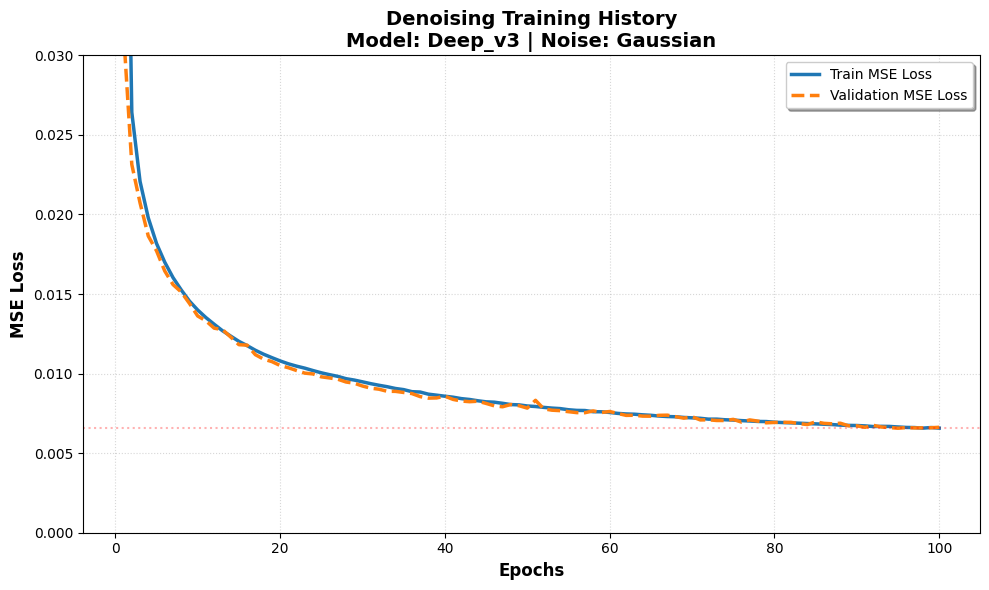

Visual results for Deep_v3 (Gaussian):


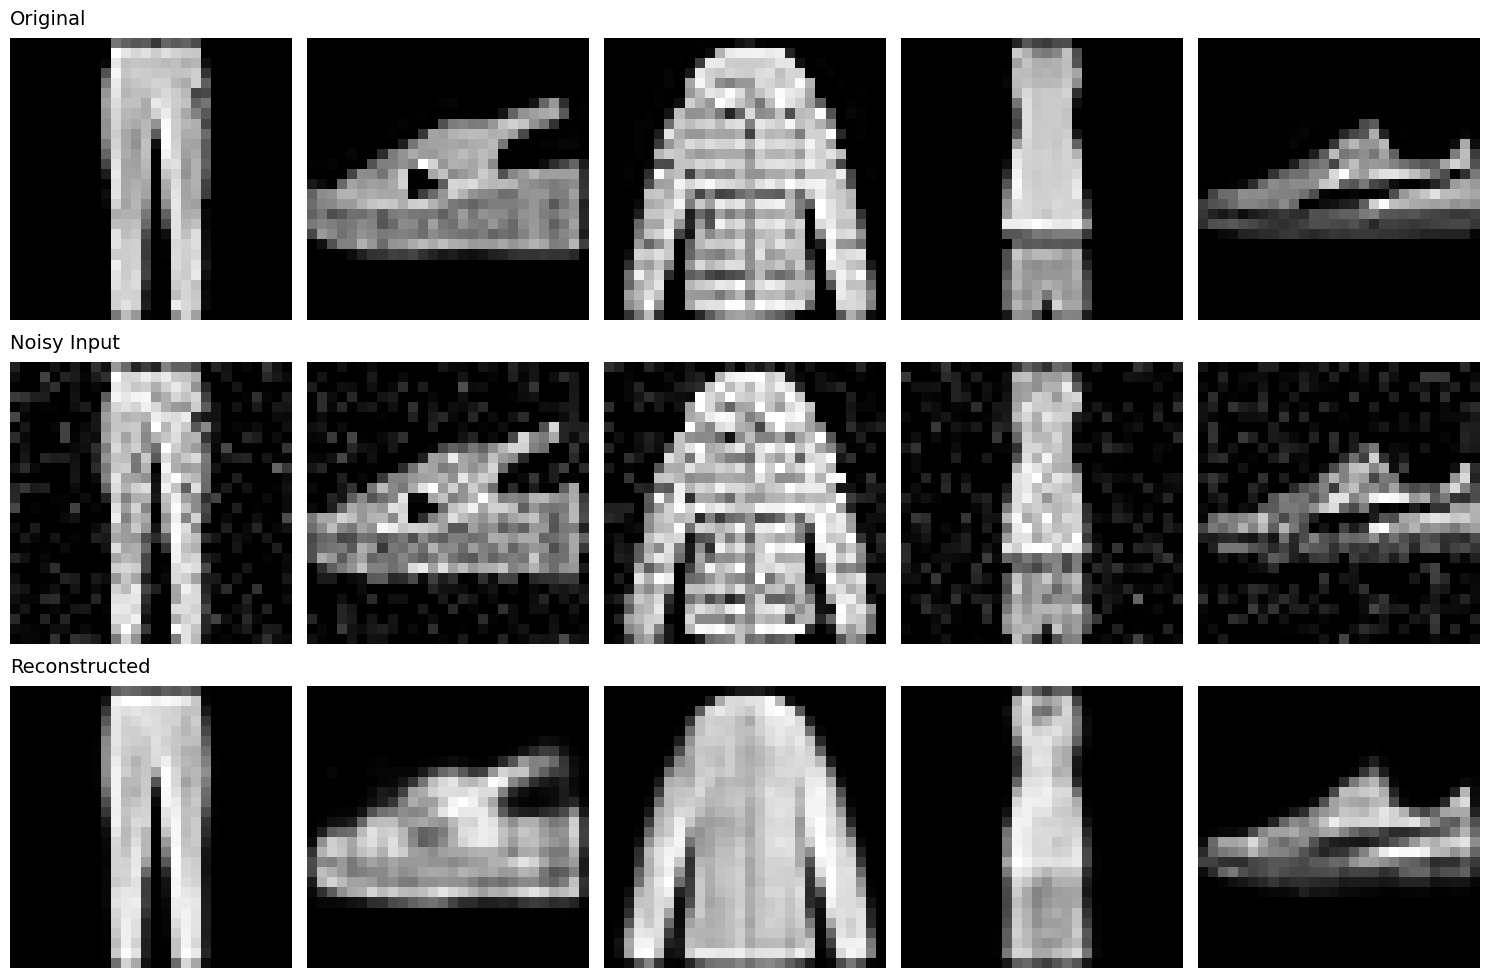


--- Training Conv_v3 on Gaussian noise ---
Epoch [1/100] - 4.96s
  Train MSE Loss: 0.0274 | Val MSE Loss: 0.0169
Epoch [2/100] - 4.82s
  Train MSE Loss: 0.0148 | Val MSE Loss: 0.0133
Epoch [3/100] - 4.76s
  Train MSE Loss: 0.0123 | Val MSE Loss: 0.0114
Epoch [4/100] - 4.92s
  Train MSE Loss: 0.0111 | Val MSE Loss: 0.0103
Epoch [5/100] - 4.73s
  Train MSE Loss: 0.0102 | Val MSE Loss: 0.0095
Epoch [6/100] - 4.74s
  Train MSE Loss: 0.0095 | Val MSE Loss: 0.0093
Epoch [7/100] - 4.79s
  Train MSE Loss: 0.0088 | Val MSE Loss: 0.0088
Epoch [8/100] - 4.61s
  Train MSE Loss: 0.0086 | Val MSE Loss: 0.0080
Epoch [9/100] - 4.79s
  Train MSE Loss: 0.0081 | Val MSE Loss: 0.0078
Epoch [10/100] - 4.58s
  Train MSE Loss: 0.0078 | Val MSE Loss: 0.0080
Epoch [11/100] - 4.53s
  Train MSE Loss: 0.0075 | Val MSE Loss: 0.0070
Epoch [12/100] - 4.75s
  Train MSE Loss: 0.0073 | Val MSE Loss: 0.0072
Epoch [13/100] - 4.53s
  Train MSE Loss: 0.0070 | Val MSE Loss: 0.0066
Epoch [14/100] - 4.59s
  Train MSE Loss: 0

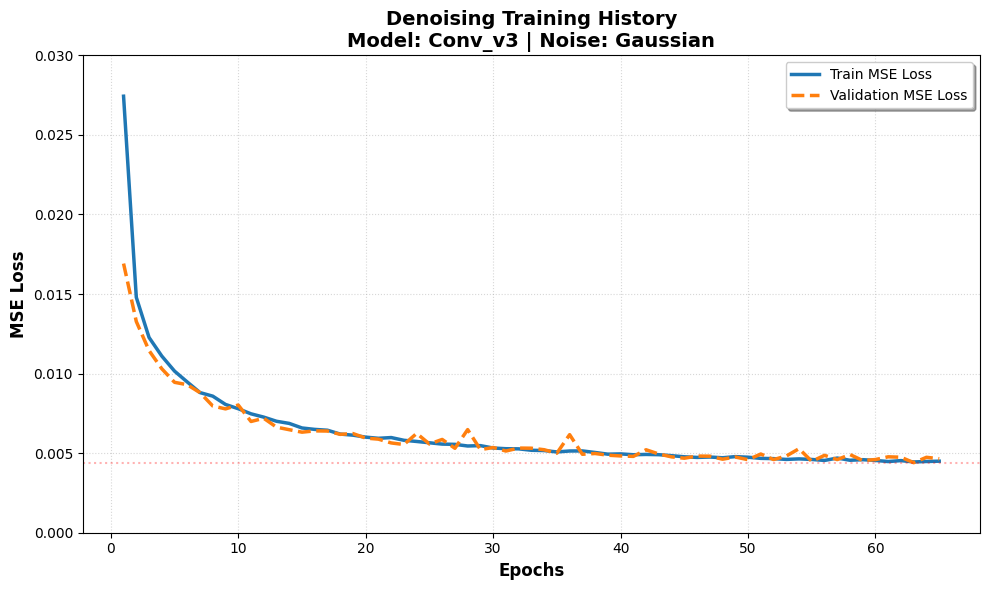

Visual results for Conv_v3 (Gaussian):


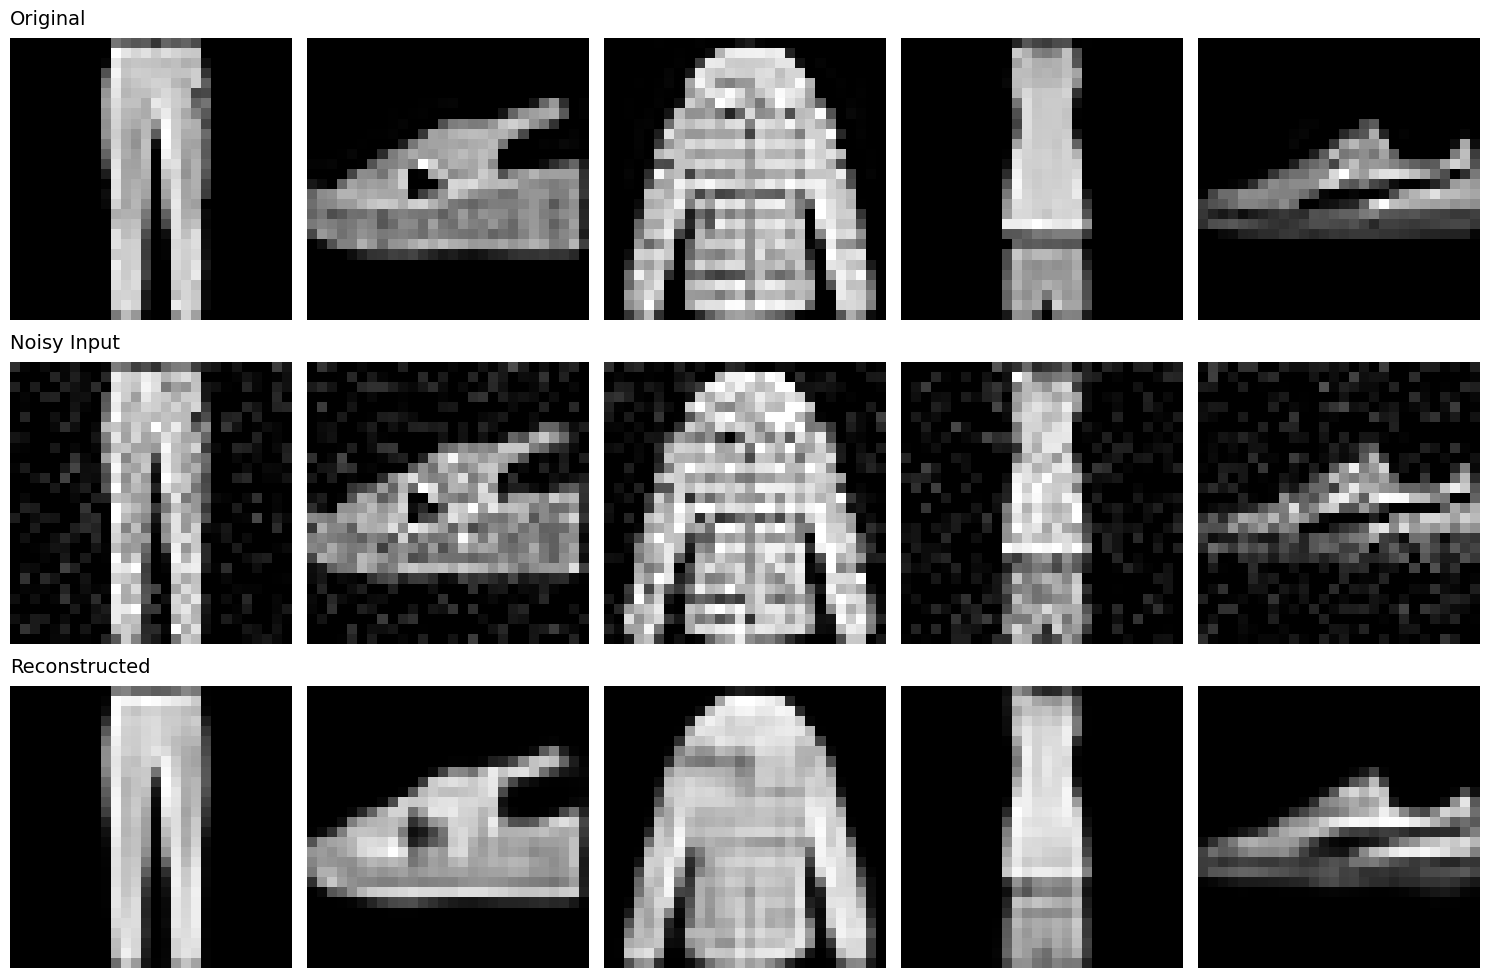


--- Training Res_v4 on Gaussian noise ---
Epoch [1/100] - 14.04s
  Train MSE Loss: 0.0198 | Val MSE Loss: 0.0127
Epoch [2/100] - 14.03s
  Train MSE Loss: 0.0098 | Val MSE Loss: 0.0084
Epoch [3/100] - 14.22s
  Train MSE Loss: 0.0077 | Val MSE Loss: 0.0074
Epoch [4/100] - 14.02s
  Train MSE Loss: 0.0067 | Val MSE Loss: 0.0083
Epoch [5/100] - 14.05s
  Train MSE Loss: 0.0061 | Val MSE Loss: 0.0066
Epoch [6/100] - 14.10s
  Train MSE Loss: 0.0055 | Val MSE Loss: 0.0069
Epoch [7/100] - 14.12s
  Train MSE Loss: 0.0052 | Val MSE Loss: 0.0049
Epoch [8/100] - 14.15s
  Train MSE Loss: 0.0047 | Val MSE Loss: 0.0051
Epoch [9/100] - 14.15s
  Train MSE Loss: 0.0046 | Val MSE Loss: 0.0049
Epoch [10/100] - 14.13s
  Train MSE Loss: 0.0045 | Val MSE Loss: 0.0061
Epoch [11/100] - 14.09s
  Train MSE Loss: 0.0042 | Val MSE Loss: 0.0041
Epoch [12/100] - 14.09s
  Train MSE Loss: 0.0041 | Val MSE Loss: 0.0044
Epoch [13/100] - 14.11s
  Train MSE Loss: 0.0040 | Val MSE Loss: 0.0048
Epoch [14/100] - 14.18s
  Trai

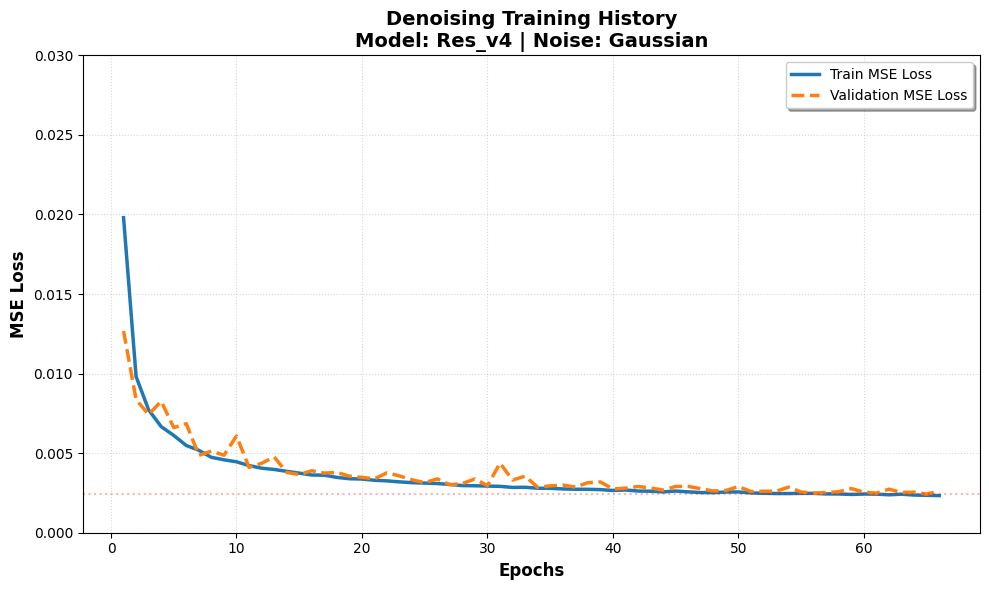

Visual results for Res_v4 (Gaussian):


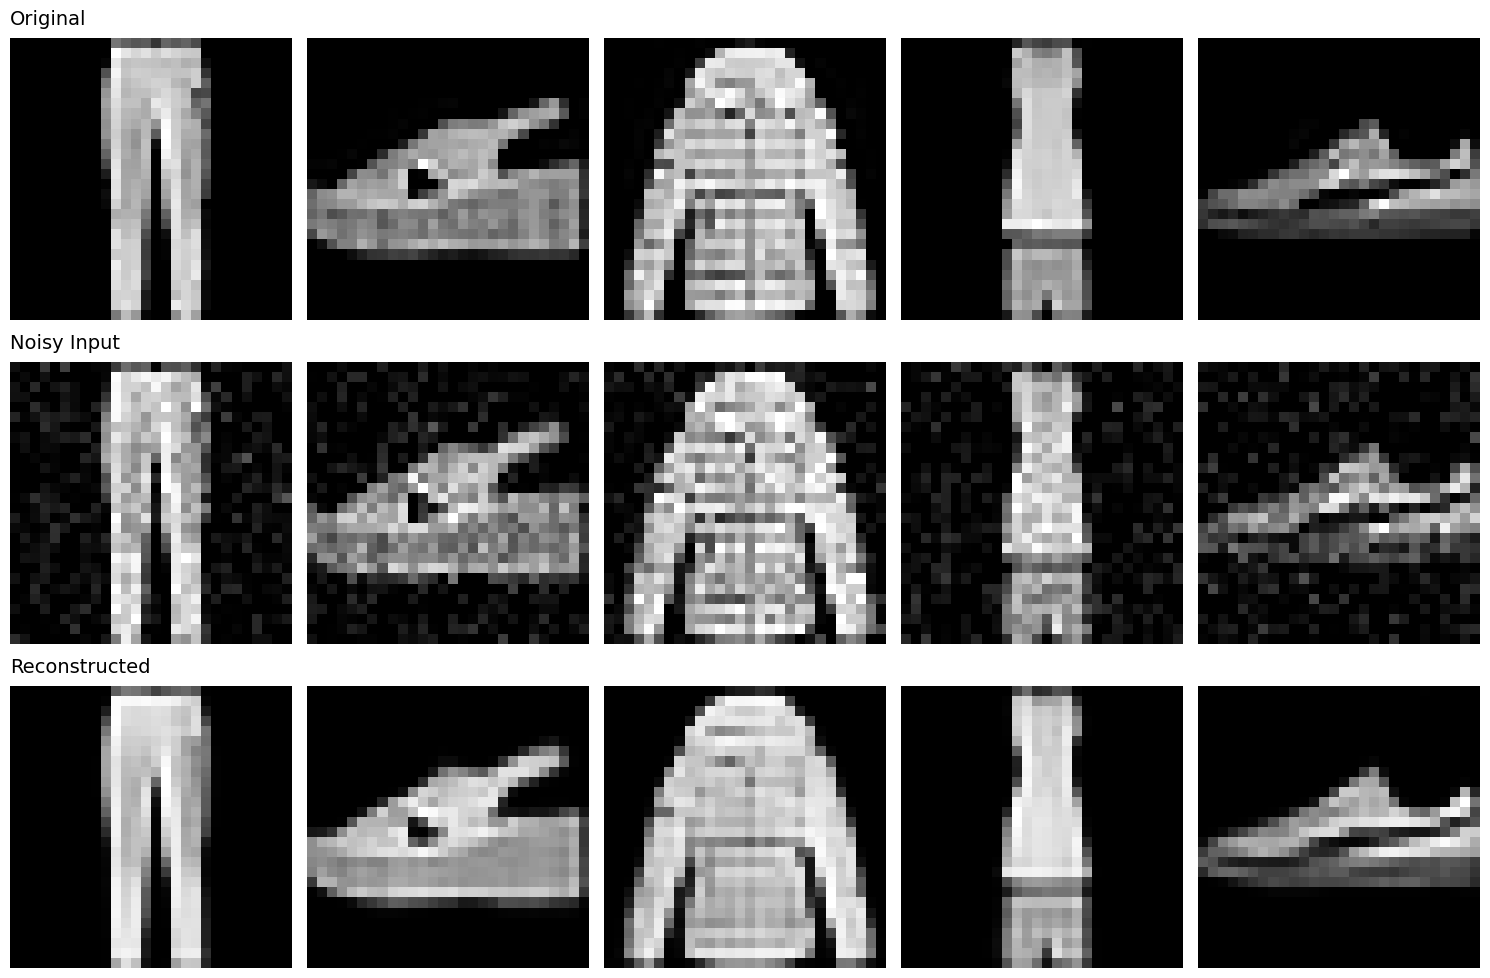

In [ ]:
EPOCHS = 100
LR = 1e-3
PARAM = 0.1

noise_name = "Gaussian"
noise_fn = noise_functions[noise_name]
print(f"\n{'='*30}\nEXPERIMENT: Noise Type = {noise_name}\n{'='*30}")

for model_name, model_class in models_config.items():
    print(f"\n--- Training {model_name} on {noise_name} noise ---")

    model = model_class().to(device)
    optimizer = optim.Adam(model.parameters(), lr=LR)

    early_stop = EarlyStopping(patience=10, min_delta=0.0001, verbose=False,
                                path=f"Denoising_{model_name}_{noise_name}_01.pth")

    history = perform_denoising_learning(
        model, EPOCHS, optimizer, train_loader, val_loader, device,
        noise_function=noise_fn,
        noise_parameter=PARAM,
        early_stopping=early_stop
    )

    denoising_history_01[noise_name][model_name] = {
        "history": history,
        "model_state": model.state_dict()
    }

    plot_denoising_history(history, model_name, noise_name, (0, 0.03))

    print(f"Visual results for {model_name} ({noise_name}):")
    visualize_denoising(model, val_loader, device, noise_fn, PARAM, n=5)

    del model
    torch.cuda.empty_cache()

In [ ]:
torch.save(denoising_history_01, 'history_gauss_01.pt')

In [ ]:
denoising_history_01 = torch.load('history_gauss_01.pt')


EXPERIMENT: Noise Type = Salt_And_Pepper

--- Training Deep_v3 on Salt_And_Pepper noise ---
Epoch [1/100] - 2.57s
  Train MSE Loss: 0.0583 | Val MSE Loss: 0.0345
Epoch [2/100] - 1.98s
  Train MSE Loss: 0.0293 | Val MSE Loss: 0.0252
Epoch [3/100] - 2.00s
  Train MSE Loss: 0.0233 | Val MSE Loss: 0.0222
Epoch [4/100] - 2.03s
  Train MSE Loss: 0.0213 | Val MSE Loss: 0.0204
Epoch [5/100] - 2.46s
  Train MSE Loss: 0.0195 | Val MSE Loss: 0.0190
Epoch [6/100] - 2.00s
  Train MSE Loss: 0.0183 | Val MSE Loss: 0.0180
Epoch [7/100] - 2.03s
  Train MSE Loss: 0.0175 | Val MSE Loss: 0.0175
Epoch [8/100] - 2.00s
  Train MSE Loss: 0.0168 | Val MSE Loss: 0.0165
Epoch [9/100] - 2.01s
  Train MSE Loss: 0.0162 | Val MSE Loss: 0.0160
Epoch [10/100] - 2.10s
  Train MSE Loss: 0.0156 | Val MSE Loss: 0.0155
Epoch [11/100] - 2.39s
  Train MSE Loss: 0.0152 | Val MSE Loss: 0.0151
Epoch [12/100] - 1.98s
  Train MSE Loss: 0.0148 | Val MSE Loss: 0.0148
Epoch [13/100] - 2.00s
  Train MSE Loss: 0.0144 | Val MSE Loss: 

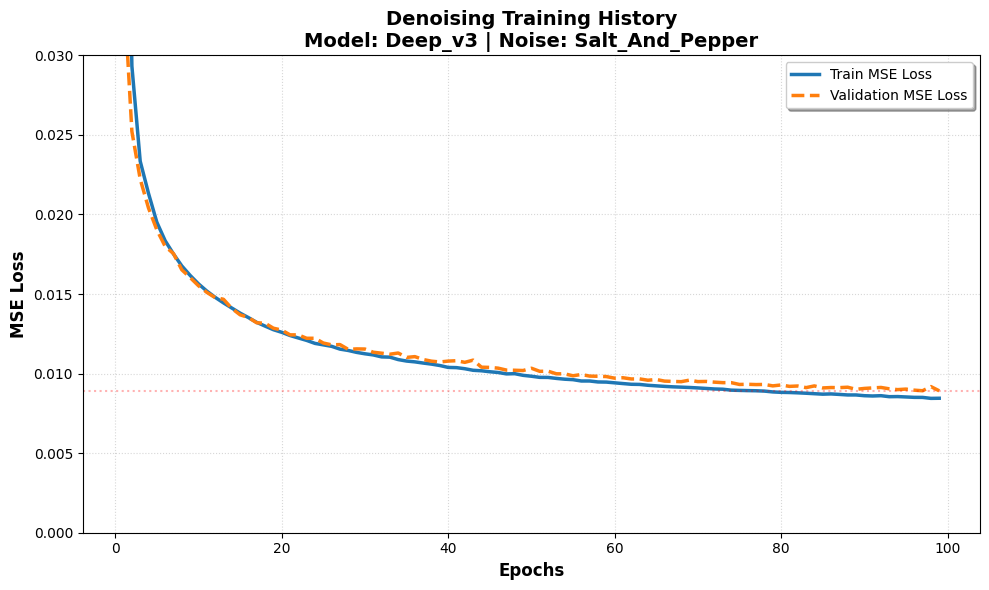

Visual results for Deep_v3 (Salt_And_Pepper):


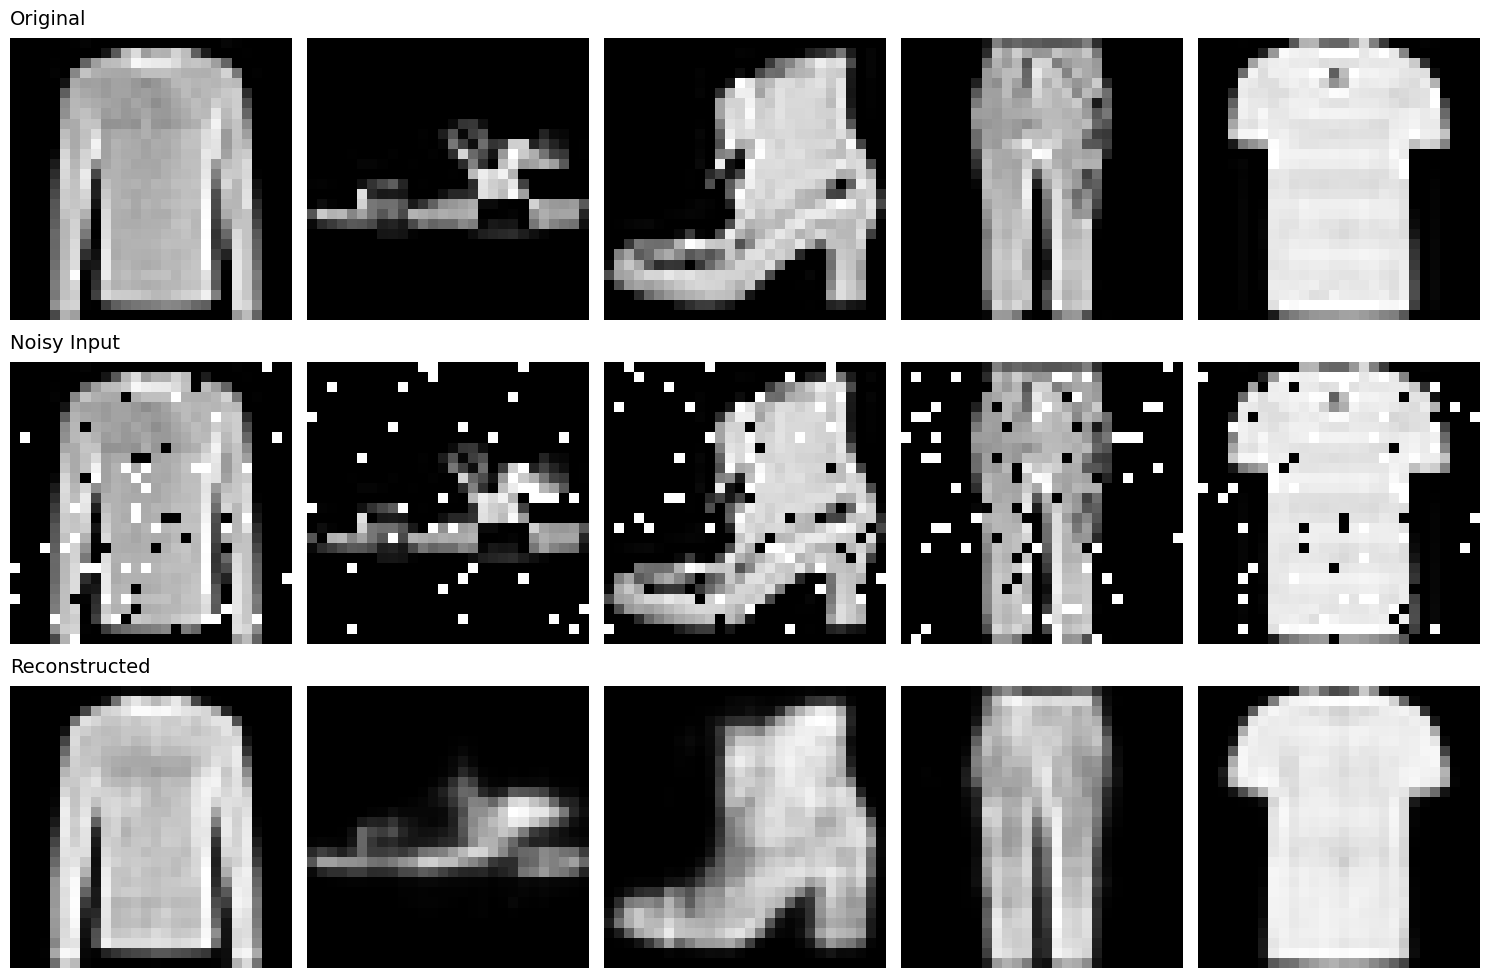


--- Training Conv_v3 on Salt_And_Pepper noise ---
Epoch [1/100] - 5.01s
  Train MSE Loss: 0.0317 | Val MSE Loss: 0.0190
Epoch [2/100] - 3.96s
  Train MSE Loss: 0.0174 | Val MSE Loss: 0.0156
Epoch [3/100] - 4.23s
  Train MSE Loss: 0.0148 | Val MSE Loss: 0.0141
Epoch [4/100] - 3.98s
  Train MSE Loss: 0.0134 | Val MSE Loss: 0.0127
Epoch [5/100] - 3.99s
  Train MSE Loss: 0.0125 | Val MSE Loss: 0.0125
Epoch [6/100] - 4.23s
  Train MSE Loss: 0.0121 | Val MSE Loss: 0.0120
Epoch [7/100] - 3.99s
  Train MSE Loss: 0.0111 | Val MSE Loss: 0.0106
Epoch [8/100] - 3.97s
  Train MSE Loss: 0.0104 | Val MSE Loss: 0.0115
Epoch [9/100] - 4.22s
  Train MSE Loss: 0.0101 | Val MSE Loss: 0.0098
Epoch [10/100] - 4.03s
  Train MSE Loss: 0.0098 | Val MSE Loss: 0.0095
Epoch [11/100] - 4.01s
  Train MSE Loss: 0.0095 | Val MSE Loss: 0.0092
Epoch [12/100] - 4.27s
  Train MSE Loss: 0.0091 | Val MSE Loss: 0.0088
Epoch [13/100] - 4.09s
  Train MSE Loss: 0.0092 | Val MSE Loss: 0.0096
Epoch [14/100] - 4.03s
  Train MSE 

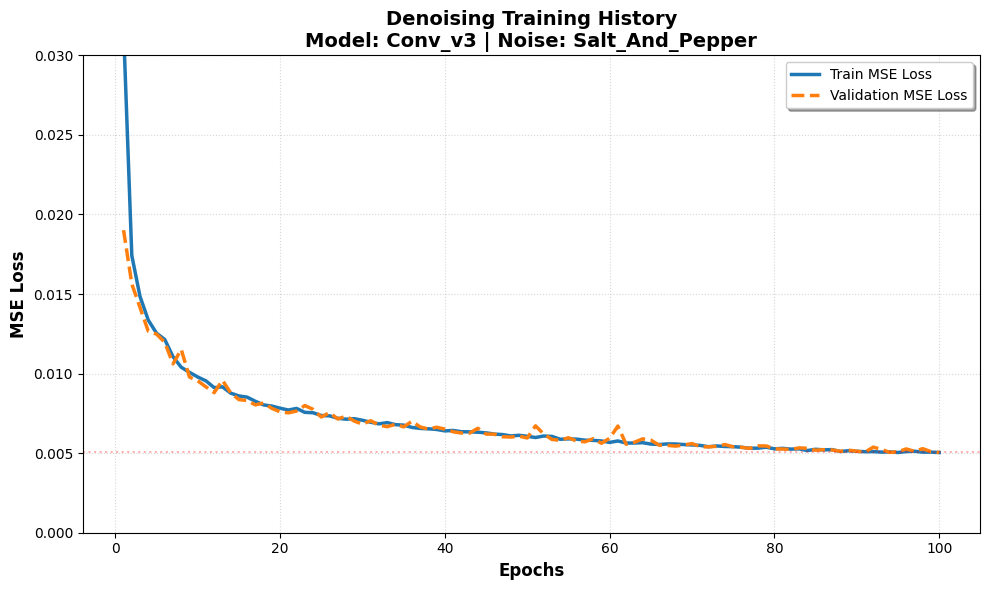

Visual results for Conv_v3 (Salt_And_Pepper):


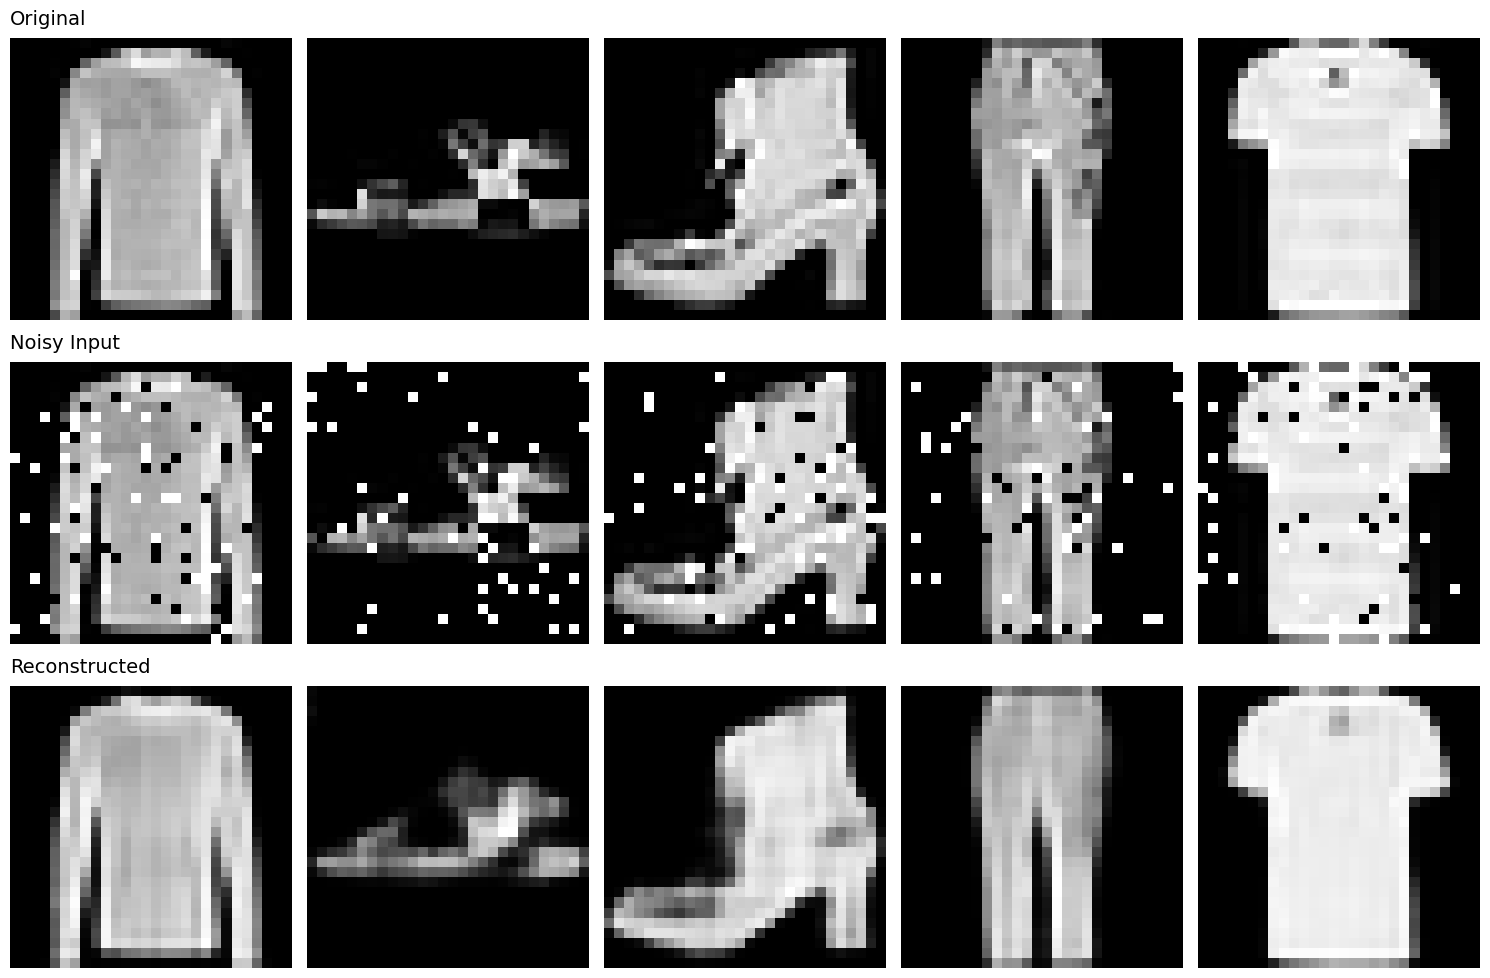


--- Training Res_v4 on Salt_And_Pepper noise ---
Epoch [1/100] - 11.58s
  Train MSE Loss: 0.0246 | Val MSE Loss: 0.0218
Epoch [2/100] - 11.62s
  Train MSE Loss: 0.0124 | Val MSE Loss: 0.0112
Epoch [3/100] - 11.67s
  Train MSE Loss: 0.0100 | Val MSE Loss: 0.0095
Epoch [4/100] - 11.68s
  Train MSE Loss: 0.0085 | Val MSE Loss: 0.0085
Epoch [5/100] - 11.68s
  Train MSE Loss: 0.0077 | Val MSE Loss: 0.0074
Epoch [6/100] - 11.63s
  Train MSE Loss: 0.0070 | Val MSE Loss: 0.0072
Epoch [7/100] - 11.64s
  Train MSE Loss: 0.0065 | Val MSE Loss: 0.0069
Epoch [8/100] - 11.61s
  Train MSE Loss: 0.0061 | Val MSE Loss: 0.0068
Epoch [9/100] - 11.63s
  Train MSE Loss: 0.0059 | Val MSE Loss: 0.0058
Epoch [10/100] - 11.61s
  Train MSE Loss: 0.0056 | Val MSE Loss: 0.0054
Epoch [11/100] - 11.62s
  Train MSE Loss: 0.0052 | Val MSE Loss: 0.0064
Epoch [12/100] - 11.66s
  Train MSE Loss: 0.0050 | Val MSE Loss: 0.0049
Epoch [13/100] - 11.61s
  Train MSE Loss: 0.0049 | Val MSE Loss: 0.0050
Epoch [14/100] - 11.62s

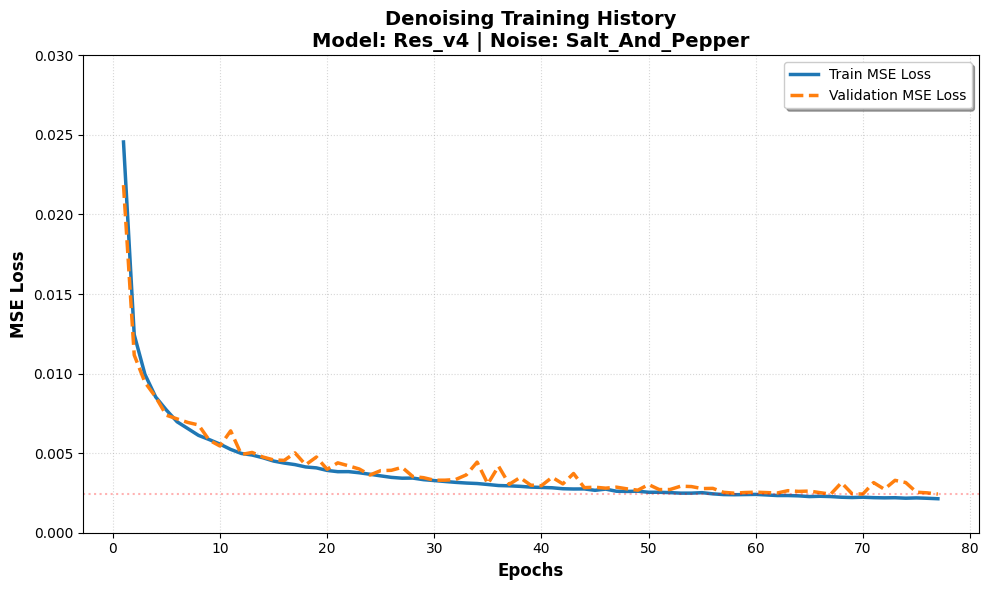

Visual results for Res_v4 (Salt_And_Pepper):


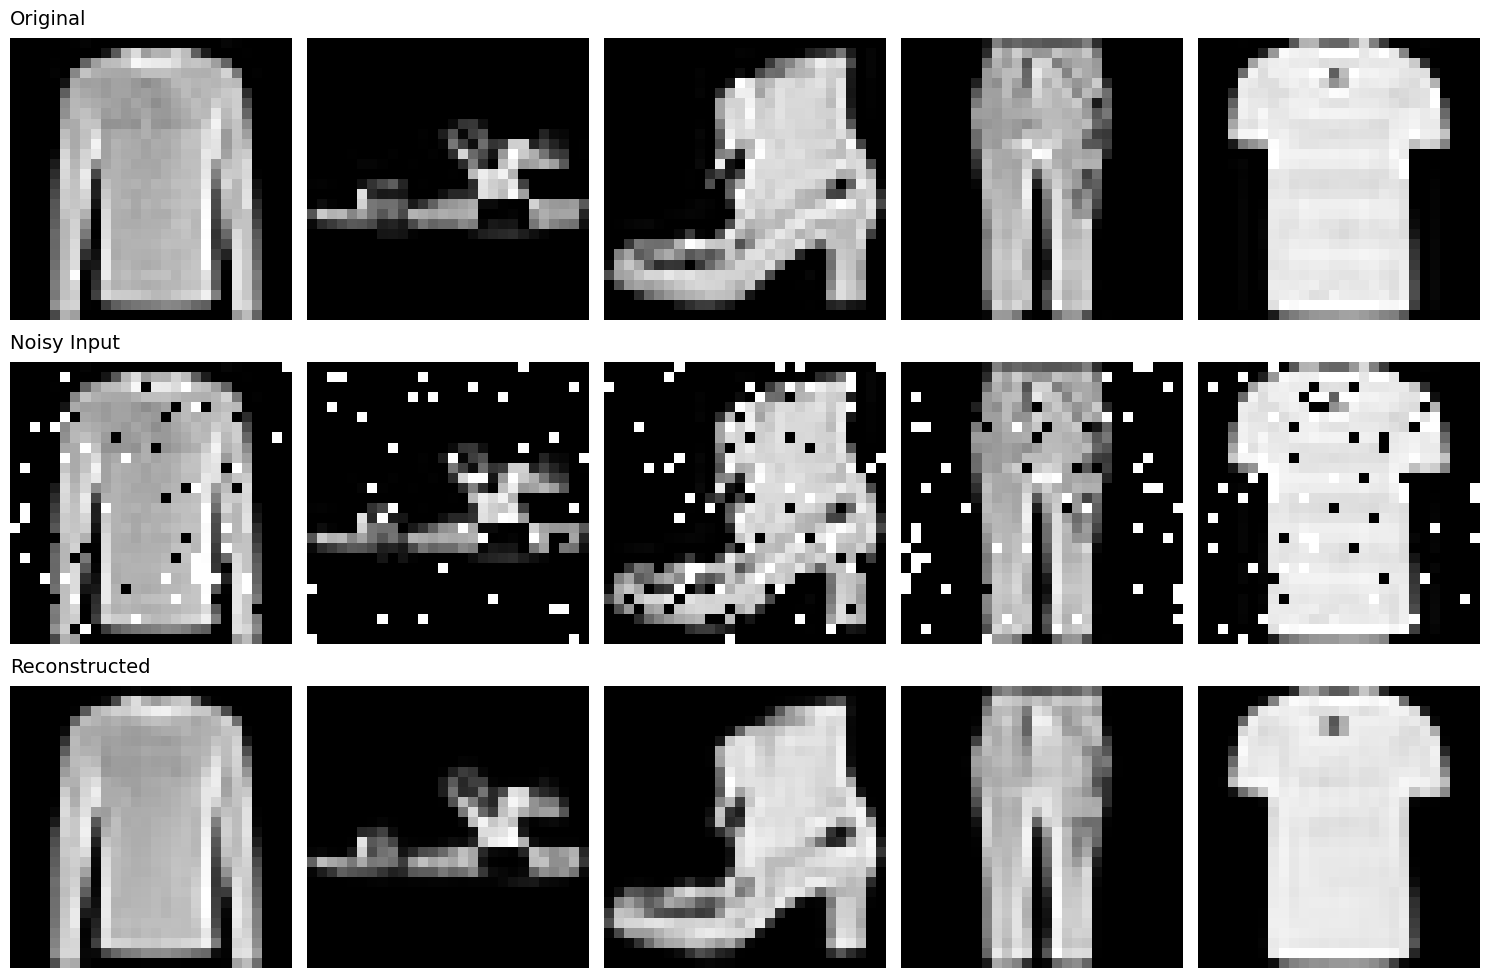

In [ ]:
EPOCHS = 100
LR = 1e-3
PARAM = 0.1

noise_name = "Salt_And_Pepper"
noise_fn = noise_functions[noise_name]
print(f"\n{'='*30}\nEXPERIMENT: Noise Type = {noise_name}\n{'='*30}")

for model_name, model_class in models_config.items():
    print(f"\n--- Training {model_name} on {noise_name} noise ---")

    model = model_class().to(device)
    optimizer = optim.Adam(model.parameters(), lr=LR)

    early_stop = EarlyStopping(patience=10, min_delta=0.0001, verbose=False,
                                path=f"Denoising_{model_name}_{noise_name}_01.pth")

    history = perform_denoising_learning(
        model, EPOCHS, optimizer, train_loader, val_loader, device,
        noise_function=noise_fn,
        noise_parameter=PARAM,
        early_stopping=early_stop
    )

    denoising_history_01[noise_name][model_name] = {
        "history": history,
        "model_state": model.state_dict()
    }

    plot_denoising_history(history, model_name, noise_name, (0, 0.03))

    print(f"Visual results for {model_name} ({noise_name}):")
    visualize_denoising(model, val_loader, device, noise_fn, PARAM, n=5)

    del model
    torch.cuda.empty_cache()


EXPERIMENT: Noise Type = Speckle

--- Training Deep_v3 on Speckle noise ---
Epoch [1/100] - 2.50s
  Train MSE Loss: 0.0570 | Val MSE Loss: 0.0333
Epoch [2/100] - 1.97s
  Train MSE Loss: 0.0274 | Val MSE Loss: 0.0230
Epoch [3/100] - 1.94s
  Train MSE Loss: 0.0218 | Val MSE Loss: 0.0207
Epoch [4/100] - 1.95s
  Train MSE Loss: 0.0196 | Val MSE Loss: 0.0187
Epoch [5/100] - 1.99s
  Train MSE Loss: 0.0181 | Val MSE Loss: 0.0173
Epoch [6/100] - 2.01s
  Train MSE Loss: 0.0167 | Val MSE Loss: 0.0161
Epoch [7/100] - 2.38s
  Train MSE Loss: 0.0156 | Val MSE Loss: 0.0153
Epoch [8/100] - 1.95s
  Train MSE Loss: 0.0149 | Val MSE Loss: 0.0146
Epoch [9/100] - 1.94s
  Train MSE Loss: 0.0142 | Val MSE Loss: 0.0141
Epoch [10/100] - 1.96s
  Train MSE Loss: 0.0136 | Val MSE Loss: 0.0134
Epoch [11/100] - 1.93s
  Train MSE Loss: 0.0131 | Val MSE Loss: 0.0131
Epoch [12/100] - 1.95s
  Train MSE Loss: 0.0127 | Val MSE Loss: 0.0127
Epoch [13/100] - 2.45s
  Train MSE Loss: 0.0124 | Val MSE Loss: 0.0125
Epoch [14

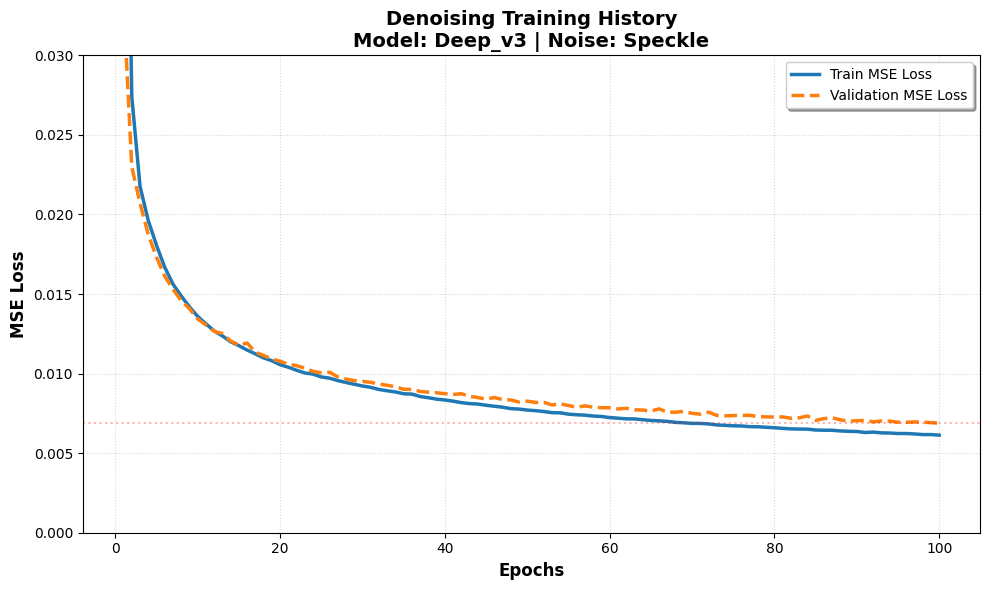

Visual results for Deep_v3 (Speckle):


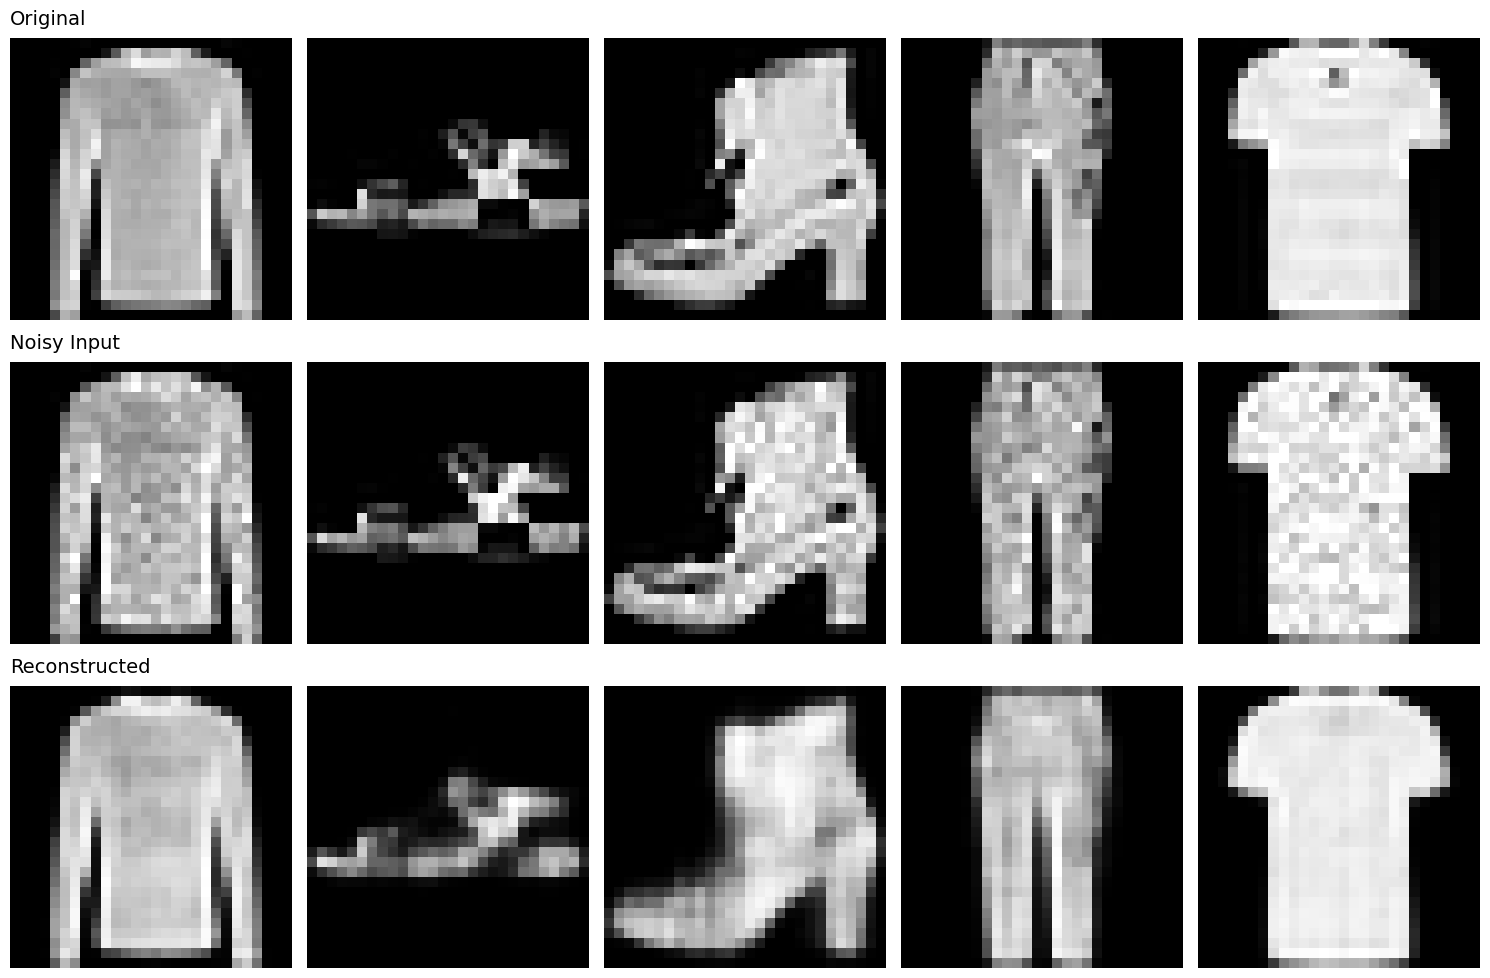


--- Training Conv_v3 on Speckle noise ---
Epoch [1/100] - 4.04s
  Train MSE Loss: 0.0314 | Val MSE Loss: 0.0182
Epoch [2/100] - 4.21s
  Train MSE Loss: 0.0160 | Val MSE Loss: 0.0144
Epoch [3/100] - 3.98s
  Train MSE Loss: 0.0135 | Val MSE Loss: 0.0126
Epoch [4/100] - 4.00s
  Train MSE Loss: 0.0121 | Val MSE Loss: 0.0116
Epoch [5/100] - 4.23s
  Train MSE Loss: 0.0114 | Val MSE Loss: 0.0112
Epoch [6/100] - 3.96s
  Train MSE Loss: 0.0104 | Val MSE Loss: 0.0103
Epoch [7/100] - 3.99s
  Train MSE Loss: 0.0099 | Val MSE Loss: 0.0097
Epoch [8/100] - 4.24s
  Train MSE Loss: 0.0093 | Val MSE Loss: 0.0092
Epoch [9/100] - 3.95s
  Train MSE Loss: 0.0090 | Val MSE Loss: 0.0086
Epoch [10/100] - 3.94s
  Train MSE Loss: 0.0085 | Val MSE Loss: 0.0095
Epoch [11/100] - 4.21s
  Train MSE Loss: 0.0083 | Val MSE Loss: 0.0082
Epoch [12/100] - 3.97s
  Train MSE Loss: 0.0079 | Val MSE Loss: 0.0079
Epoch [13/100] - 3.95s
  Train MSE Loss: 0.0078 | Val MSE Loss: 0.0074
Epoch [14/100] - 4.18s
  Train MSE Loss: 0.

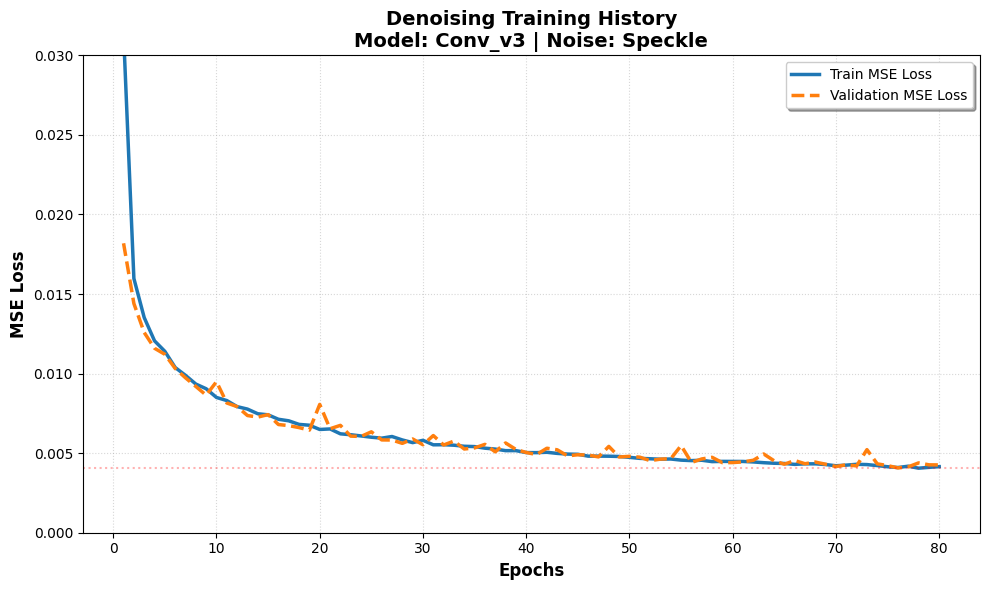

Visual results for Conv_v3 (Speckle):


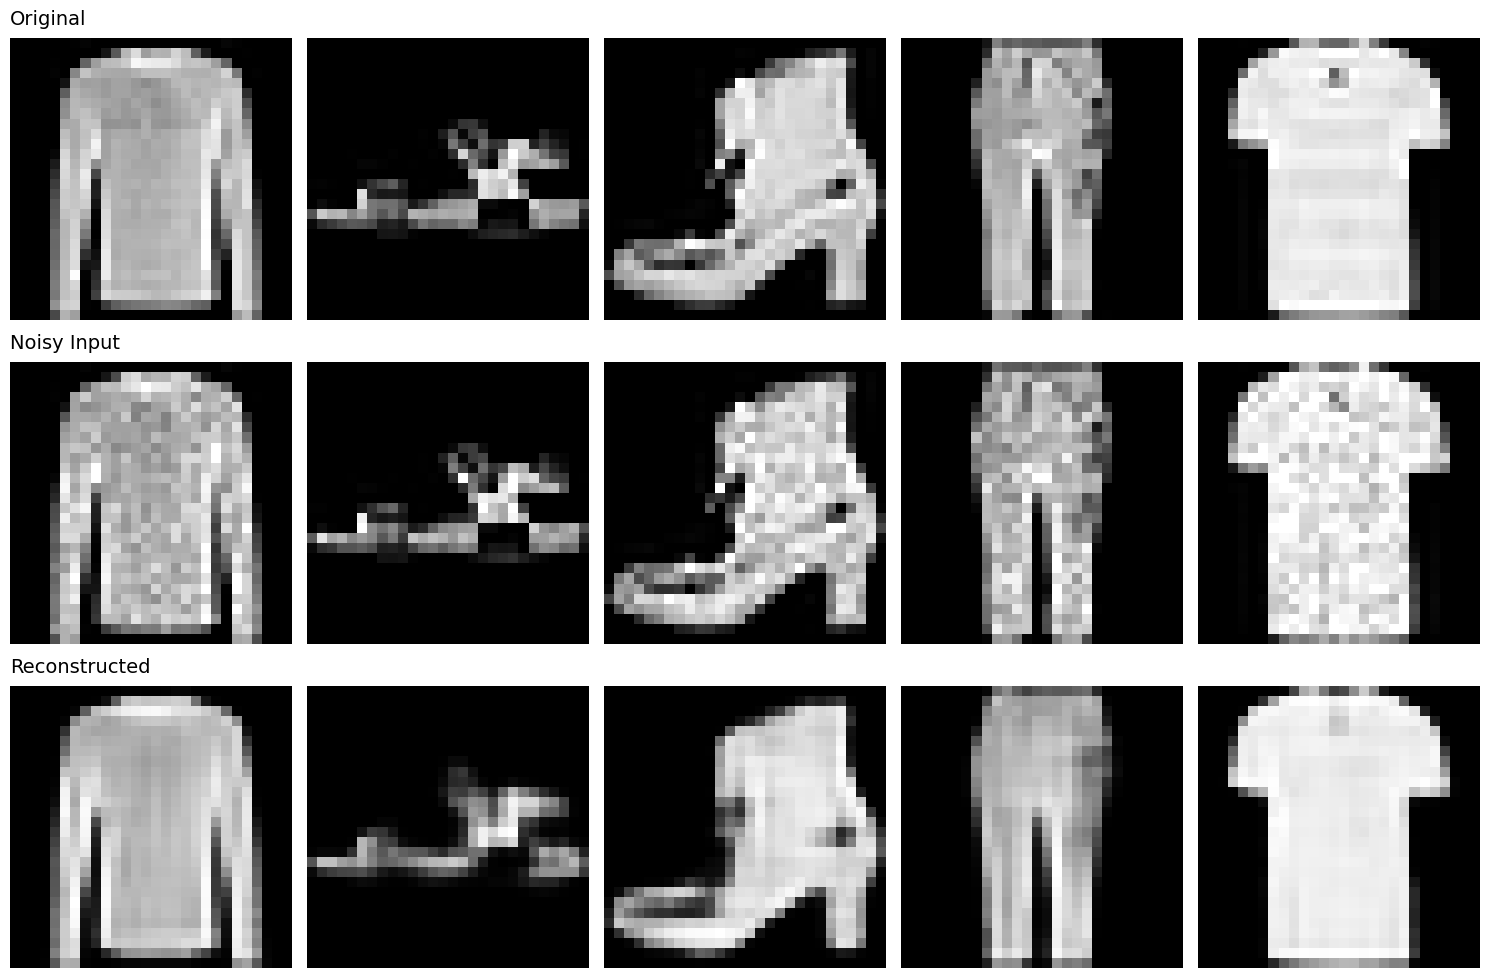


--- Training Res_v4 on Speckle noise ---
Epoch [1/100] - 11.62s
  Train MSE Loss: 0.0224 | Val MSE Loss: 0.0127
Epoch [2/100] - 11.63s
  Train MSE Loss: 0.0106 | Val MSE Loss: 0.0090
Epoch [3/100] - 11.65s
  Train MSE Loss: 0.0082 | Val MSE Loss: 0.0072
Epoch [4/100] - 11.66s
  Train MSE Loss: 0.0069 | Val MSE Loss: 0.0082
Epoch [5/100] - 11.84s
  Train MSE Loss: 0.0061 | Val MSE Loss: 0.0057
Epoch [6/100] - 11.70s
  Train MSE Loss: 0.0055 | Val MSE Loss: 0.0057
Epoch [7/100] - 11.67s
  Train MSE Loss: 0.0050 | Val MSE Loss: 0.0051
Epoch [8/100] - 11.68s
  Train MSE Loss: 0.0047 | Val MSE Loss: 0.0048
Epoch [9/100] - 11.67s
  Train MSE Loss: 0.0044 | Val MSE Loss: 0.0045
Epoch [10/100] - 11.68s
  Train MSE Loss: 0.0042 | Val MSE Loss: 0.0041
Epoch [11/100] - 11.69s
  Train MSE Loss: 0.0040 | Val MSE Loss: 0.0048
Epoch [12/100] - 11.68s
  Train MSE Loss: 0.0038 | Val MSE Loss: 0.0037
Epoch [13/100] - 11.68s
  Train MSE Loss: 0.0036 | Val MSE Loss: 0.0039
Epoch [14/100] - 11.63s
  Train

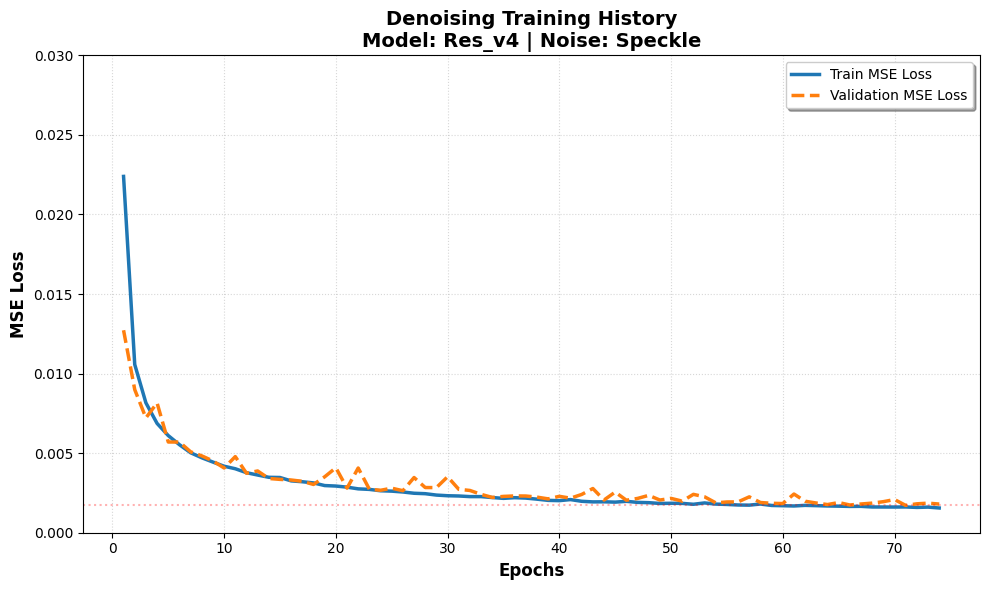

Visual results for Res_v4 (Speckle):


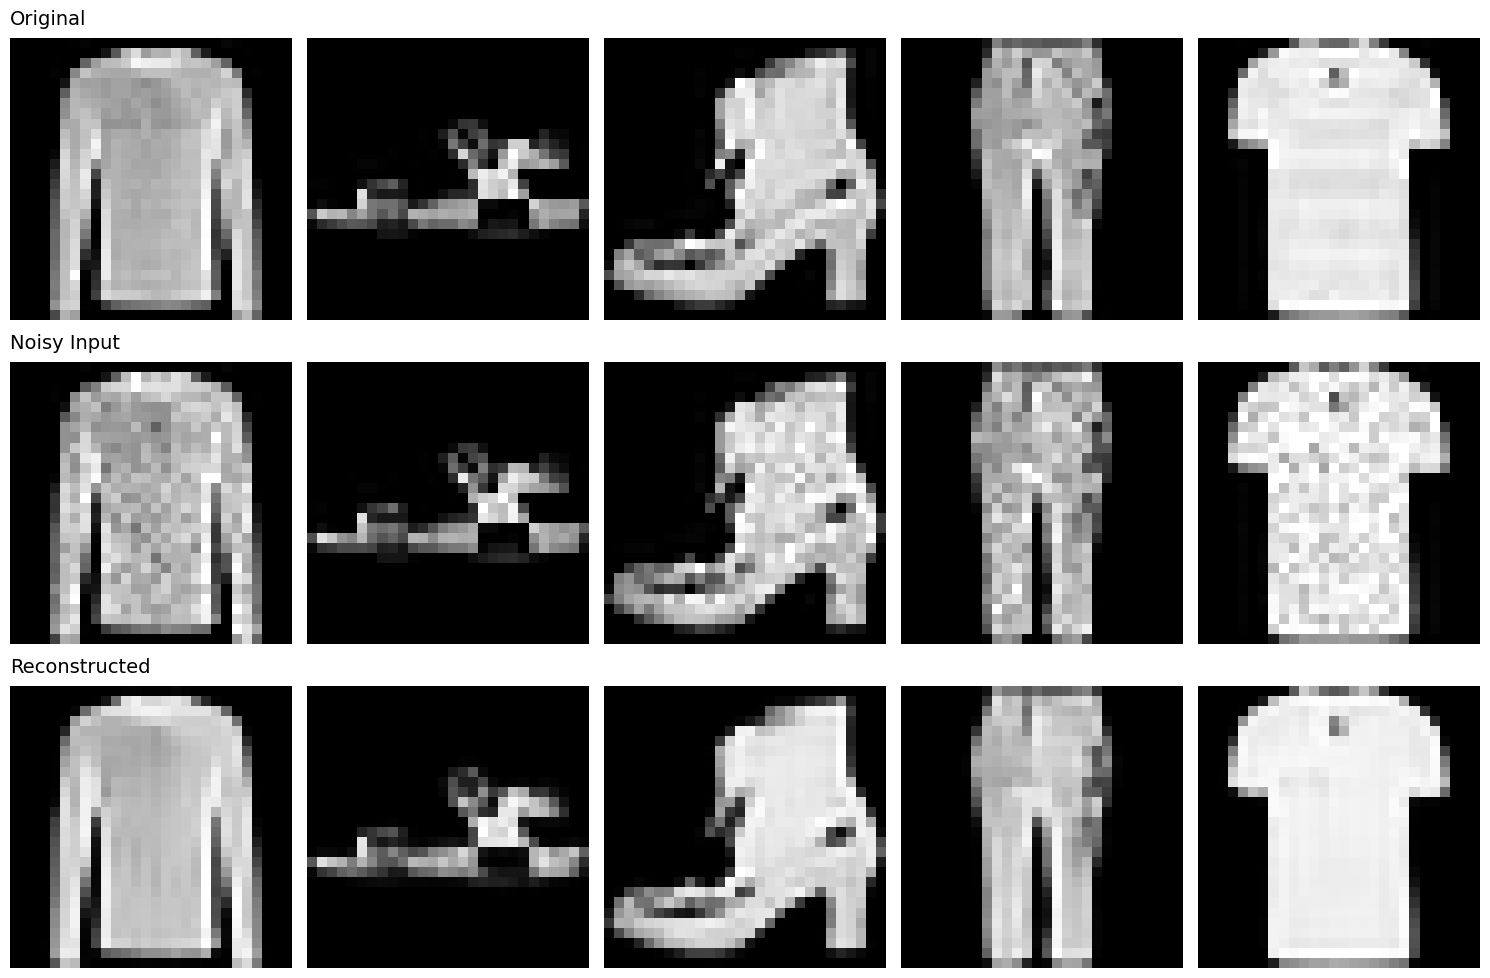

In [ ]:
EPOCHS = 100
LR = 1e-3
PARAM = 0.1

noise_name = "Speckle"
noise_fn = noise_functions[noise_name]
print(f"\n{'='*30}\nEXPERIMENT: Noise Type = {noise_name}\n{'='*30}")

for model_name, model_class in models_config.items():
    print(f"\n--- Training {model_name} on {noise_name} noise ---")

    model = model_class().to(device)
    optimizer = optim.Adam(model.parameters(), lr=LR)

    early_stop = EarlyStopping(patience=10, min_delta=0.0001, verbose=False,
                                path=f"Denoising_{model_name}_{noise_name}_01.pth")

    history = perform_denoising_learning(
        model, EPOCHS, optimizer, train_loader, val_loader, device,
        noise_function=noise_fn,
        noise_parameter=PARAM,
        early_stopping=early_stop
    )

    denoising_history_01[noise_name][model_name] = {
        "history": history,
        "model_state": model.state_dict()
    }

    plot_denoising_history(history, model_name, noise_name, (0, 0.03))

    print(f"Visual results for {model_name} ({noise_name}):")
    visualize_denoising(model, val_loader, device, noise_fn, PARAM, n=5)

    del model
    torch.cuda.empty_cache()

In [ ]:
torch.save(denoising_history_01, 'denoising_history_01.pt')


EXPERIMENT: Noise Type = Gaussian

--- Training Deep_v3 on Gaussian noise ---
Epoch [1/100] - 2.05s
  Train MSE Loss: 0.0691 | Val MSE Loss: 0.0419
Epoch [2/100] - 1.94s
  Train MSE Loss: 0.0327 | Val MSE Loss: 0.0269
Epoch [3/100] - 2.25s
  Train MSE Loss: 0.0247 | Val MSE Loss: 0.0238
Epoch [4/100] - 2.13s
  Train MSE Loss: 0.0224 | Val MSE Loss: 0.0217
Epoch [5/100] - 1.95s
  Train MSE Loss: 0.0209 | Val MSE Loss: 0.0203
Epoch [6/100] - 1.96s
  Train MSE Loss: 0.0197 | Val MSE Loss: 0.0199
Epoch [7/100] - 1.95s
  Train MSE Loss: 0.0189 | Val MSE Loss: 0.0188
Epoch [8/100] - 1.97s
  Train MSE Loss: 0.0181 | Val MSE Loss: 0.0181
Epoch [9/100] - 2.25s
  Train MSE Loss: 0.0175 | Val MSE Loss: 0.0173
Epoch [10/100] - 2.17s
  Train MSE Loss: 0.0170 | Val MSE Loss: 0.0169
Epoch [11/100] - 1.98s
  Train MSE Loss: 0.0165 | Val MSE Loss: 0.0164
Epoch [12/100] - 1.96s
  Train MSE Loss: 0.0161 | Val MSE Loss: 0.0161
Epoch [13/100] - 1.97s
  Train MSE Loss: 0.0157 | Val MSE Loss: 0.0156
Epoch [

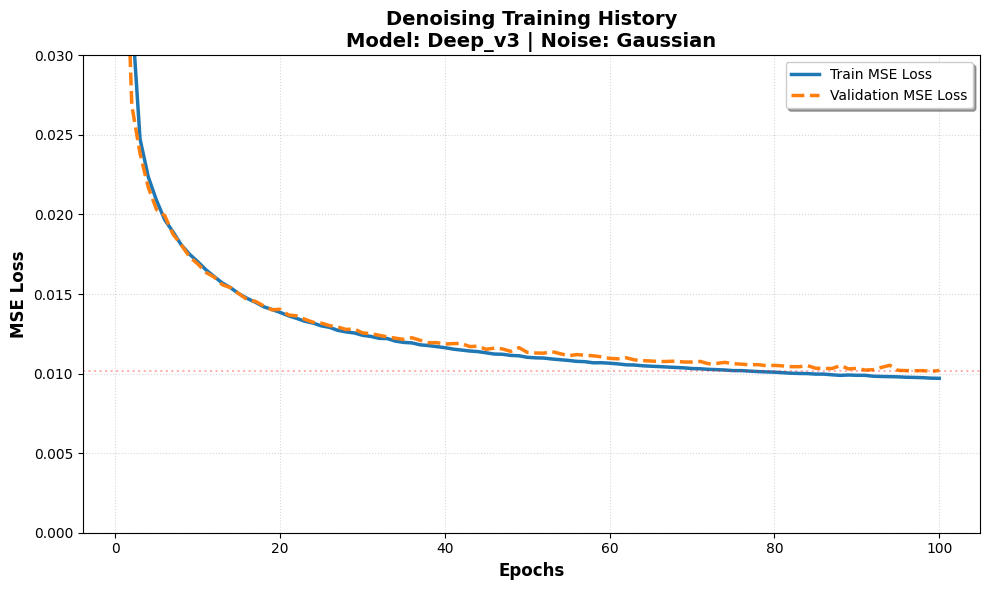

Visual results for Deep_v3 (Gaussian):


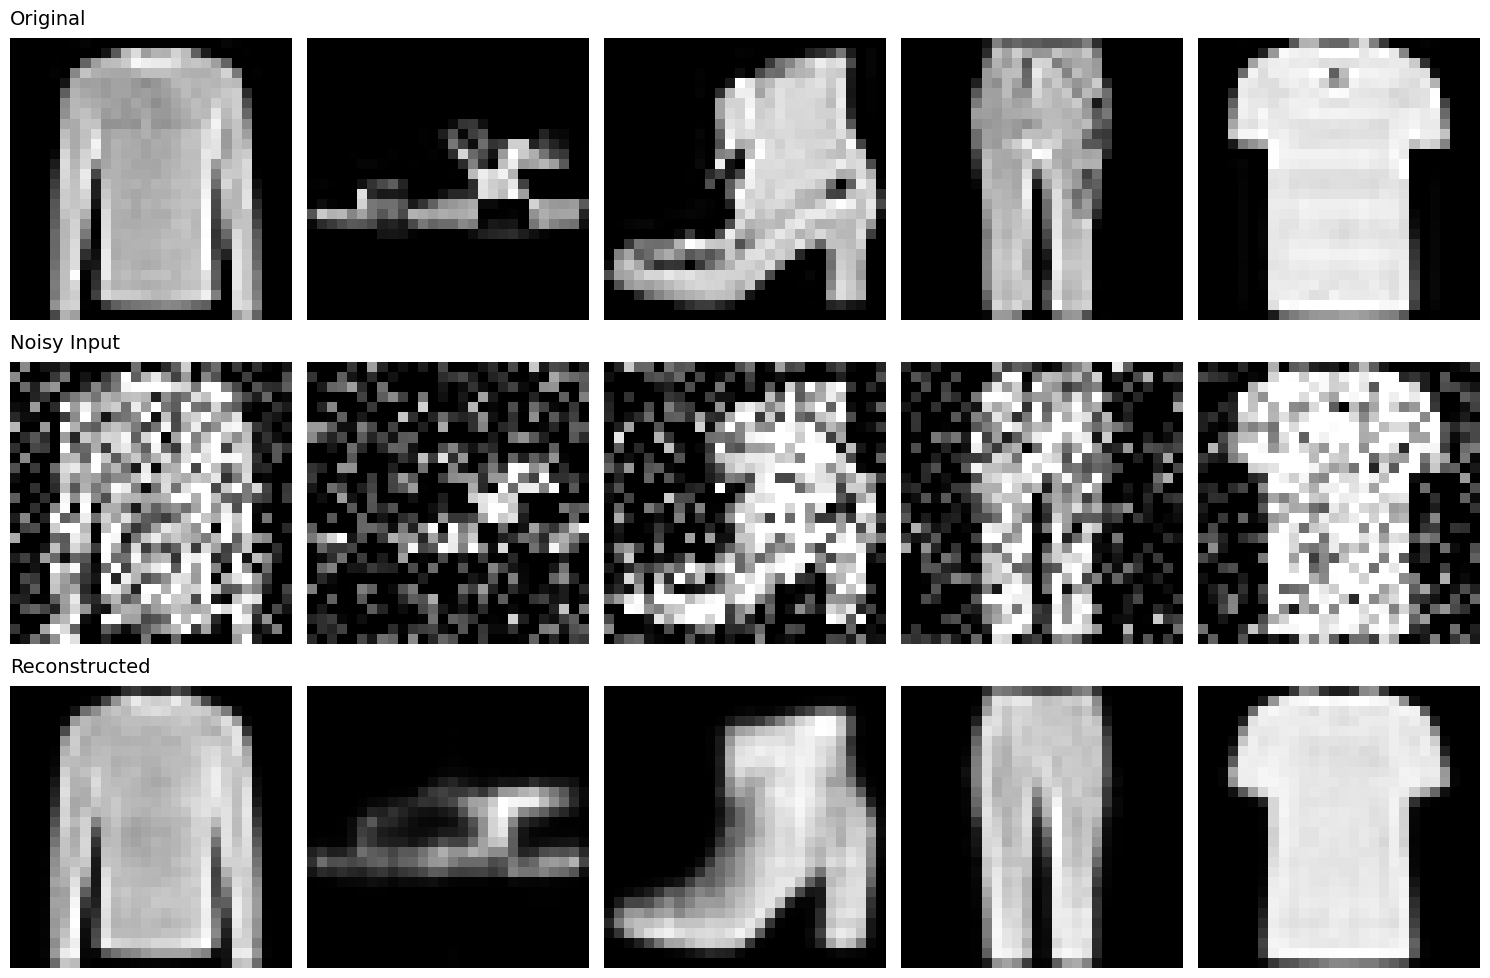


--- Training Conv_v3 on Gaussian noise ---
Epoch [1/100] - 4.05s
  Train MSE Loss: 0.0338 | Val MSE Loss: 0.0211
Epoch [2/100] - 3.98s
  Train MSE Loss: 0.0184 | Val MSE Loss: 0.0167
Epoch [3/100] - 4.22s
  Train MSE Loss: 0.0158 | Val MSE Loss: 0.0150
Epoch [4/100] - 4.00s
  Train MSE Loss: 0.0147 | Val MSE Loss: 0.0139
Epoch [5/100] - 3.98s
  Train MSE Loss: 0.0138 | Val MSE Loss: 0.0131
Epoch [6/100] - 4.21s
  Train MSE Loss: 0.0132 | Val MSE Loss: 0.0126
Epoch [7/100] - 3.98s
  Train MSE Loss: 0.0126 | Val MSE Loss: 0.0122
Epoch [8/100] - 3.96s
  Train MSE Loss: 0.0122 | Val MSE Loss: 0.0118
Epoch [9/100] - 4.17s
  Train MSE Loss: 0.0120 | Val MSE Loss: 0.0115
Epoch [10/100] - 3.95s
  Train MSE Loss: 0.0117 | Val MSE Loss: 0.0123
Epoch [11/100] - 3.95s
  Train MSE Loss: 0.0114 | Val MSE Loss: 0.0111
Epoch [12/100] - 4.15s
  Train MSE Loss: 0.0112 | Val MSE Loss: 0.0110
Epoch [13/100] - 3.94s
  Train MSE Loss: 0.0110 | Val MSE Loss: 0.0112
Epoch [14/100] - 3.94s
  Train MSE Loss: 0

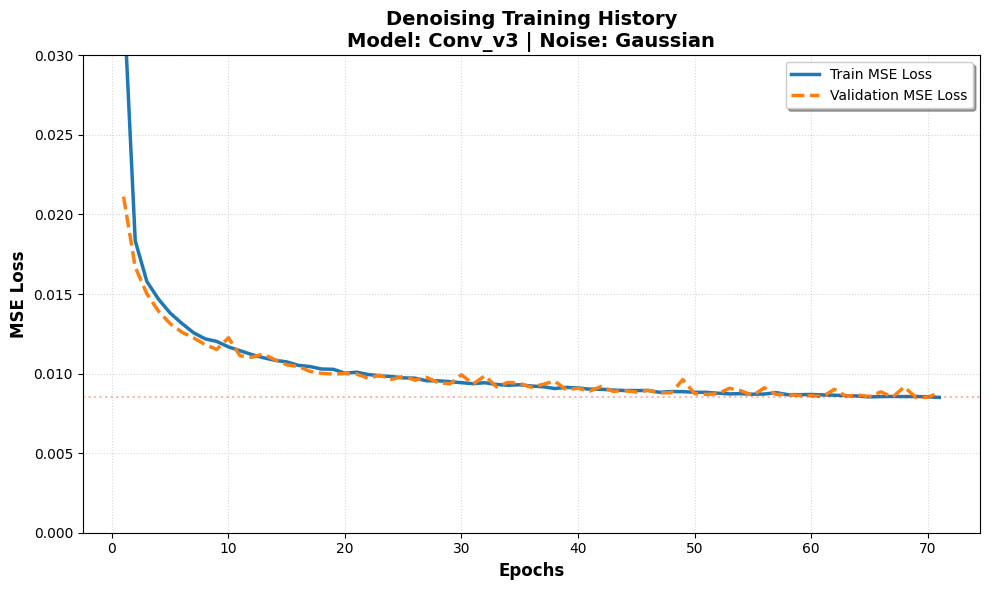

Visual results for Conv_v3 (Gaussian):


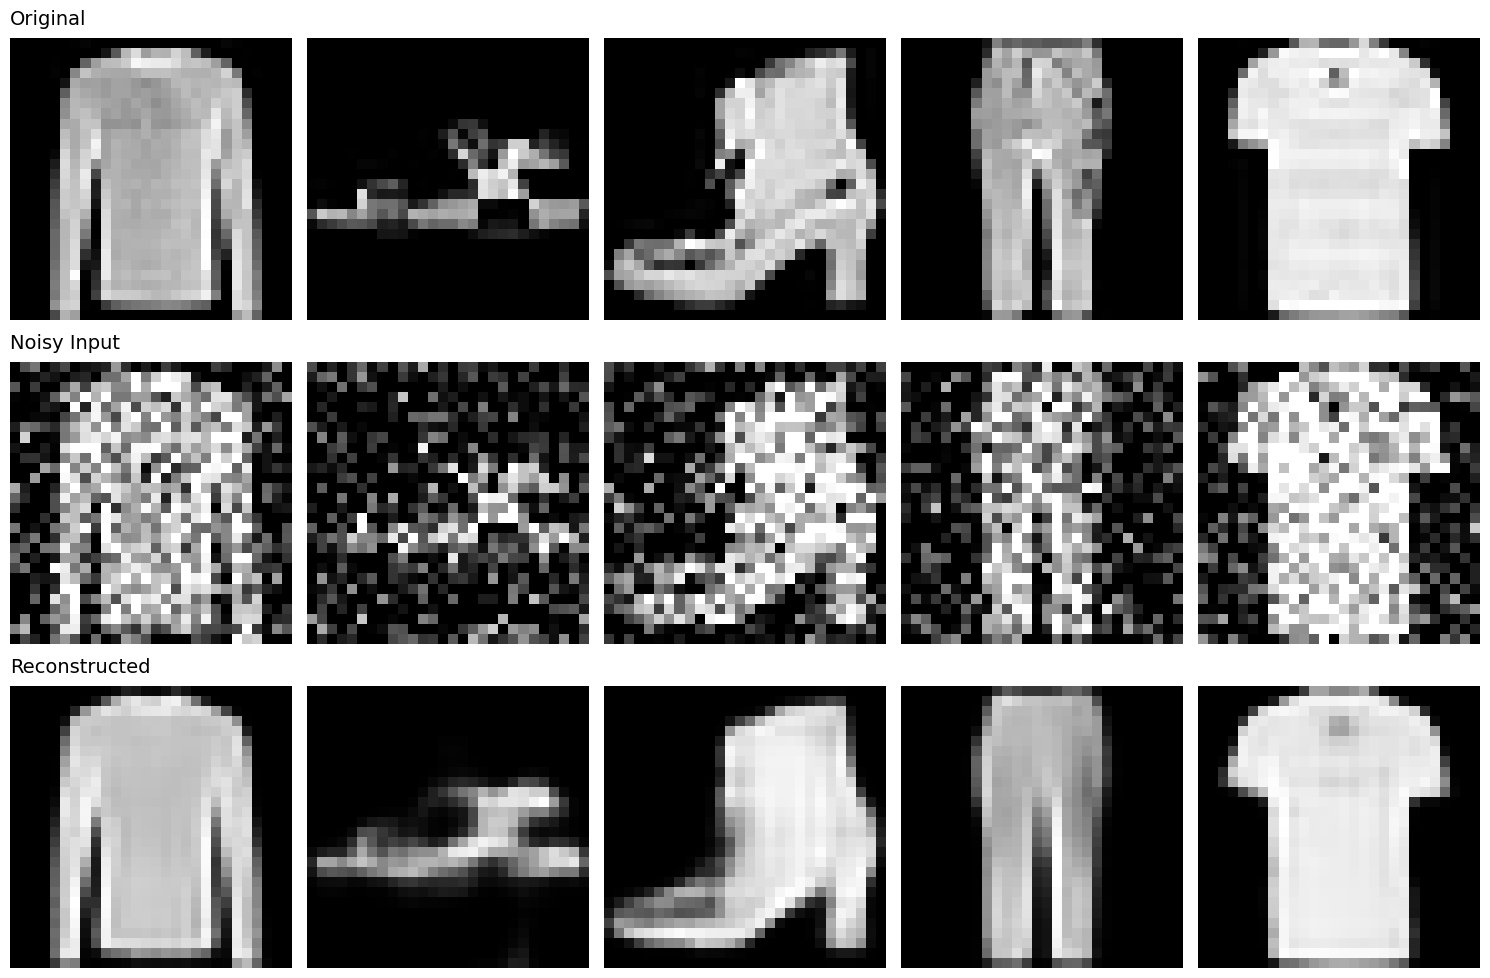


--- Training Res_v4 on Gaussian noise ---
Epoch [1/100] - 11.58s
  Train MSE Loss: 0.0238 | Val MSE Loss: 0.0148
Epoch [2/100] - 11.58s
  Train MSE Loss: 0.0134 | Val MSE Loss: 0.0120
Epoch [3/100] - 11.59s
  Train MSE Loss: 0.0116 | Val MSE Loss: 0.0127
Epoch [4/100] - 11.66s
  Train MSE Loss: 0.0105 | Val MSE Loss: 0.0103
Epoch [5/100] - 11.68s
  Train MSE Loss: 0.0099 | Val MSE Loss: 0.0097
Epoch [6/100] - 11.66s
  Train MSE Loss: 0.0095 | Val MSE Loss: 0.0093
Epoch [7/100] - 11.68s
  Train MSE Loss: 0.0091 | Val MSE Loss: 0.0094
Epoch [8/100] - 11.76s
  Train MSE Loss: 0.0089 | Val MSE Loss: 0.0089
Epoch [9/100] - 11.70s
  Train MSE Loss: 0.0087 | Val MSE Loss: 0.0089
Epoch [10/100] - 11.66s
  Train MSE Loss: 0.0084 | Val MSE Loss: 0.0086
Epoch [11/100] - 11.61s
  Train MSE Loss: 0.0084 | Val MSE Loss: 0.0090
Epoch [12/100] - 11.62s
  Train MSE Loss: 0.0082 | Val MSE Loss: 0.0082
Epoch [13/100] - 11.63s
  Train MSE Loss: 0.0081 | Val MSE Loss: 0.0084
Epoch [14/100] - 11.63s
  Trai

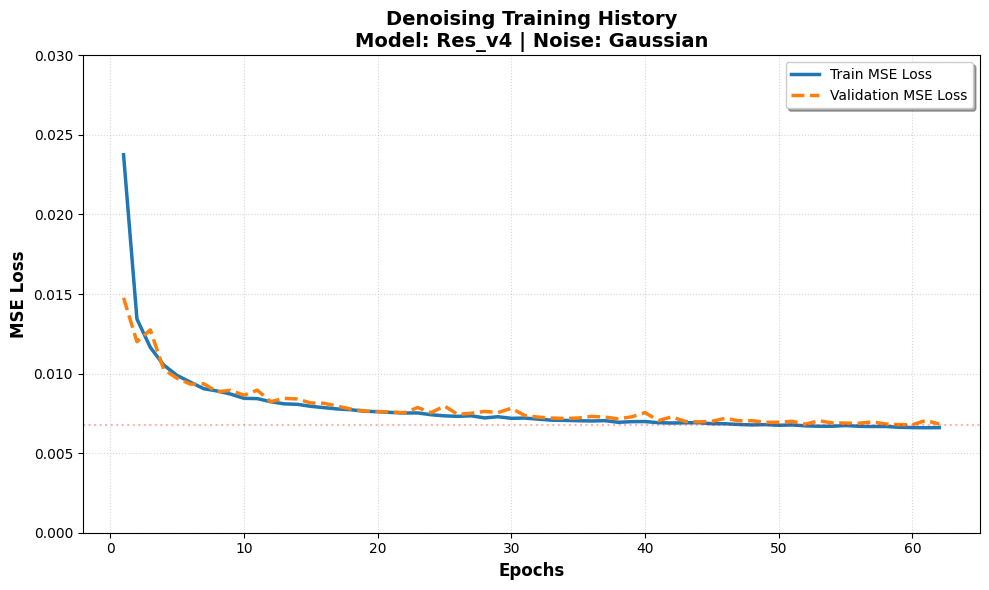

Visual results for Res_v4 (Gaussian):


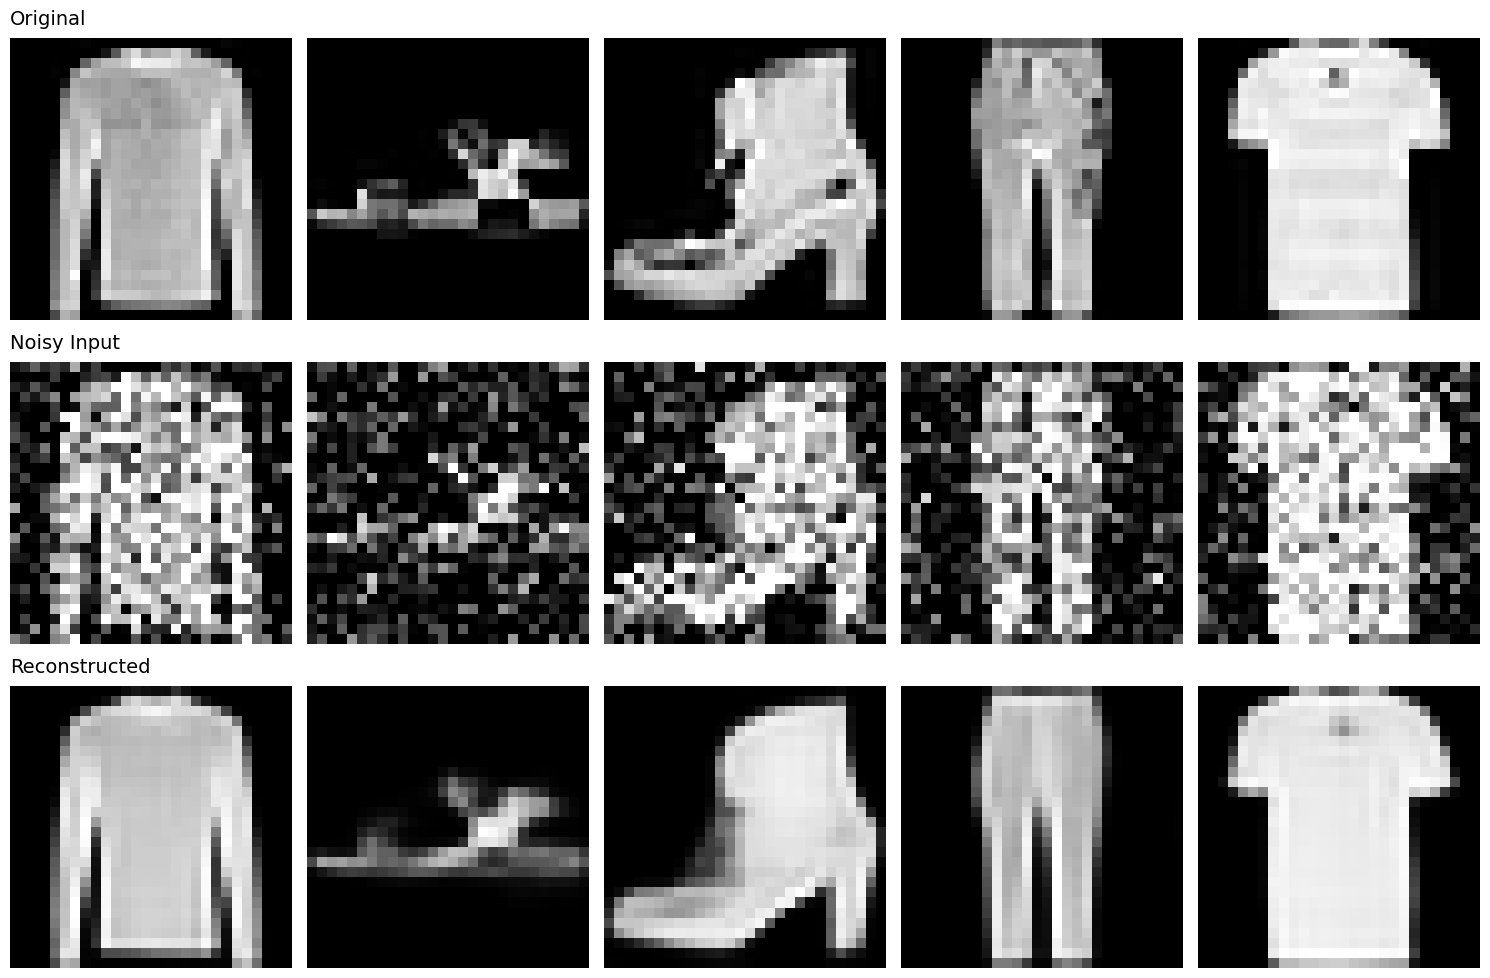

In [ ]:
EPOCHS = 100
LR = 1e-3
PARAM = 0.3

noise_name = "Gaussian"
noise_fn = noise_functions[noise_name]
print(f"\n{'='*30}\nEXPERIMENT: Noise Type = {noise_name}\n{'='*30}")

for model_name, model_class in models_config.items():
    print(f"\n--- Training {model_name} on {noise_name} noise ---")

    model = model_class().to(device)
    optimizer = optim.Adam(model.parameters(), lr=LR)

    early_stop = EarlyStopping(patience=10, min_delta=0.0001, verbose=False,
                                path=f"Denoising_{model_name}_{noise_name}_03.pth")

    history = perform_denoising_learning(
        model, EPOCHS, optimizer, train_loader, val_loader, device,
        noise_function=noise_fn,
        noise_parameter=PARAM,
        early_stopping=early_stop
    )

    denoising_history_03[noise_name][model_name] = {
        "history": history,
        "model_state": model.state_dict()
    }

    plot_denoising_history(history, model_name, noise_name, (0, 0.03))

    print(f"Visual results for {model_name} ({noise_name}):")
    visualize_denoising(model, val_loader, device, noise_fn, PARAM, n=5)

    del model
    torch.cuda.empty_cache()


EXPERIMENT: Noise Type = Salt_And_Pepper

--- Training Deep_v3 on Salt_And_Pepper noise ---
Epoch [1/100] - 2.91s
  Train MSE Loss: 0.0826 | Val MSE Loss: 0.0598
Epoch [2/100] - 2.04s
  Train MSE Loss: 0.0385 | Val MSE Loss: 0.0309
Epoch [3/100] - 1.91s
  Train MSE Loss: 0.0270 | Val MSE Loss: 0.0247
Epoch [4/100] - 1.93s
  Train MSE Loss: 0.0240 | Val MSE Loss: 0.0231
Epoch [5/100] - 1.93s
  Train MSE Loss: 0.0225 | Val MSE Loss: 0.0216
Epoch [6/100] - 1.94s
  Train MSE Loss: 0.0212 | Val MSE Loss: 0.0206
Epoch [7/100] - 2.29s
  Train MSE Loss: 0.0203 | Val MSE Loss: 0.0198
Epoch [8/100] - 2.10s
  Train MSE Loss: 0.0195 | Val MSE Loss: 0.0193
Epoch [9/100] - 1.93s
  Train MSE Loss: 0.0190 | Val MSE Loss: 0.0187
Epoch [10/100] - 1.92s
  Train MSE Loss: 0.0185 | Val MSE Loss: 0.0181
Epoch [11/100] - 1.92s
  Train MSE Loss: 0.0180 | Val MSE Loss: 0.0177
Epoch [12/100] - 1.94s
  Train MSE Loss: 0.0176 | Val MSE Loss: 0.0174
Epoch [13/100] - 2.21s
  Train MSE Loss: 0.0173 | Val MSE Loss: 

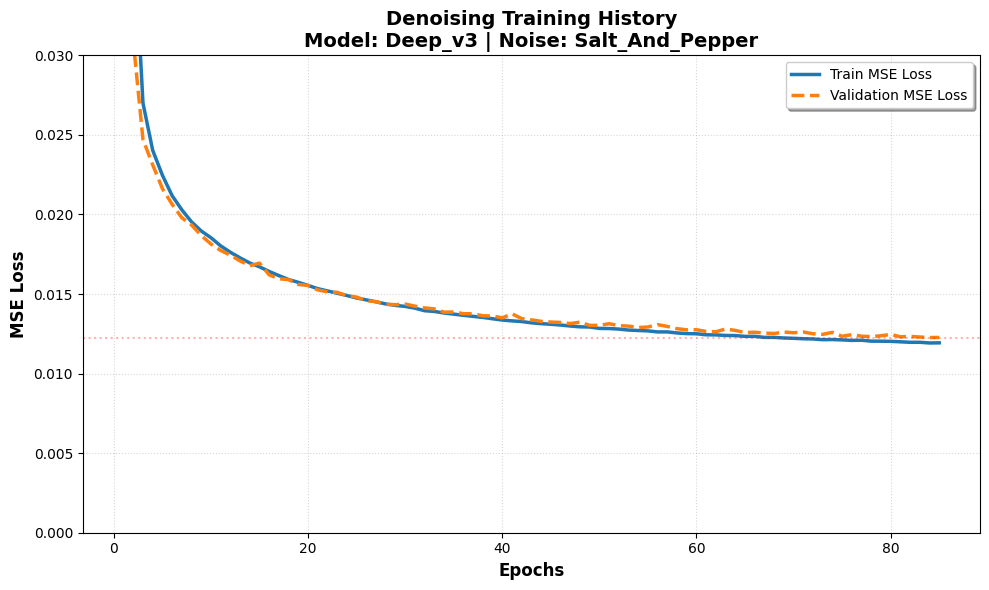

Visual results for Deep_v3 (Salt_And_Pepper):


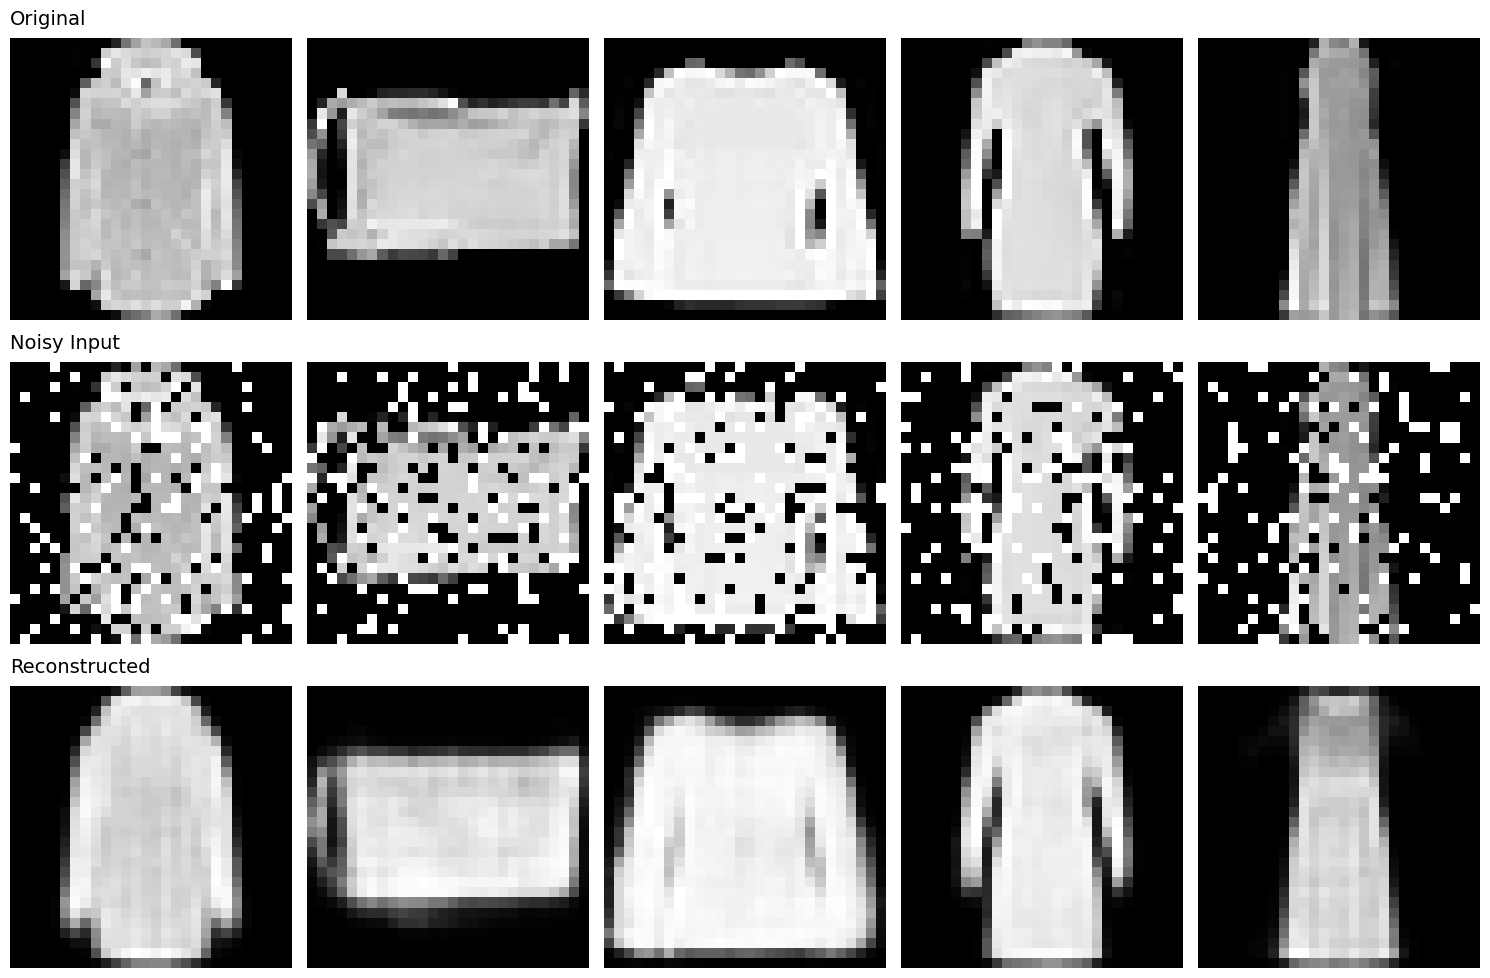


--- Training Conv_v3 on Salt_And_Pepper noise ---
Epoch [1/100] - 5.06s
  Train MSE Loss: 0.0346 | Val MSE Loss: 0.0215
Epoch [2/100] - 3.90s
  Train MSE Loss: 0.0197 | Val MSE Loss: 0.0179
Epoch [3/100] - 3.93s
  Train MSE Loss: 0.0171 | Val MSE Loss: 0.0164
Epoch [4/100] - 4.14s
  Train MSE Loss: 0.0155 | Val MSE Loss: 0.0163
Epoch [5/100] - 3.91s
  Train MSE Loss: 0.0146 | Val MSE Loss: 0.0138
Epoch [6/100] - 3.92s
  Train MSE Loss: 0.0137 | Val MSE Loss: 0.0134
Epoch [7/100] - 4.14s
  Train MSE Loss: 0.0134 | Val MSE Loss: 0.0127
Epoch [8/100] - 3.93s
  Train MSE Loss: 0.0127 | Val MSE Loss: 0.0121
Epoch [9/100] - 3.94s
  Train MSE Loss: 0.0122 | Val MSE Loss: 0.0120
Epoch [10/100] - 4.18s
  Train MSE Loss: 0.0120 | Val MSE Loss: 0.0116
Epoch [11/100] - 3.95s
  Train MSE Loss: 0.0116 | Val MSE Loss: 0.0121
Epoch [12/100] - 3.95s
  Train MSE Loss: 0.0114 | Val MSE Loss: 0.0112
Epoch [13/100] - 4.19s
  Train MSE Loss: 0.0112 | Val MSE Loss: 0.0119
Epoch [14/100] - 3.97s
  Train MSE 

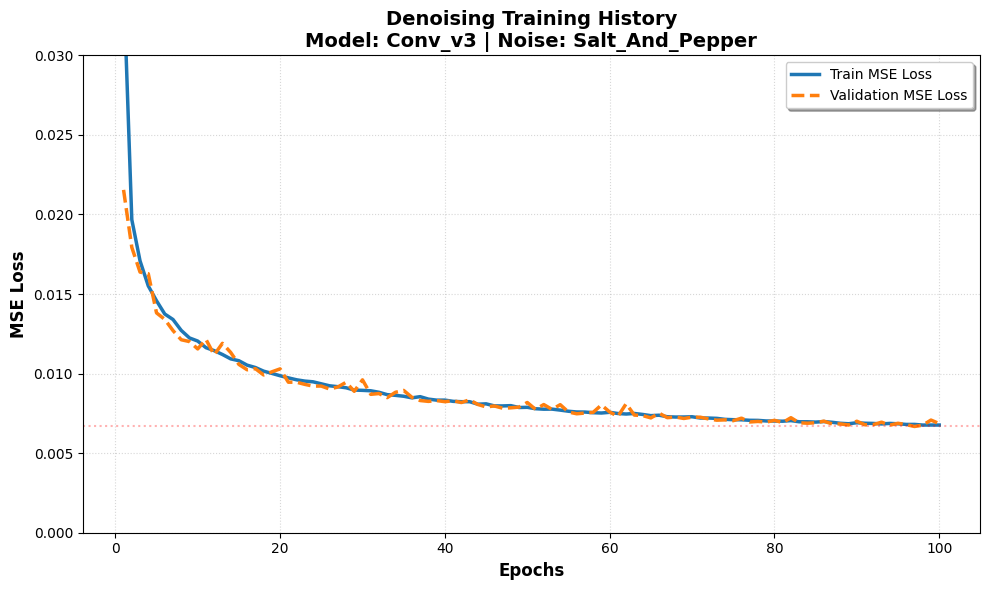

Visual results for Conv_v3 (Salt_And_Pepper):


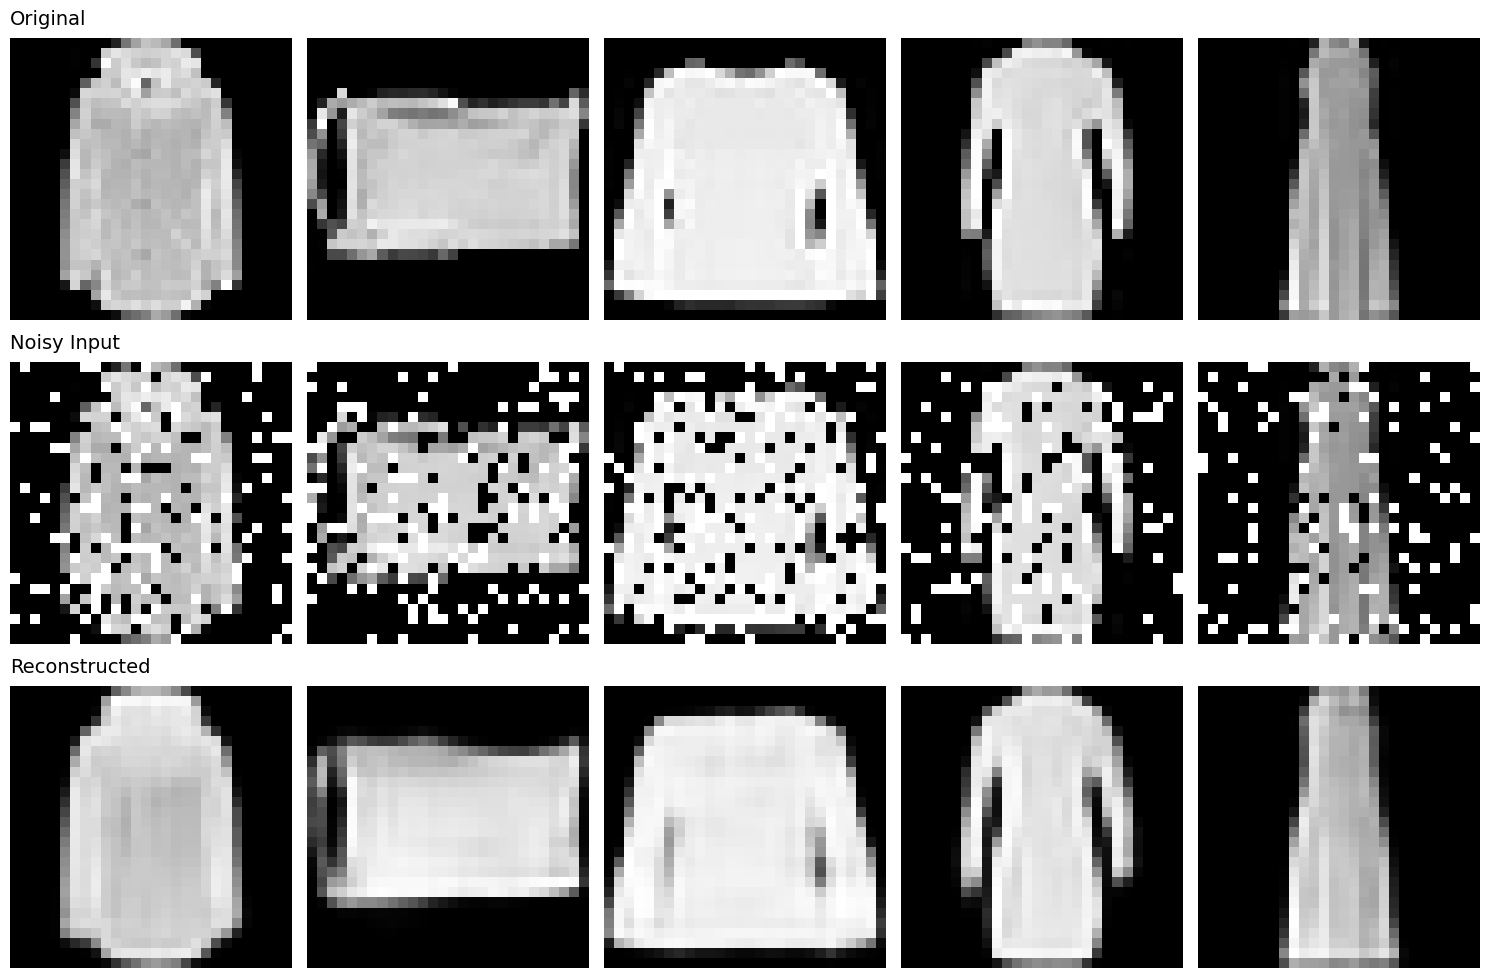


--- Training Res_v4 on Salt_And_Pepper noise ---
Epoch [1/100] - 12.00s
  Train MSE Loss: 0.0252 | Val MSE Loss: 0.0170
Epoch [2/100] - 11.97s
  Train MSE Loss: 0.0145 | Val MSE Loss: 0.0137
Epoch [3/100] - 12.02s
  Train MSE Loss: 0.0121 | Val MSE Loss: 0.0111
Epoch [4/100] - 12.04s
  Train MSE Loss: 0.0106 | Val MSE Loss: 0.0108
Epoch [5/100] - 12.05s
  Train MSE Loss: 0.0096 | Val MSE Loss: 0.0093
Epoch [6/100] - 12.12s
  Train MSE Loss: 0.0089 | Val MSE Loss: 0.0091
Epoch [7/100] - 12.09s
  Train MSE Loss: 0.0085 | Val MSE Loss: 0.0088
Epoch [8/100] - 12.07s
  Train MSE Loss: 0.0080 | Val MSE Loss: 0.0079
Epoch [9/100] - 12.07s
  Train MSE Loss: 0.0076 | Val MSE Loss: 0.0077
Epoch [10/100] - 12.06s
  Train MSE Loss: 0.0074 | Val MSE Loss: 0.0079
Epoch [11/100] - 12.04s
  Train MSE Loss: 0.0071 | Val MSE Loss: 0.0070
Epoch [12/100] - 12.06s
  Train MSE Loss: 0.0070 | Val MSE Loss: 0.0070
Epoch [13/100] - 12.05s
  Train MSE Loss: 0.0069 | Val MSE Loss: 0.0066
Epoch [14/100] - 12.04s

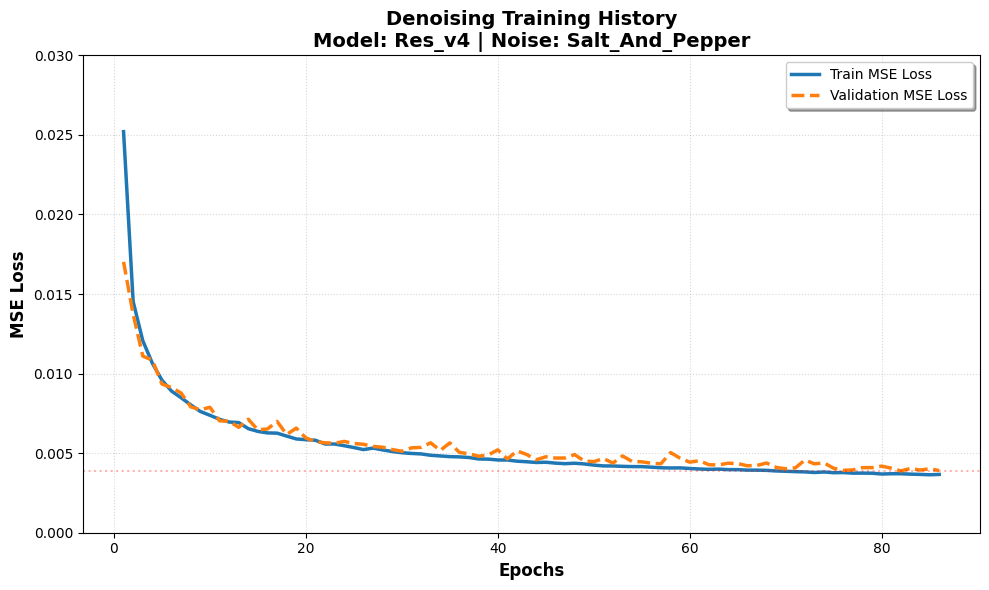

Visual results for Res_v4 (Salt_And_Pepper):


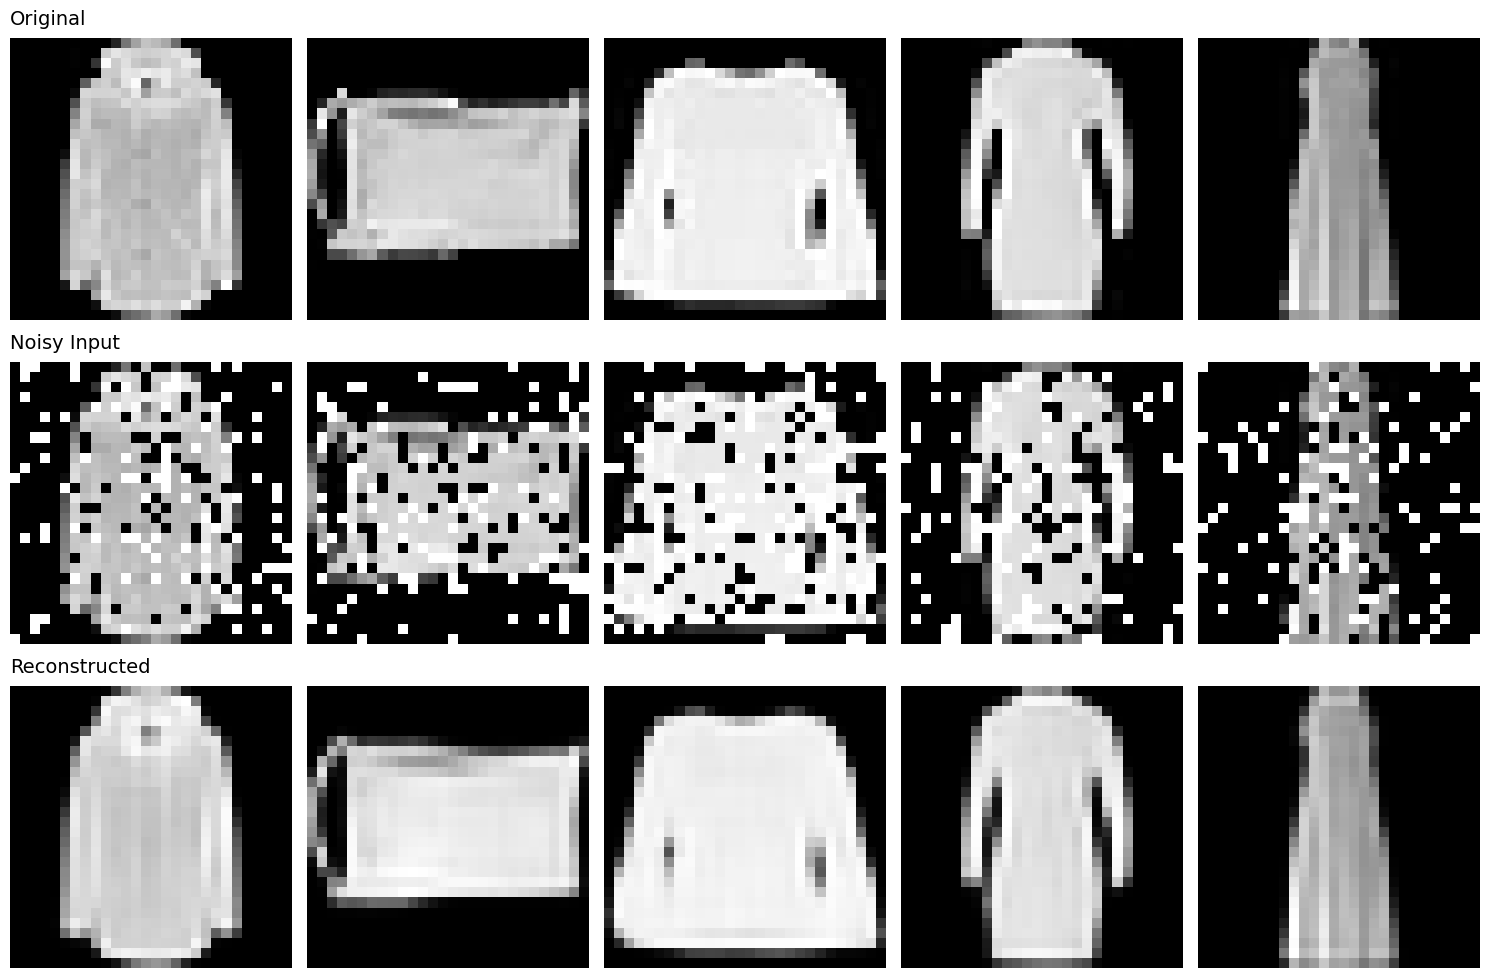

In [ ]:
EPOCHS = 100
LR = 1e-3
PARAM = 0.3

noise_name = "Salt_And_Pepper"
noise_fn = noise_functions[noise_name]
print(f"\n{'='*30}\nEXPERIMENT: Noise Type = {noise_name}\n{'='*30}")

for model_name, model_class in models_config.items():
    print(f"\n--- Training {model_name} on {noise_name} noise ---")

    model = model_class().to(device)
    optimizer = optim.Adam(model.parameters(), lr=LR)

    early_stop = EarlyStopping(patience=10, min_delta=0.0001, verbose=False,
                                path=f"Denoising_{model_name}_{noise_name}_03.pth")

    history = perform_denoising_learning(
        model, EPOCHS, optimizer, train_loader, val_loader, device,
        noise_function=noise_fn,
        noise_parameter=PARAM,
        early_stopping=early_stop
    )

    denoising_history_03[noise_name][model_name] = {
        "history": history,
        "model_state": model.state_dict()
    }

    plot_denoising_history(history, model_name, noise_name, (0, 0.03))

    print(f"Visual results for {model_name} ({noise_name}):")
    visualize_denoising(model, val_loader, device, noise_fn, PARAM, n=5)

    del model
    torch.cuda.empty_cache()


EXPERIMENT: Noise Type = Speckle

--- Training Deep_v3 on Speckle noise ---
Epoch [1/100] - 1.90s
  Train MSE Loss: 0.0572 | Val MSE Loss: 0.0356
Epoch [2/100] - 1.80s
  Train MSE Loss: 0.0292 | Val MSE Loss: 0.0254
Epoch [3/100] - 1.85s
  Train MSE Loss: 0.0230 | Val MSE Loss: 0.0220
Epoch [4/100] - 1.88s
  Train MSE Loss: 0.0210 | Val MSE Loss: 0.0202
Epoch [5/100] - 1.91s
  Train MSE Loss: 0.0193 | Val MSE Loss: 0.0186
Epoch [6/100] - 2.17s
  Train MSE Loss: 0.0181 | Val MSE Loss: 0.0174
Epoch [7/100] - 2.23s
  Train MSE Loss: 0.0171 | Val MSE Loss: 0.0169
Epoch [8/100] - 1.89s
  Train MSE Loss: 0.0163 | Val MSE Loss: 0.0160
Epoch [9/100] - 1.91s
  Train MSE Loss: 0.0156 | Val MSE Loss: 0.0155
Epoch [10/100] - 1.93s
  Train MSE Loss: 0.0150 | Val MSE Loss: 0.0146
Epoch [11/100] - 1.90s
  Train MSE Loss: 0.0145 | Val MSE Loss: 0.0143
Epoch [12/100] - 2.15s
  Train MSE Loss: 0.0140 | Val MSE Loss: 0.0138
Epoch [13/100] - 2.22s
  Train MSE Loss: 0.0136 | Val MSE Loss: 0.0135
Epoch [14

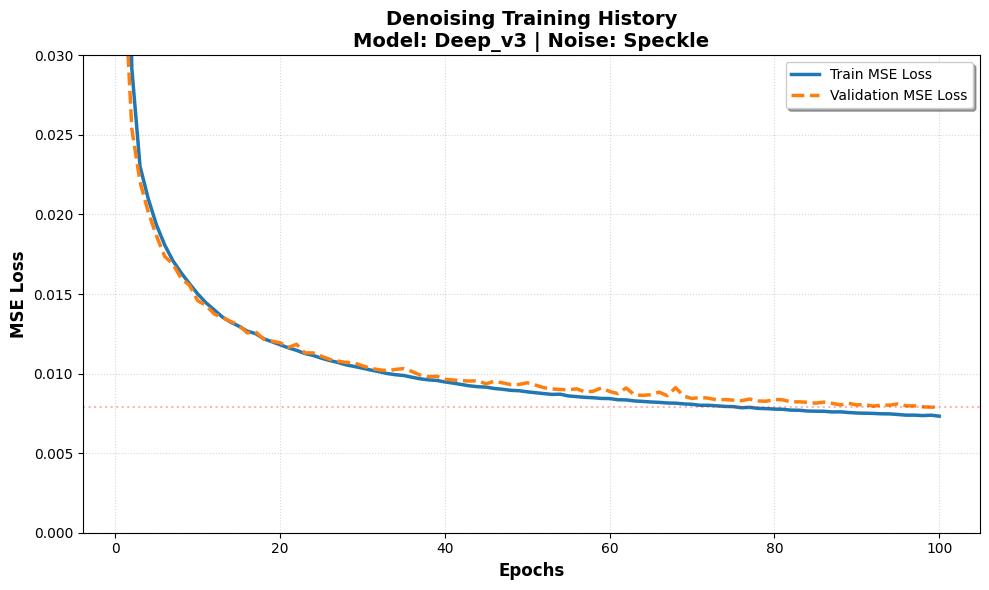

Visual results for Deep_v3 (Speckle):


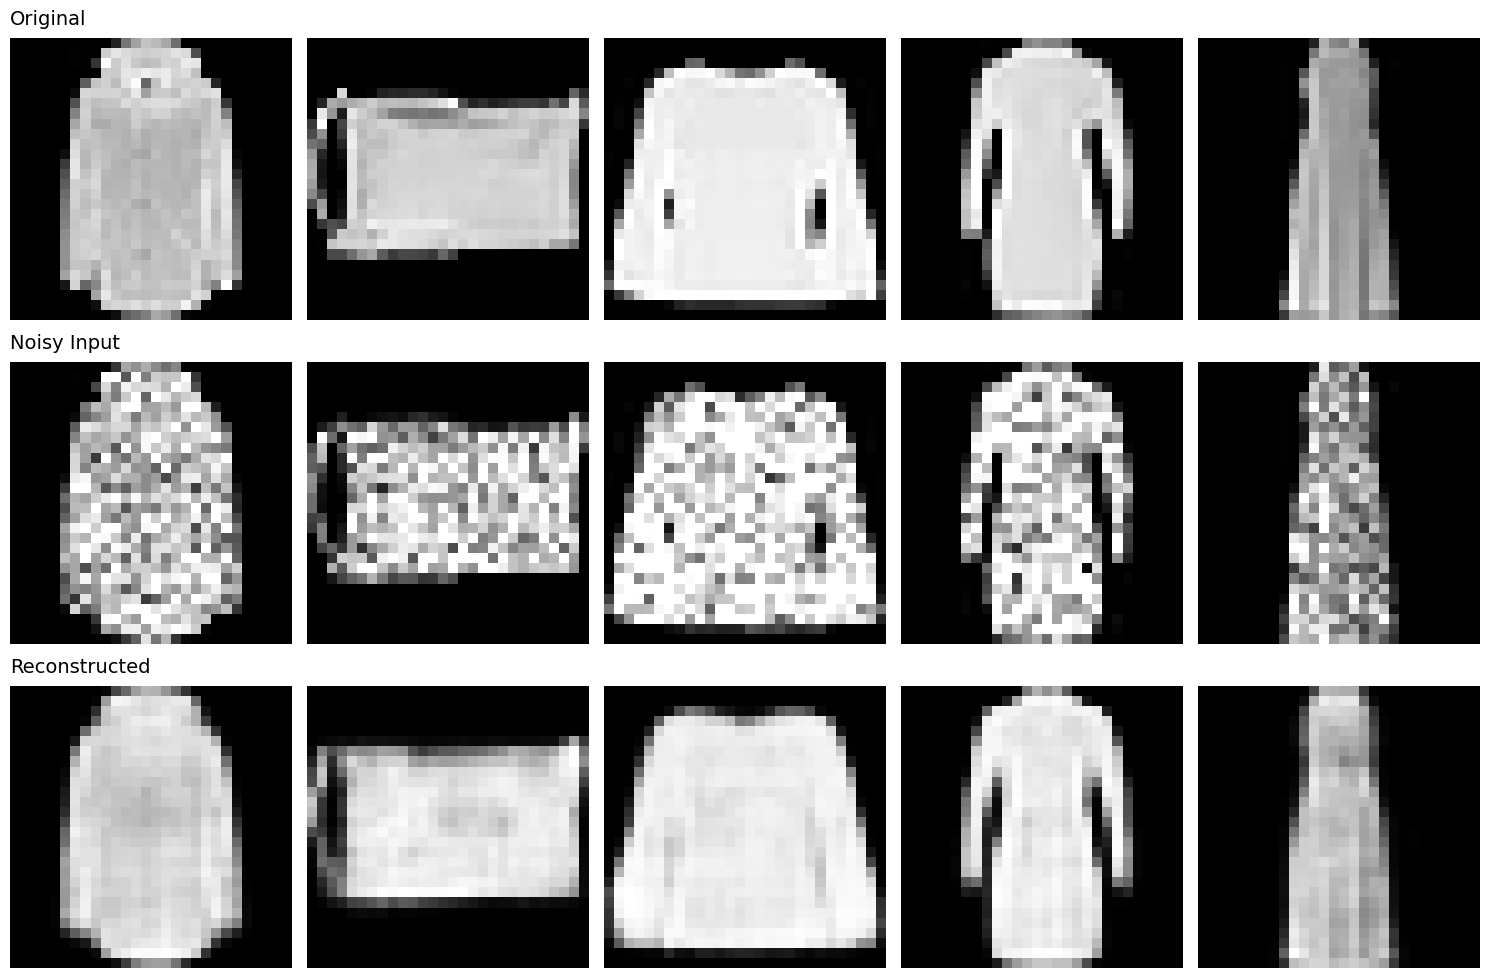


--- Training Conv_v3 on Speckle noise ---
Epoch [1/100] - 3.98s
  Train MSE Loss: 0.0306 | Val MSE Loss: 0.0199
Epoch [2/100] - 4.07s
  Train MSE Loss: 0.0166 | Val MSE Loss: 0.0156
Epoch [3/100] - 4.04s
  Train MSE Loss: 0.0139 | Val MSE Loss: 0.0156
Epoch [4/100] - 3.95s
  Train MSE Loss: 0.0125 | Val MSE Loss: 0.0120
Epoch [5/100] - 4.10s
  Train MSE Loss: 0.0116 | Val MSE Loss: 0.0113
Epoch [6/100] - 4.11s
  Train MSE Loss: 0.0109 | Val MSE Loss: 0.0102
Epoch [7/100] - 3.94s
  Train MSE Loss: 0.0104 | Val MSE Loss: 0.0112
Epoch [8/100] - 4.12s
  Train MSE Loss: 0.0100 | Val MSE Loss: 0.0095
Epoch [9/100] - 4.10s
  Train MSE Loss: 0.0095 | Val MSE Loss: 0.0094
Epoch [10/100] - 3.95s
  Train MSE Loss: 0.0091 | Val MSE Loss: 0.0087
Epoch [11/100] - 4.09s
  Train MSE Loss: 0.0089 | Val MSE Loss: 0.0112
Epoch [12/100] - 4.12s
  Train MSE Loss: 0.0089 | Val MSE Loss: 0.0096
Epoch [13/100] - 3.97s
  Train MSE Loss: 0.0085 | Val MSE Loss: 0.0082
Epoch [14/100] - 4.07s
  Train MSE Loss: 0.

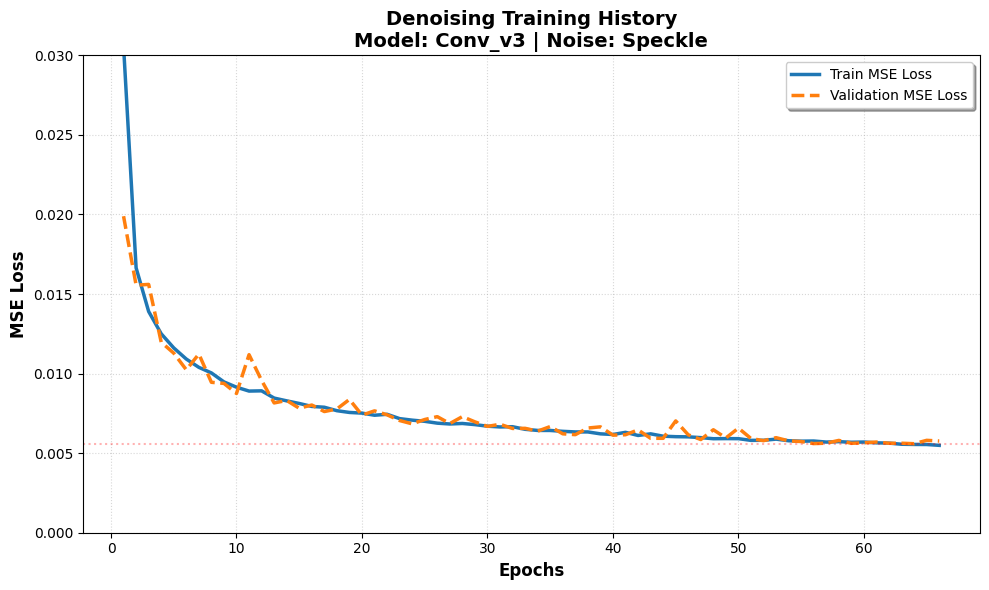

Visual results for Conv_v3 (Speckle):


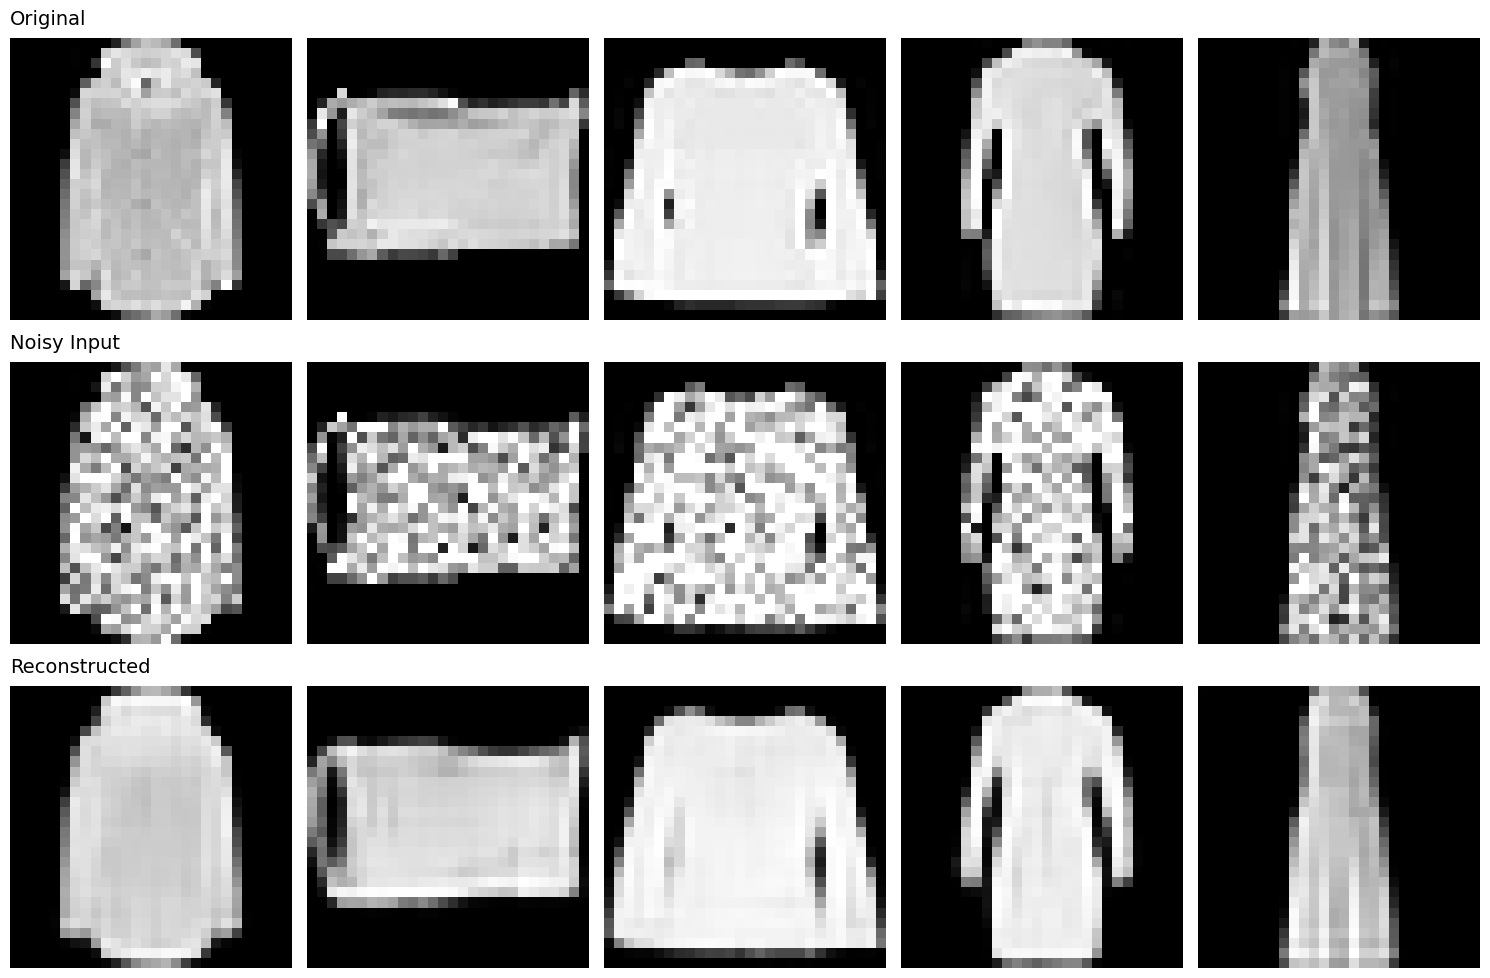


--- Training Res_v4 on Speckle noise ---
Epoch [1/100] - 11.96s
  Train MSE Loss: 0.0226 | Val MSE Loss: 0.0137
Epoch [2/100] - 11.97s
  Train MSE Loss: 0.0115 | Val MSE Loss: 0.0101
Epoch [3/100] - 12.01s
  Train MSE Loss: 0.0094 | Val MSE Loss: 0.0086
Epoch [4/100] - 12.03s
  Train MSE Loss: 0.0081 | Val MSE Loss: 0.0082
Epoch [5/100] - 12.03s
  Train MSE Loss: 0.0074 | Val MSE Loss: 0.0070
Epoch [6/100] - 12.05s
  Train MSE Loss: 0.0068 | Val MSE Loss: 0.0068
Epoch [7/100] - 12.04s
  Train MSE Loss: 0.0066 | Val MSE Loss: 0.0066
Epoch [8/100] - 12.04s
  Train MSE Loss: 0.0060 | Val MSE Loss: 0.0063
Epoch [9/100] - 12.03s
  Train MSE Loss: 0.0058 | Val MSE Loss: 0.0061
Epoch [10/100] - 12.04s
  Train MSE Loss: 0.0056 | Val MSE Loss: 0.0057
Epoch [11/100] - 12.03s
  Train MSE Loss: 0.0055 | Val MSE Loss: 0.0056
Epoch [12/100] - 12.02s
  Train MSE Loss: 0.0053 | Val MSE Loss: 0.0054
Epoch [13/100] - 12.05s
  Train MSE Loss: 0.0051 | Val MSE Loss: 0.0052
Epoch [14/100] - 12.06s
  Train

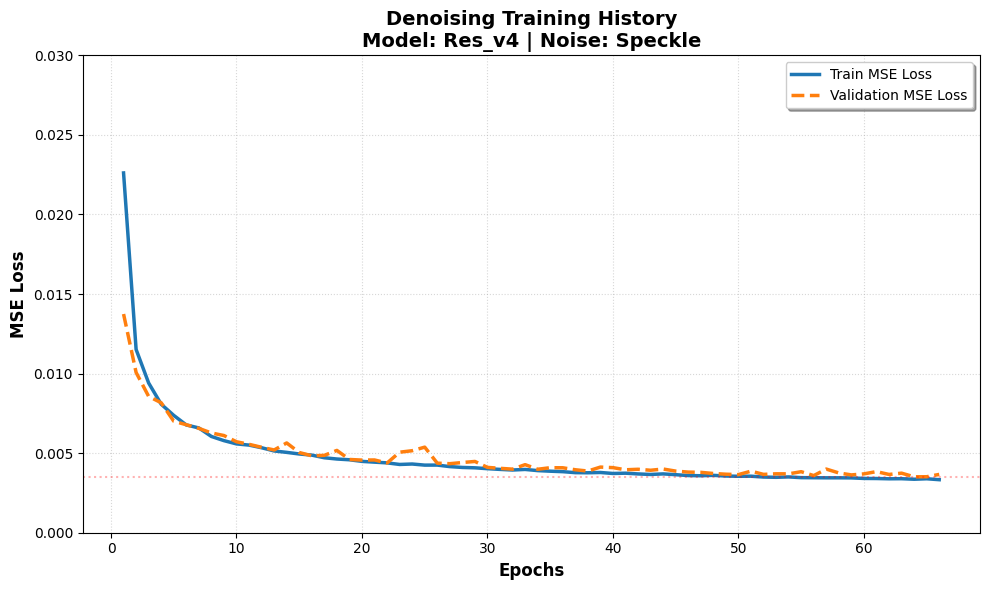

Visual results for Res_v4 (Speckle):


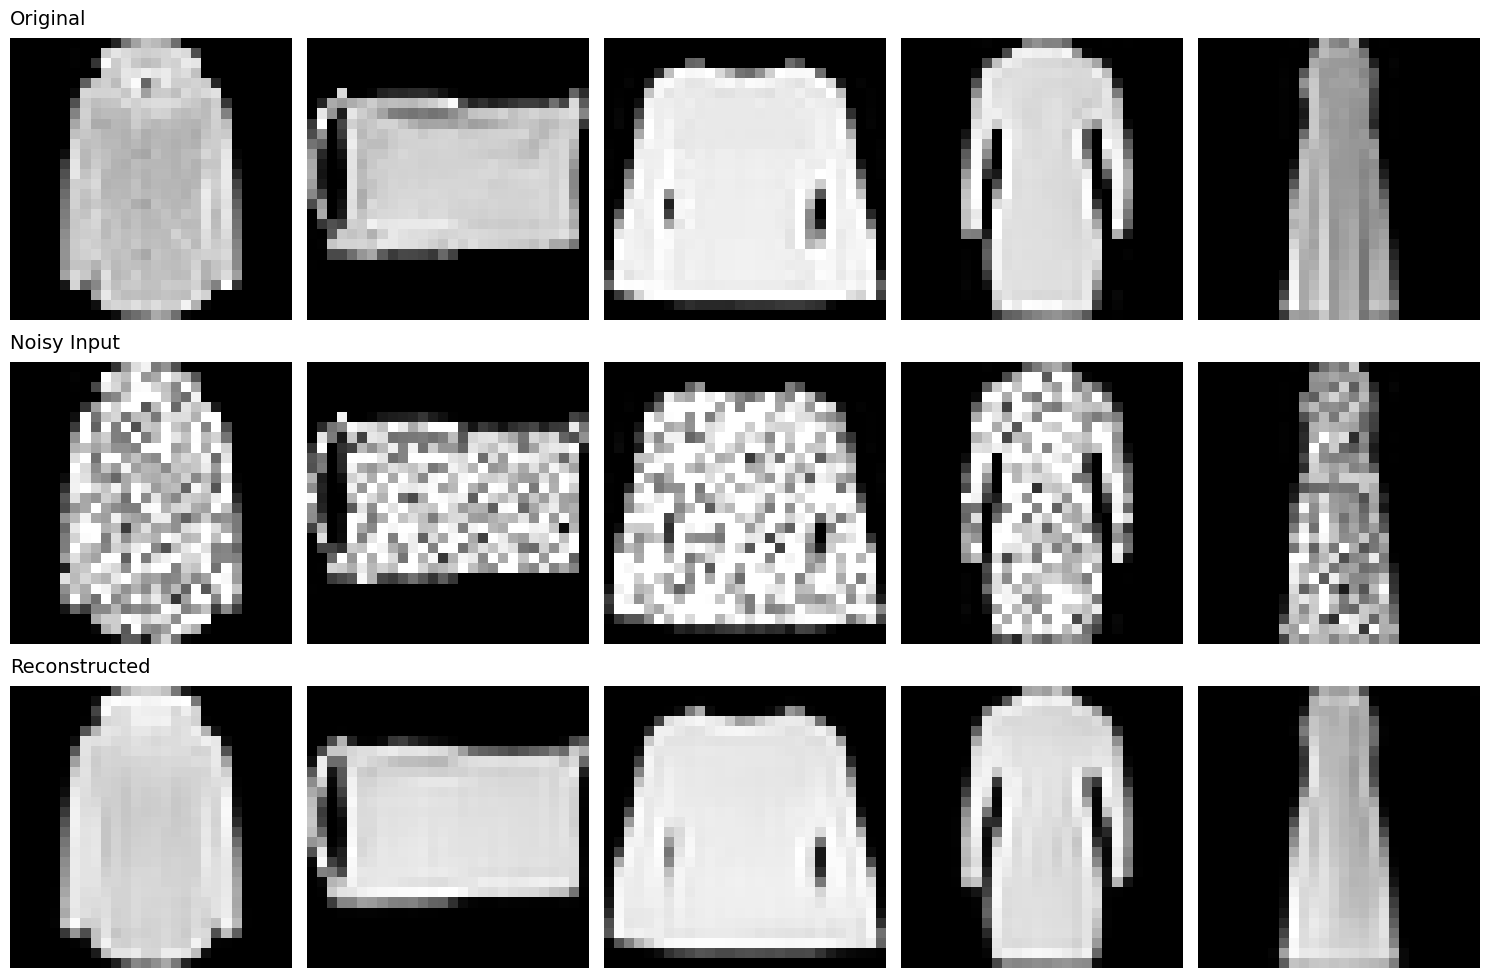

In [ ]:
EPOCHS = 100
LR = 1e-3
PARAM = 0.3

noise_name = "Speckle"
noise_fn = noise_functions[noise_name]
print(f"\n{'='*30}\nEXPERIMENT: Noise Type = {noise_name}\n{'='*30}")

for model_name, model_class in models_config.items():
    print(f"\n--- Training {model_name} on {noise_name} noise ---")

    model = model_class().to(device)
    optimizer = optim.Adam(model.parameters(), lr=LR)

    early_stop = EarlyStopping(patience=10, min_delta=0.0001, verbose=False,
                                path=f"Denoising_{model_name}_{noise_name}_03.pth")

    history = perform_denoising_learning(
        model, EPOCHS, optimizer, train_loader, val_loader, device,
        noise_function=noise_fn,
        noise_parameter=PARAM,
        early_stopping=early_stop
    )

    denoising_history_03[noise_name][model_name] = {
        "history": history,
        "model_state": model.state_dict()
    }

    plot_denoising_history(history, model_name, noise_name, (0, 0.03))

    print(f"Visual results for {model_name} ({noise_name}):")
    visualize_denoising(model, val_loader, device, noise_fn, PARAM, n=5)

    del model
    torch.cuda.empty_cache()

In [ ]:
def plot_latent_interpolation_by_index(model, loader, device, idx1, idx2, n_steps=10, max_cols=10):
    model.eval()
    dataset = loader.dataset

    with torch.no_grad():
        img1, label1 = dataset[idx1]
        img2, label2 = dataset[idx2]

        if img1.dim() == 1:
            img1 = img1.view(1, 28, 28)
            img2 = img2.view(1, 28, 28)

        img1 = img1.unsqueeze(0).to(device)
        img2 = img2.unsqueeze(0).to(device)

        latent_image1 = model.encoder(img1)
        latent_image2 = model.encoder(img2)

        n_rows = math.ceil(n_steps / max_cols)
        plt.figure(figsize=(18, 3 * n_rows))

        alphas = torch.linspace(0, 1, steps=n_steps).to(device)

        for i, alpha in enumerate(alphas):
            image_interpolation = (1 - alpha) * latent_image1 + alpha * latent_image2
            reconstructed = model.decoder(image_interpolation)

            plt.subplot(n_rows, max_cols, i + 1)
            plt.imshow(reconstructed.cpu().squeeze(), cmap='gray')
            plt.title(f"{int(alpha*100)}%")
            plt.axis('off')

        plt.suptitle(f"Interpolation: Index {idx1} (Label {label1}) to Index {idx2} (Label {label2})",
                     fontsize=16, y=1.02)
        plt.tight_layout()
        plt.show()

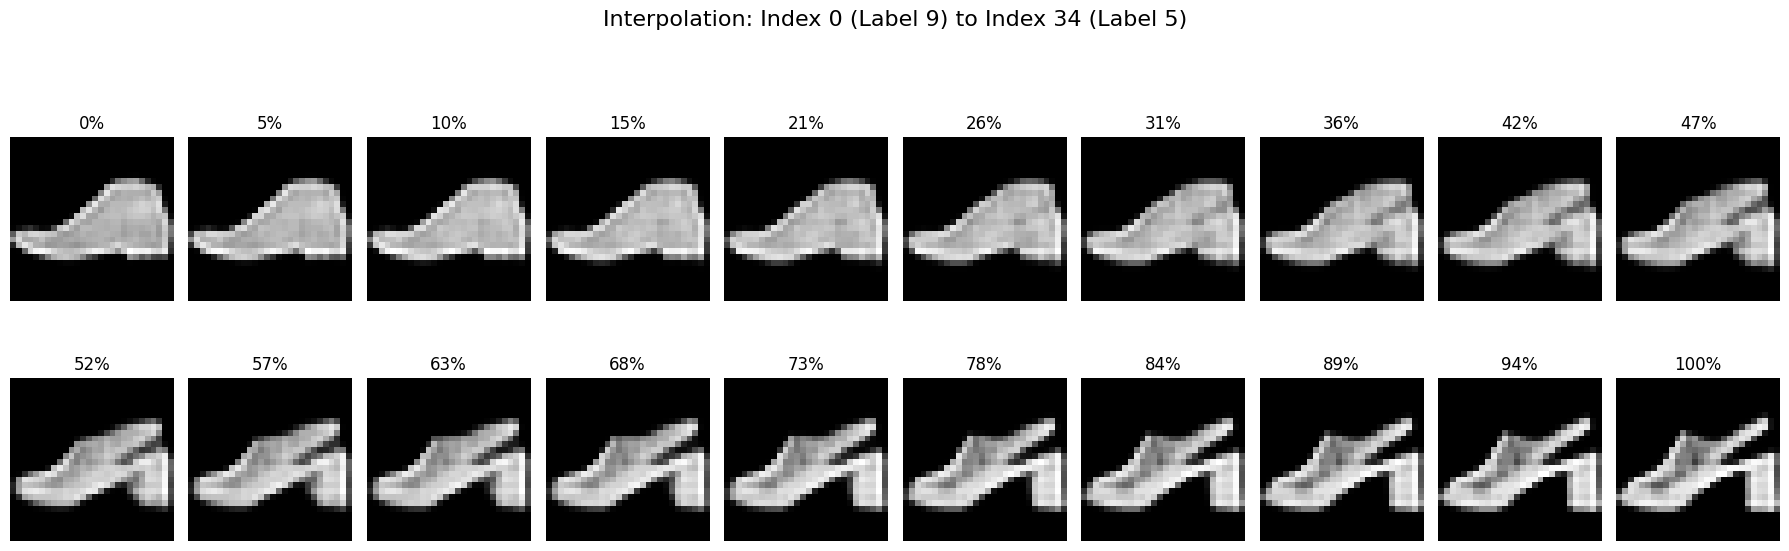

In [ ]:
plot_latent_interpolation_by_index(convolutional_autoencoder_model_v4, val_loader, device, idx1=0, idx2=34, n_steps=20)

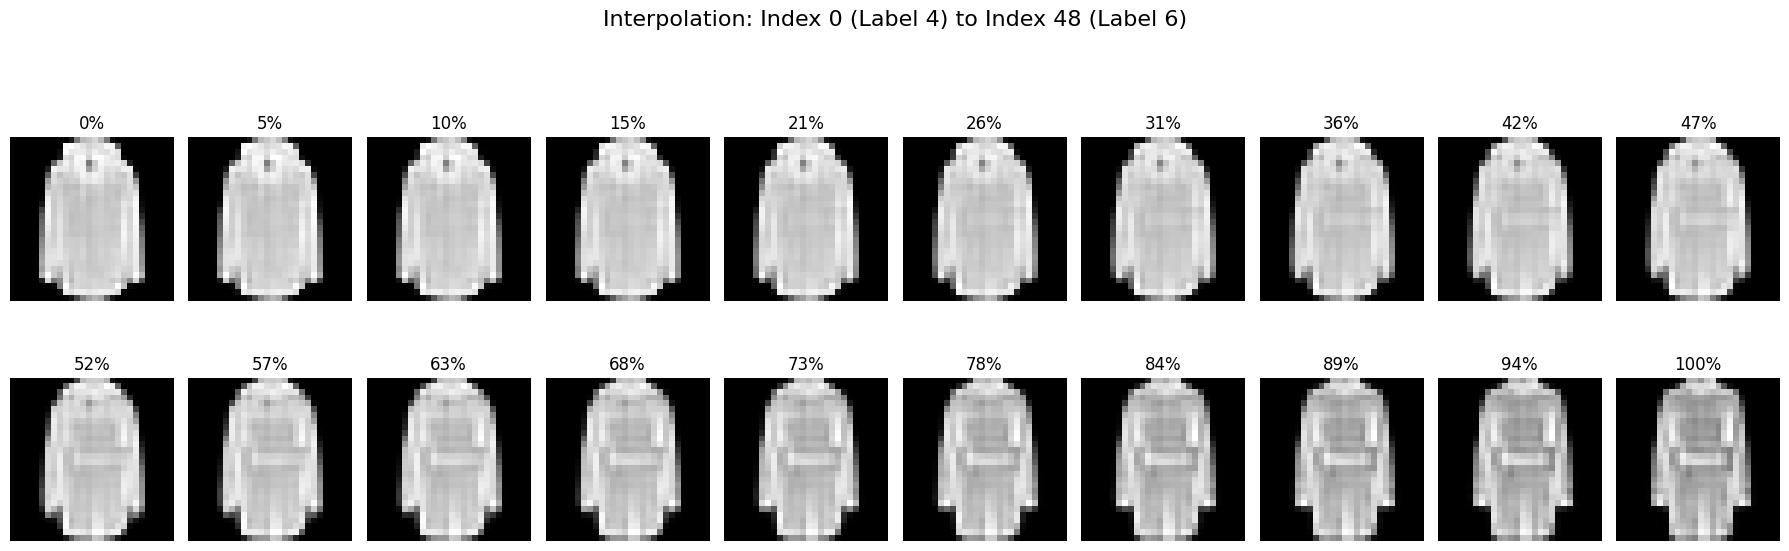

In [ ]:
plot_latent_interpolation_by_index(convolutional_autoencoder_model_v4, val_loader, device, idx1=0, idx2=48, n_steps=20)

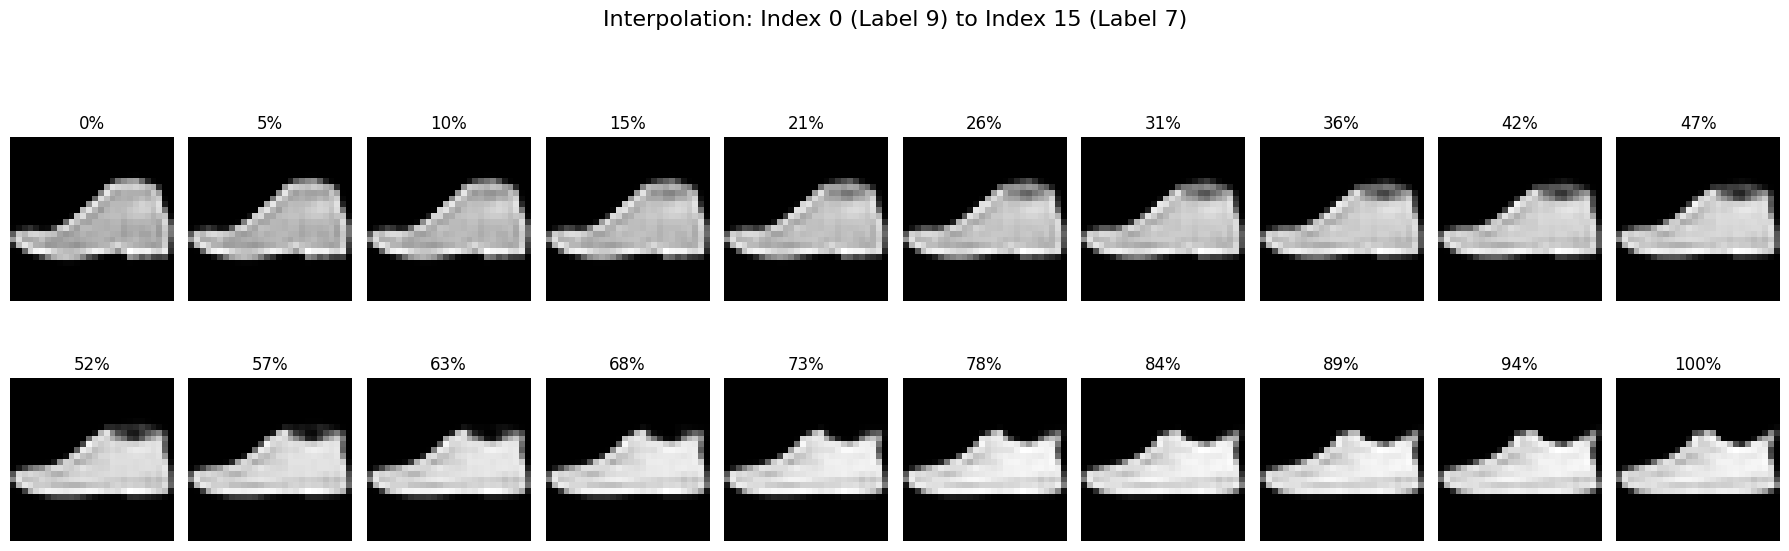

In [ ]:
plot_latent_interpolation_by_index(convolutional_autoencoder_model_v4, val_loader, device, idx1=0, idx2=15, n_steps=20)

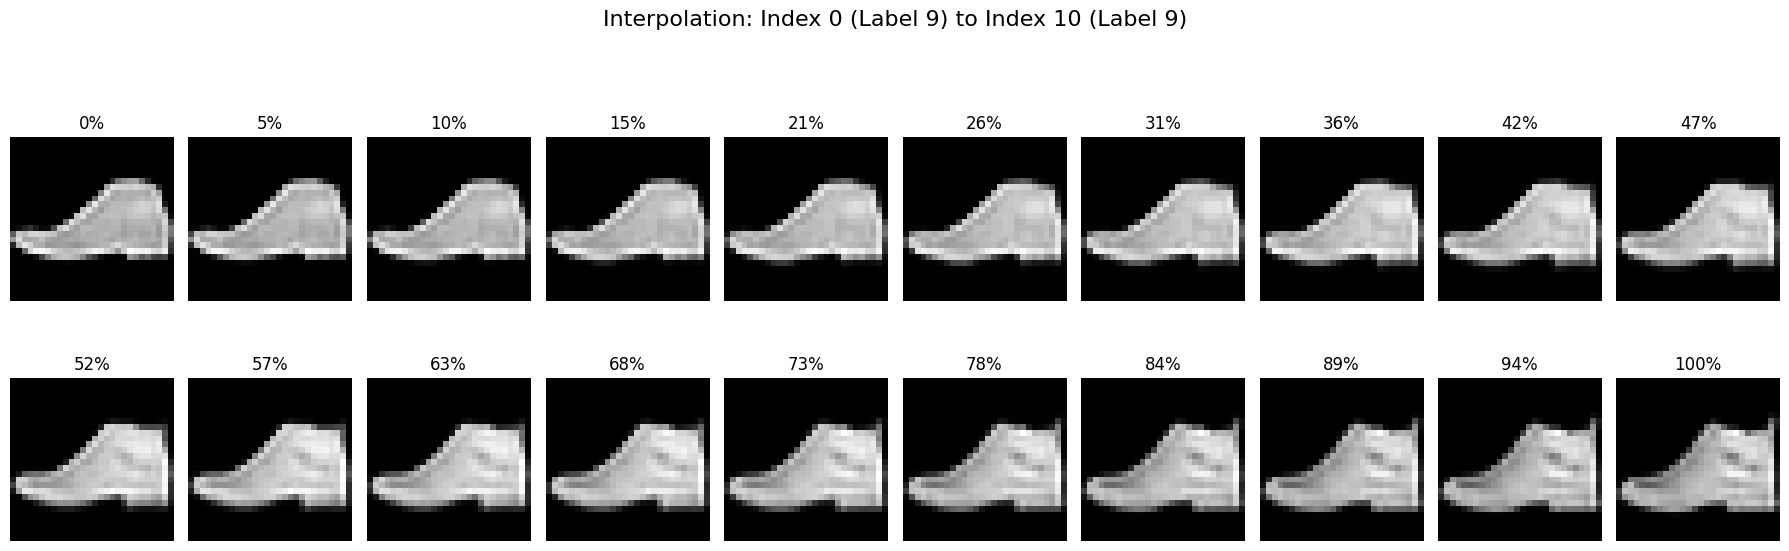

In [ ]:
plot_latent_interpolation_by_index(convolutional_autoencoder_model_v4, val_loader, device, idx1=0, idx2=10, n_steps=20)

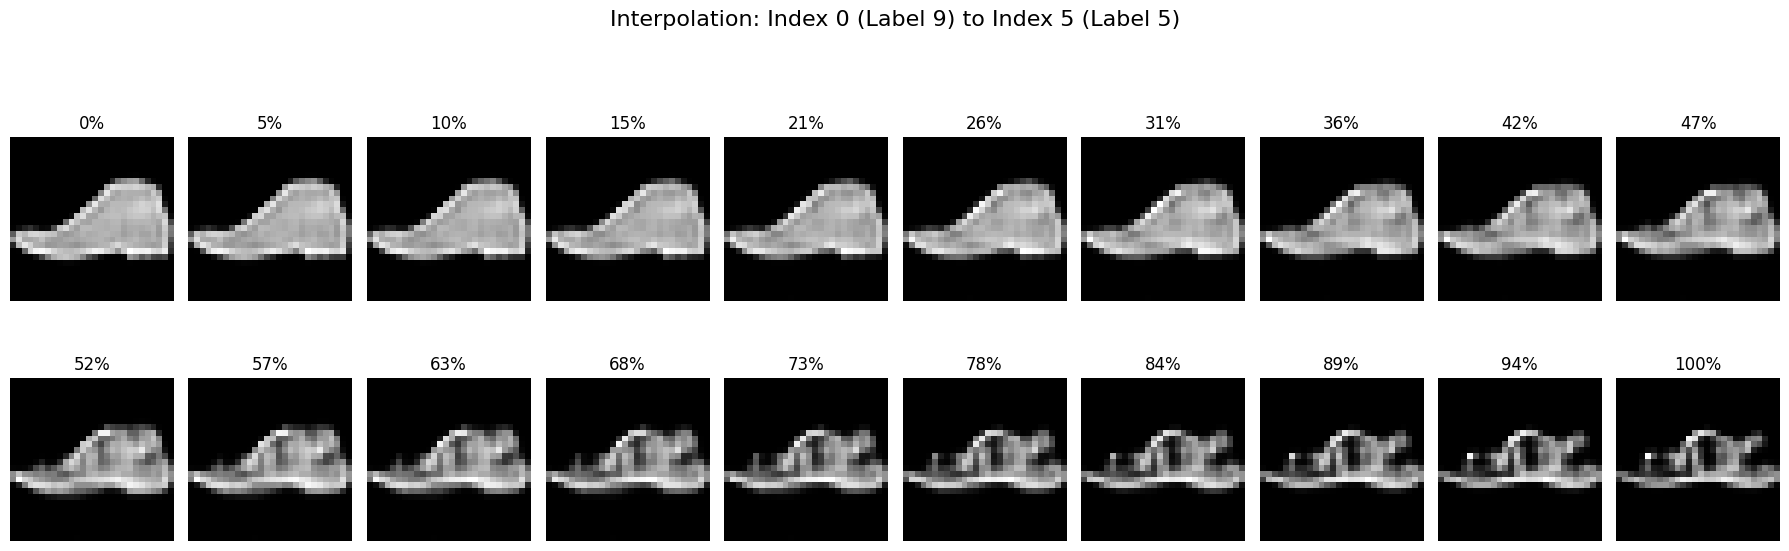

In [ ]:
plot_latent_interpolation_by_index(convolutional_autoencoder_model_v4, val_loader, device, idx1=0, idx2=5, n_steps=20)

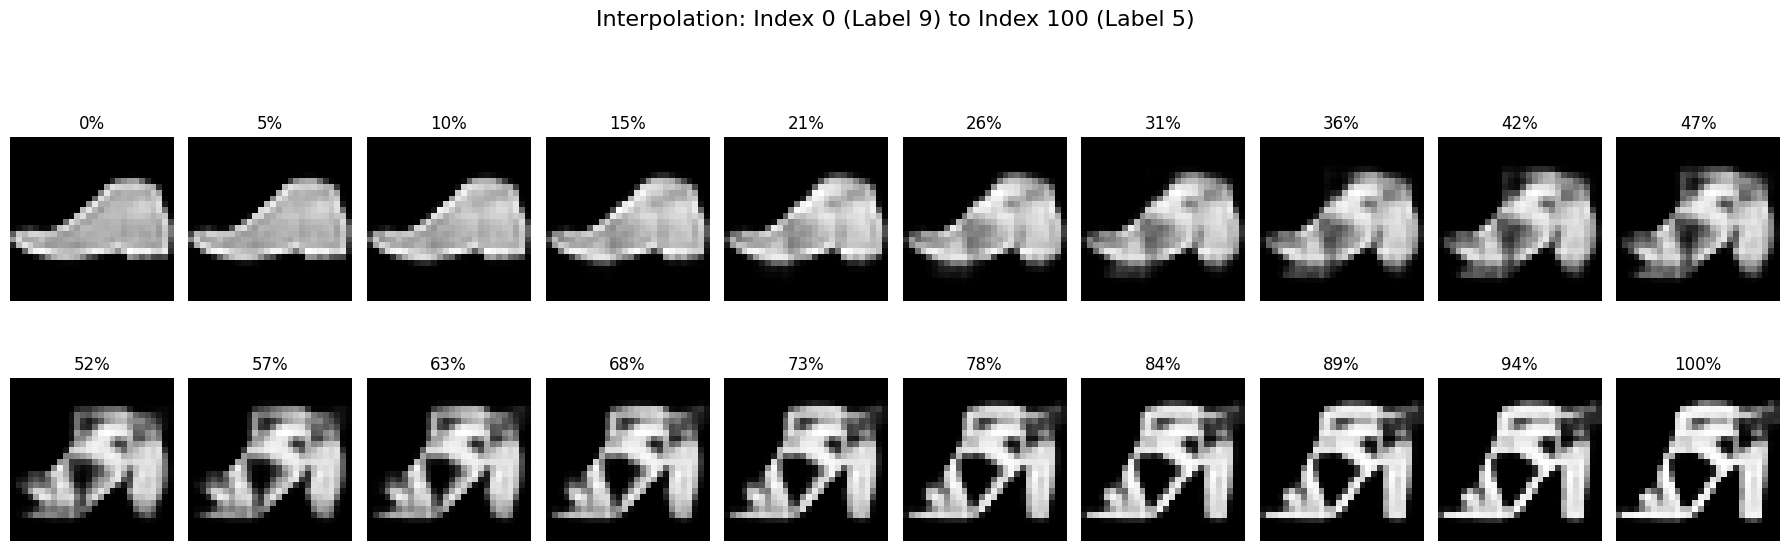

In [ ]:
plot_latent_interpolation_by_index(convolutional_autoencoder_model_v4, val_loader, device, idx1=0, idx2=100, n_steps=20)

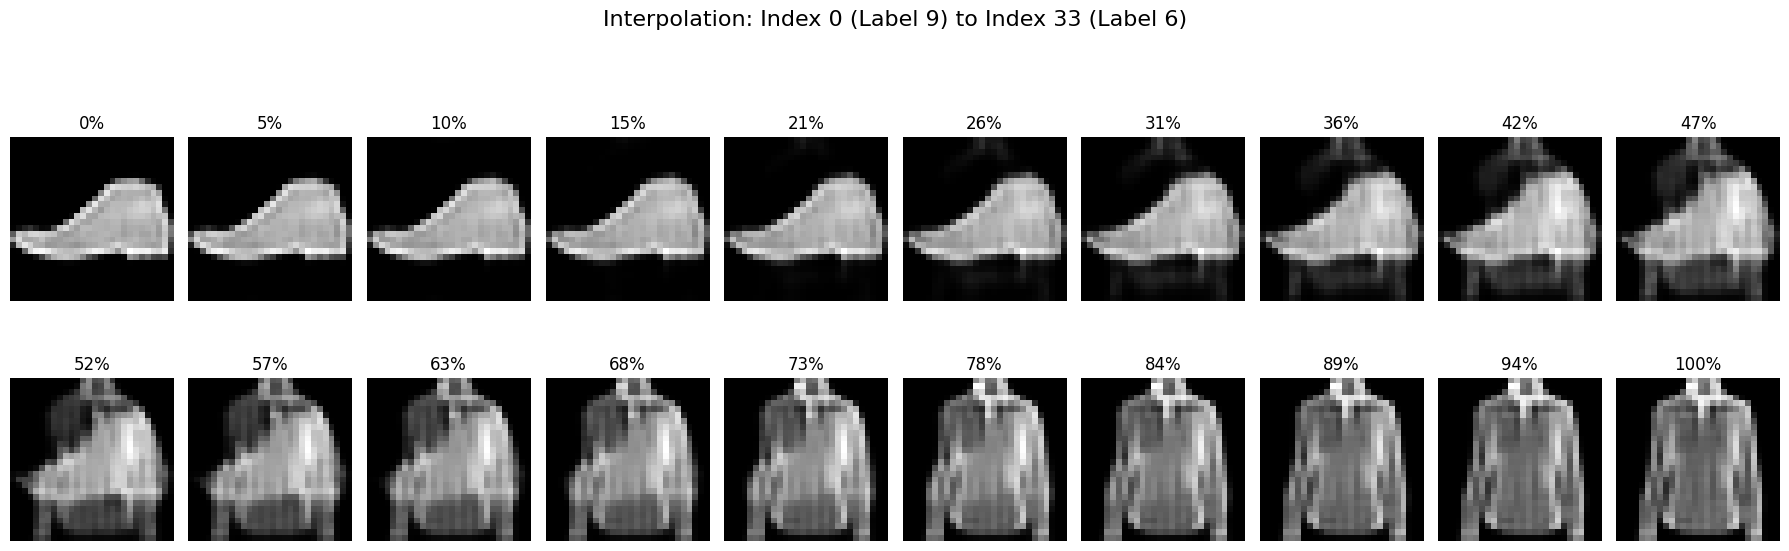

In [ ]:
plot_latent_interpolation_by_index(convolutional_autoencoder_model_v4, val_loader, device, idx1=0, idx2=33, n_steps=20)

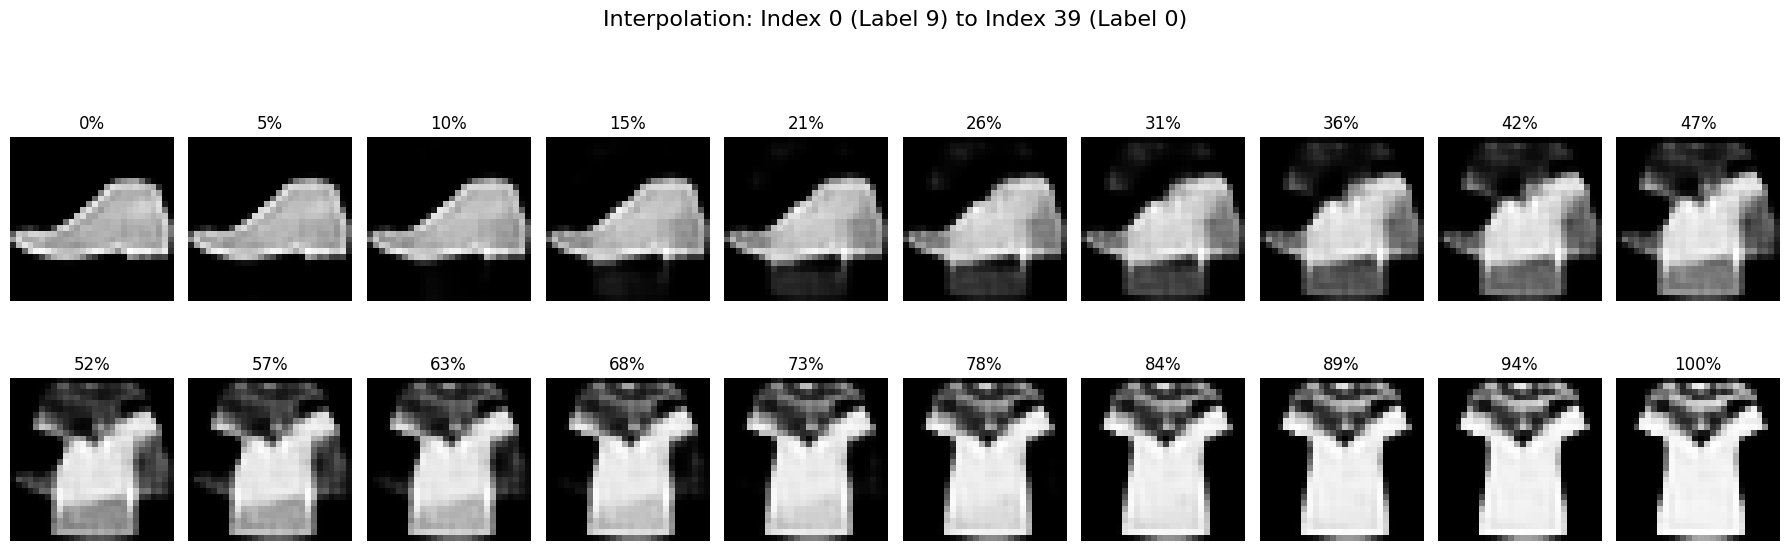

In [ ]:
plot_latent_interpolation_by_index(convolutional_autoencoder_model_v4, val_loader, device, idx1=0, idx2=39, n_steps=20)

In [ ]:
class ConvolutionalVAE(nn.Module):
    def __init__(self, latent_dim=64):
        super(ConvolutionalVAE, self).__init__()

        self.encoder_conv = nn.Sequential(
            nn.Conv2d(1, 32, 3, stride=2, padding=1), #32x14x14
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.Conv2d(32, 64, 3, stride=2, padding=1), #64x7x7
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.Flatten() #64 * 7 * 7 = 3136
        )

        self.fc_mu = nn.Linear(64 * 7 * 7, latent_dim)
        self.fc_logvar = nn.Linear(64 * 7 * 7, latent_dim)

        self.decoder_input = nn.Linear(latent_dim, 64 * 7 * 7)
        self.decoder_conv = nn.Sequential(
            nn.Unflatten(1, (64, 7, 7)),
            nn.ConvTranspose2d(64, 32, 3, stride=2, padding=1, output_padding=1), #32x14x14
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.ConvTranspose2d(32, 1, 3, stride=2, padding=1, output_padding=1), #1x28x28
            nn.Sigmoid()
        )

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def forward(self, x):
        if x.dim() == 2:
            x = x.view(-1, 1, 28, 28)

        x_encoded = self.encoder_conv(x)
        mu = self.fc_mu(x_encoded)
        logvar = self.fc_logvar(x_encoded)

        z = self.reparameterize(mu, logvar)
        z_expanded = self.decoder_input(z)
        reconstructed = self.decoder_conv(z_expanded)

        return reconstructed, mu, logvar

In [ ]:
def vae_loss_function(recon_x, x, mu, logvar):
    bce_criterion = nn.BCELoss(reduction='sum')
    BCE_sum = bce_criterion(recon_x, x.view_as(recon_x))

    mse_criterion = nn.MSELoss(reduction='mean')
    mean_mse = mse_criterion(recon_x, x.view_as(recon_x))
    KLD = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())

    return BCE_sum + KLD, BCE_sum, KLD, mean_mse

In [ ]:
def evaluate_vae_model(model, loader, device):
    model.eval()
    total_loss = 0
    total_mse = 0
    with torch.no_grad():
        for images, _ in loader:
            images = images.to(device)
            recon, mu, logvar = model(images)
            loss, _, _, mse = vae_loss_function(recon, images, mu, logvar)
            total_loss += loss.item()
            total_mse += mse.item()

    return total_loss / len(loader.dataset), total_mse / len(loader)

In [ ]:
def perform_vae_learning(model, EPOCHS, optimizer, train_loader, val_loader, device, early_stopping=None):
    history = {
        'train_loss': [],
        'val_loss': [],
        'train_kld': [],
        'train_mse': [],
        'val_mse': [],
        'epoch_time': []
    }

    for epoch in range(EPOCHS):
        start_time = time.time()
        model.train()

        running_loss = 0.0
        running_kld = 0.0
        running_mse = 0.0

        for images, _ in train_loader:
            images = images.to(device)
            optimizer.zero_grad()

            recon_images, mu, logvar = model(images)

            loss, bce, kld, mse = vae_loss_function(recon_images, images, mu, logvar)

            loss.backward()
            optimizer.step()

            running_loss += loss.item()
            running_kld += kld.item()
            running_mse += mse.item()

        epoch_loss = running_loss / len(train_loader.dataset)
        epoch_kld = running_kld / len(train_loader.dataset)

        epoch_mse = running_mse / len(train_loader)

        val_loss, val_mse = evaluate_vae_model(model, val_loader, device)

        epoch_duration = time.time() - start_time

        history['train_loss'].append(epoch_loss)
        history['val_loss'].append(val_loss)
        history['train_kld'].append(epoch_kld)
        history['train_mse'].append(epoch_mse)
        history['val_mse'].append(val_mse)
        history['epoch_time'].append(epoch_duration)

        print(f"Epoch [{epoch+1}/{EPOCHS}] - {epoch_duration:.2f}s")
        print(f"  Train: Loss {epoch_loss:.2f} | KLD {epoch_kld:.2f} | MSE {epoch_mse:.5f}")
        print(f"  Val:   Loss {val_loss:.2f} | MSE {val_mse:.5f}")

        if early_stopping is not None:
            early_stopping(val_loss, model)
            if early_stopping.early_stop:
                print("--- Early stopping triggered ---")
                model.load_state_dict(torch.load(early_stopping.path))
                break
        print("-" * 65)

    return history

In [ ]:
LATENT_DIM = 32
EPOCHS = 50
LR = 1e-3
vae_model = ConvolutionalVAE(latent_dim=LATENT_DIM).to(device)
optimizer = torch.optim.Adam(vae_model.parameters(), lr=LR)

early_stop_vae = EarlyStopping(patience=5, verbose=False, path="best_vae_model.pth")

In [ ]:
vae_model.load_state_dict(torch.load("best_vae_model.pth"))

<All keys matched successfully>

In [ ]:
print("Starting VAE Training...")
vae_history = perform_vae_learning(
    vae_model,
    EPOCHS,
    optimizer,
    train_loader,
    val_loader,
    device,
    early_stopping=early_stop_vae
)

Starting VAE Training...
Epoch [1/50] - 3.21s
  Train: Loss 317.41 | KLD 23.08 | MSE 0.04231
  Val:   Loss 275.72 | MSE 0.02506
-----------------------------------------------------------------
Epoch [2/50] - 2.17s
  Train: Loss 266.33 | KLD 23.23 | MSE 0.02207
  Val:   Loss 260.38 | MSE 0.02088
-----------------------------------------------------------------
Epoch [3/50] - 2.13s
  Train: Loss 257.50 | KLD 21.18 | MSE 0.01964
  Val:   Loss 254.69 | MSE 0.01894
-----------------------------------------------------------------
Epoch [4/50] - 2.08s
  Train: Loss 253.63 | KLD 20.16 | MSE 0.01857
  Val:   Loss 252.40 | MSE 0.01812
-----------------------------------------------------------------
Epoch [5/50] - 2.09s
  Train: Loss 251.80 | KLD 19.73 | MSE 0.01805
  Val:   Loss 250.41 | MSE 0.01768
-----------------------------------------------------------------
Epoch [6/50] - 2.38s
  Train: Loss 250.14 | KLD 19.42 | MSE 0.01750
  Val:   Loss 249.44 | MSE 0.01744
---------------------------

In [ ]:
def plot_vae_training_history(history, loss_ylim=None, kld_ylim=None, mse_ylim=None):
    epochs = range(1, len(history['train_loss']) + 1)

    plt.figure(figsize=(18, 5))

    plt.subplot(1, 3, 1)
    plt.plot(epochs, history['train_loss'], 'b-', label='Train Total Loss')
    plt.plot(epochs, history['val_loss'], 'r-', label='Val Total Loss')
    plt.title('Total Loss (BCE + KLD)')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    if loss_ylim: plt.ylim(loss_ylim)
    plt.legend()
    plt.grid(True)

    plt.subplot(1, 3, 2)
    plt.plot(epochs, history['train_kld'], 'g-', label='Train KLD')
    plt.title('KL-Divergence (Latent Regularization)')
    plt.xlabel('Epochs')
    plt.ylabel('KLD Value')
    if kld_ylim: plt.ylim(kld_ylim)
    plt.legend()
    plt.grid(True)

    plt.subplot(1, 3, 3)
    plt.plot(epochs, history['train_mse'], 'b--', label='Train MSE')
    plt.plot(epochs, history['val_mse'], 'r--', label='Val MSE')
    plt.title('Mean Squared Error (Reconstruction)')
    plt.xlabel('Epochs')
    plt.ylabel('MSE')
    if mse_ylim: plt.ylim(mse_ylim)
    plt.legend()
    plt.grid(True)

    plt.tight_layout()
    plt.show()

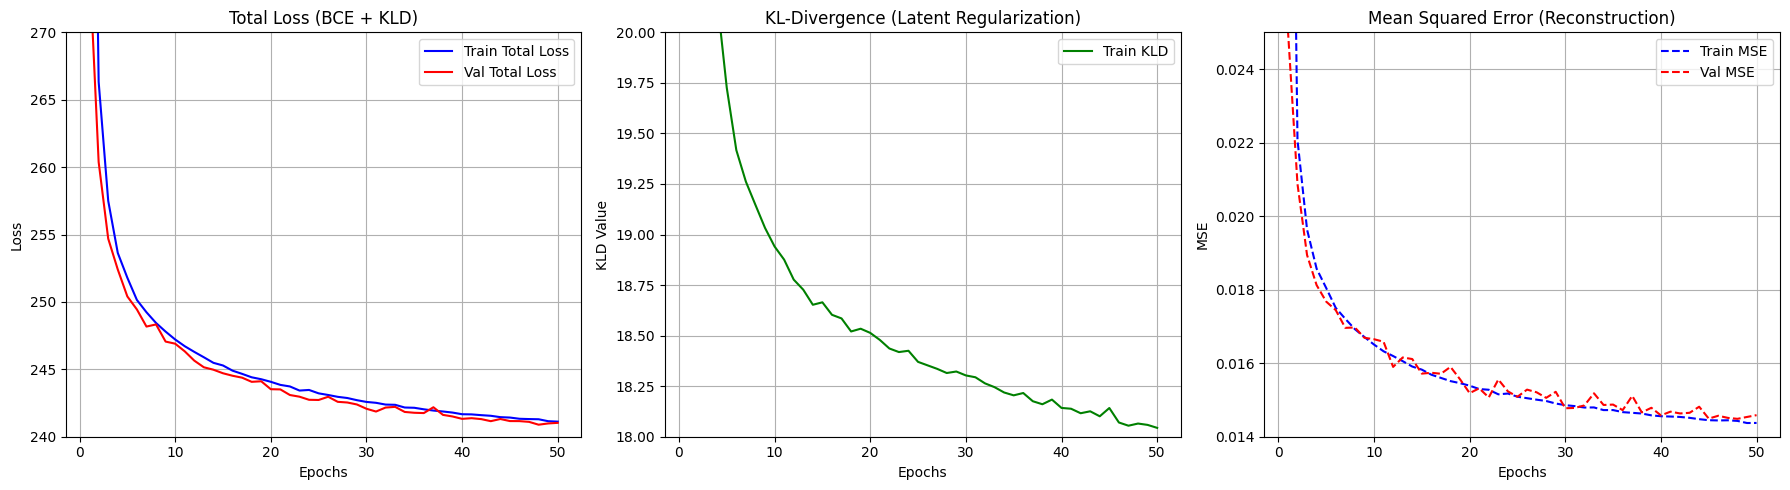

In [ ]:
plot_vae_training_history(vae_history, (240, 270), (18, 20), (0.014, 0.025))

In [ ]:
def generate_new_clothes(model, n_samples=10, latent_dim=32, device='cuda'):
    model.eval()
    with torch.no_grad():
        z = torch.randn(n_samples, latent_dim).to(device)

        z_expanded = model.decoder_input(z)
        generated = model.decoder_conv(z_expanded)

        plt.figure(figsize=(15, 3))
        for i in range(n_samples):
            plt.subplot(1, n_samples, i + 1)
            plt.imshow(generated[i].cpu().squeeze(), cmap='gray')
            plt.axis('off')
        plt.suptitle("Generated Clothes from Random Noise", fontsize=14)
        plt.show()

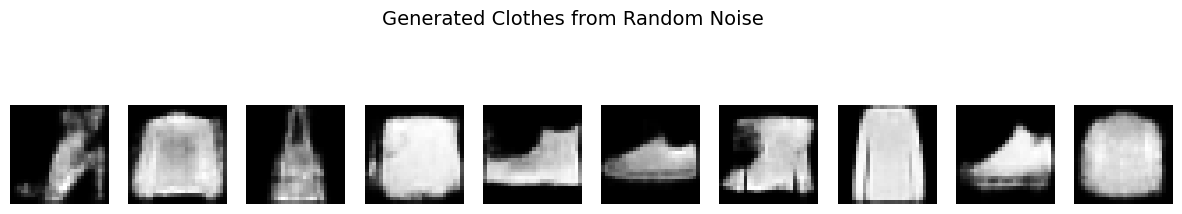

In [ ]:
generate_new_clothes(vae_model, latent_dim=32, device=device)

In [ ]:
def get_class_stats(model, loader, target_label, device):
    model.eval()
    all_mus = []
    all_logvars = []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            if images.dim() == 2:
                images = images.view(-1, 1, 28, 28)

            x_encoded = model.encoder_conv(images)
            mu = model.fc_mu(x_encoded)
            logvar = model.fc_logvar(x_encoded)

            mask = (labels == target_label)
            if mask.any():
                all_mus.append(mu[mask])
                all_logvars.append(logvar[mask])

    if len(all_mus) == 0:
        return None, None

    all_mus = torch.cat(all_mus, dim=0)
    all_logvars = torch.cat(all_logvars, dim=0)

    centroid_mu = all_mus.mean(dim=0)
    centroid_std = torch.exp(0.5 * all_logvars).mean(dim=0)

    return centroid_mu, centroid_std

In [ ]:
def generate_specific_clothes(model, centroid_mu, centroid_std, n_samples=10, noise_scale=1.0, device='cuda', label = "None"):
    model.eval()
    with torch.no_grad():
        mu = centroid_mu.repeat(n_samples, 1)
        std = centroid_std.repeat(n_samples, 1)

        eps = torch.randn_like(std) * noise_scale
        z = mu + eps * std

        z_expanded = model.decoder_input(z)
        generated = model.decoder_conv(z_expanded)

        plt.figure(figsize=(15, 3))
        for i in range(n_samples):
            plt.subplot(1, n_samples, i + 1)
            plt.imshow(generated[i].cpu().squeeze(), cmap='gray')
            plt.axis('off')
        plt.suptitle(f"Generated Clothes of class: {label}", fontsize=14)
        plt.show()

In [ ]:
fashion_mnist_labels = {
    0: "T-shirt/top",
    1: "Trouser",
    2: "Pullover",
    3: "Dress",
    4: "Coat",
    5: "Sandal",
    6: "Shirt",
    7: "Sneaker",
    8: "Bag",
    9: "Ankle boot"
}

Генерація для класу T-shirt/top...


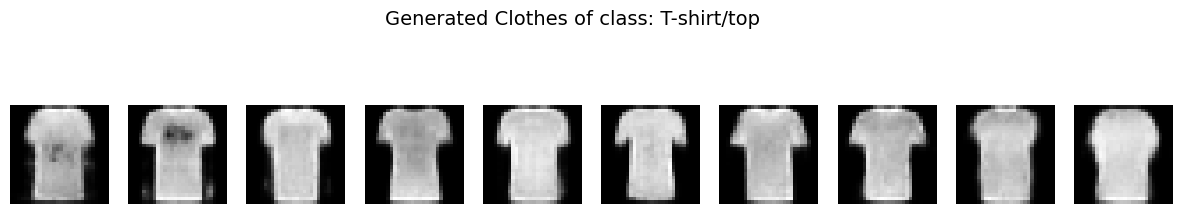

Генерація для класу Trouser...


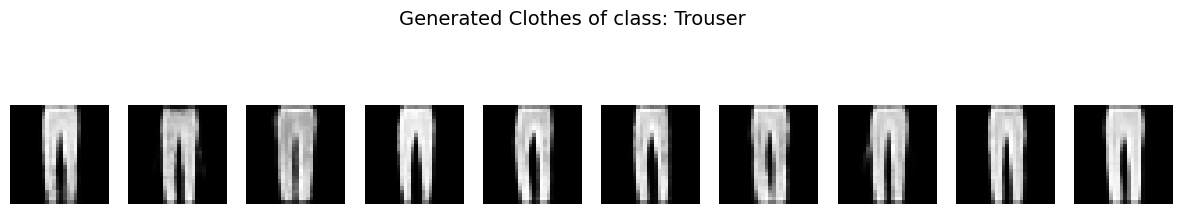

Генерація для класу Pullover...


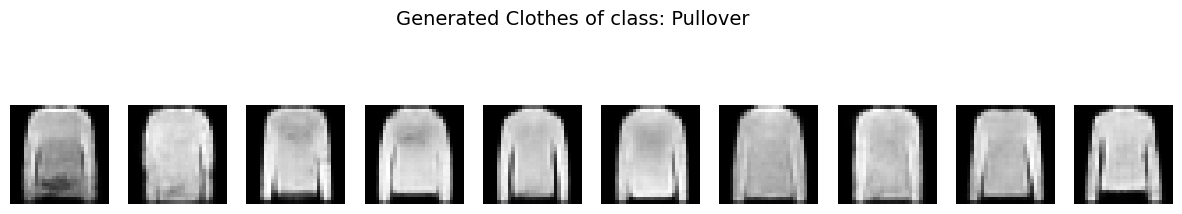

Генерація для класу Dress...


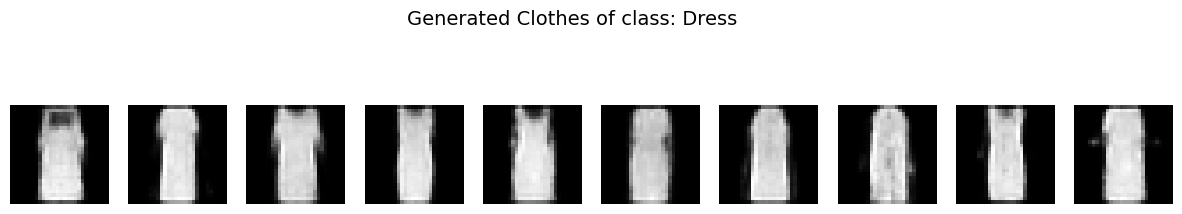

Генерація для класу Coat...


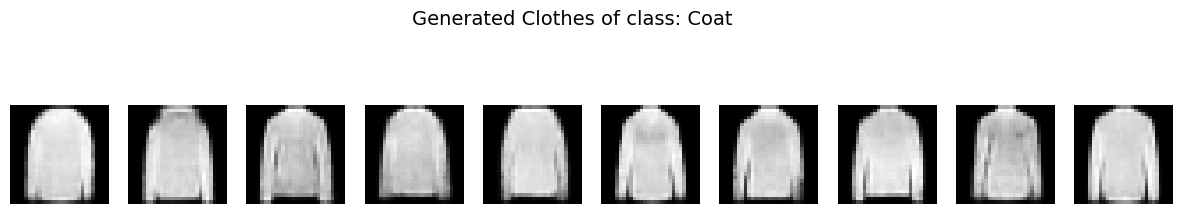

Генерація для класу Sandal...


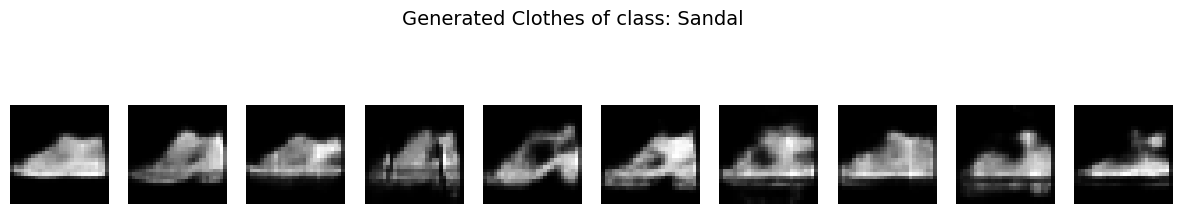

Генерація для класу Shirt...


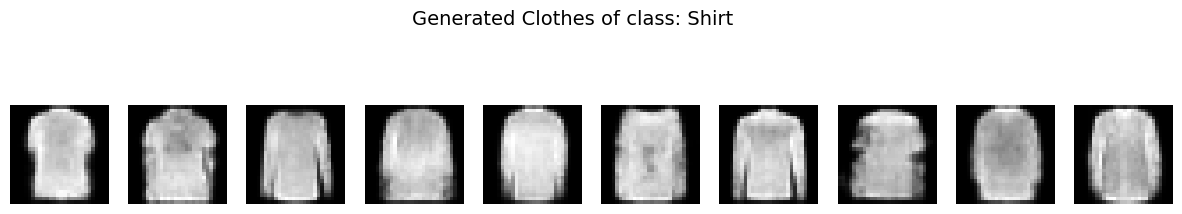

Генерація для класу Sneaker...


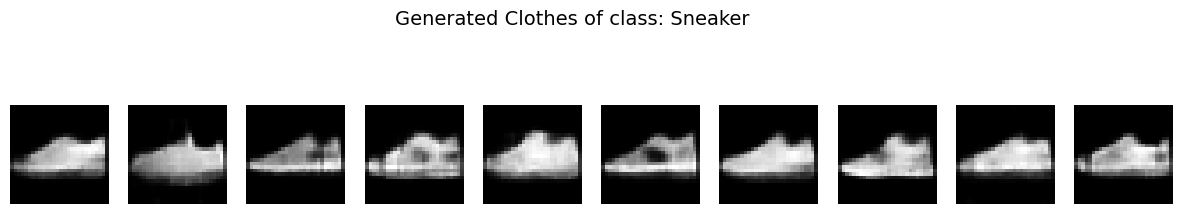

Генерація для класу Bag...


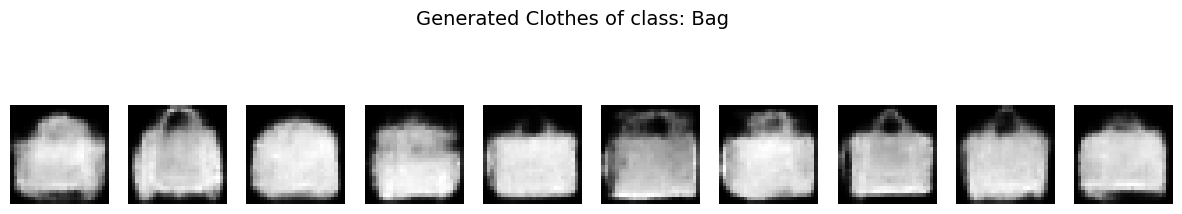

In [ ]:
for target in range(9):
  c_mu, c_std = get_class_stats(vae_model, train_loader, target, device)

  print(f"Генерація для класу {fashion_mnist_labels[target]}...")
  generate_specific_clothes(vae_model, c_mu, c_std, n_samples=10, noise_scale=1.5, device=device, label=fashion_mnist_labels[target])

In [ ]:
convolutional_autoencoder_for_anomaly_detection = ResidualAutoEncoder_v4().to(device)
convolutional_autoencoder_for_anomaly_detection_optimizer = optim.Adam(convolutional_autoencoder_for_anomaly_detection.parameters(), lr=1e-4)
early_stop = EarlyStopping(patience=10, min_delta=0.0001, verbose=False, path='convolutional_autoencoder_for_anomaly_detection.pth')

In [ ]:
from torch.utils.data import DataLoader, Subset, random_split

def get_single_class_train_val_loaders(dataset, target_class, batch_size=64, train_ratio=0.8):
    indices = [i for i, label in enumerate(dataset.labels) if label == target_class]

    full_class_subset = Subset(dataset, indices)

    train_size = int(train_ratio * len(full_class_subset))
    val_size = len(full_class_subset) - train_size

    train_subset, val_subset = random_split(full_class_subset, [train_size, val_size])

    train_loader = DataLoader(train_subset, batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(val_subset, batch_size=batch_size, shuffle=False)

    return train_loader, val_loader

In [ ]:
train_one, val_one = get_single_class_train_val_loaders(train_dataset, target_class = 1)

In [ ]:
perform_learning(convolutional_autoencoder_for_anomaly_detection, 30, convolutional_autoencoder_for_anomaly_detection_optimizer, train_one_class_loader, val_one_class_loader, device, early_stop)

In [ ]:
def analyze_anomalies(model, loader, device, threshold=None):
    model.eval()
    mse_loss = nn.MSELoss(reduction='none')

    errors = []
    labels_list = []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)

            if images.dim() == 2:
                images = images.view(-1, 1, 28, 28)

            reconstructed = model(images)

            error = mse_loss(reconstructed, images).mean(dim=[1, 2, 3])

            errors.extend(error.cpu().numpy())
            labels_list.extend(labels.numpy())

    return np.array(errors), np.array(labels_list)

In [ ]:

def plot_average_error_per_class(errors, labels, label_names):
    mean_errors = []
    class_names = []

    for i in range(len(label_names)):
        class_errors = errors[labels == i]

        if len(class_errors) > 0:
            mean_errors.append(np.mean(class_errors))
            class_names.append(label_names[i])

    plt.figure(figsize=(12, 7))

    colors = ['skyblue' if err != min(mean_errors) else 'limegreen' for err in mean_errors]

    bars = plt.bar(class_names, mean_errors, color=colors, edgecolor='black', alpha=0.8)

    for bar in bars:
        yval = bar.get_height()
        plt.text(bar.get_x() + bar.get_width()/2, yval, f'{yval:.4f}',
                 va='bottom', ha='center', fontsize=10, fontweight='bold')

    plt.axhline(y=np.mean(mean_errors), color='red', linestyle='--', label='Загальне середнє')

    plt.title("Середня помилка реконструкції за класами", fontsize=15)
    plt.xlabel("Клас одягу", fontsize=12)
    plt.ylabel("Середній MSE", fontsize=12)
    plt.xticks(rotation=45)
    plt.legend()
    plt.grid(axis='y', linestyle=':', alpha=0.7)
    plt.show()




ЕКСПЕРИМЕНТ: Клас T-shirt/top (0)
Epoch [1/30] - 1.38s
  Train MSE Loss: 0.0300 | Val MSE Loss: 0.0175
--------------------------------------------------
Epoch [2/30] - 1.27s
  Train MSE Loss: 0.0140 | Val MSE Loss: 0.0128
--------------------------------------------------
Epoch [3/30] - 1.27s
  Train MSE Loss: 0.0112 | Val MSE Loss: 0.0107
--------------------------------------------------
Epoch [4/30] - 1.27s
  Train MSE Loss: 0.0099 | Val MSE Loss: 0.0092
--------------------------------------------------
Epoch [5/30] - 1.27s
  Train MSE Loss: 0.0090 | Val MSE Loss: 0.0095
--------------------------------------------------
Epoch [6/30] - 1.28s
  Train MSE Loss: 0.0083 | Val MSE Loss: 0.0087
--------------------------------------------------
Epoch [7/30] - 1.28s
  Train MSE Loss: 0.0078 | Val MSE Loss: 0.0077
--------------------------------------------------
Epoch [8/30] - 1.28s
  Train MSE Loss: 0.0075 | Val MSE Loss: 0.0086
--------------------------------------------------
Epoch

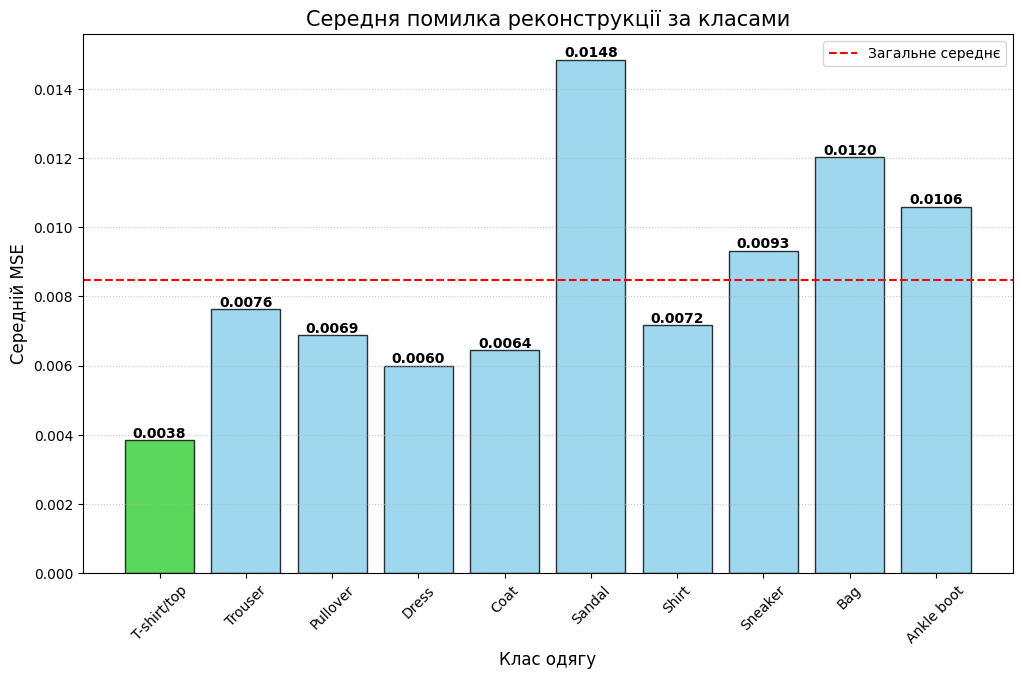


ЕКСПЕРИМЕНТ: Клас Trouser (1)
Epoch [1/30] - 1.30s
  Train MSE Loss: 0.0237 | Val MSE Loss: 0.0120
--------------------------------------------------
Epoch [2/30] - 1.29s
  Train MSE Loss: 0.0088 | Val MSE Loss: 0.0080
--------------------------------------------------
Epoch [3/30] - 1.28s
  Train MSE Loss: 0.0063 | Val MSE Loss: 0.0062
--------------------------------------------------
Epoch [4/30] - 1.32s
  Train MSE Loss: 0.0057 | Val MSE Loss: 0.0066
--------------------------------------------------
Epoch [5/30] - 1.33s
  Train MSE Loss: 0.0048 | Val MSE Loss: 0.0044
--------------------------------------------------
Epoch [6/30] - 1.32s
  Train MSE Loss: 0.0043 | Val MSE Loss: 0.0044
--------------------------------------------------
Epoch [7/30] - 1.29s
  Train MSE Loss: 0.0040 | Val MSE Loss: 0.0049
--------------------------------------------------
Epoch [8/30] - 1.29s
  Train MSE Loss: 0.0036 | Val MSE Loss: 0.0038
--------------------------------------------------
Epoch [9/

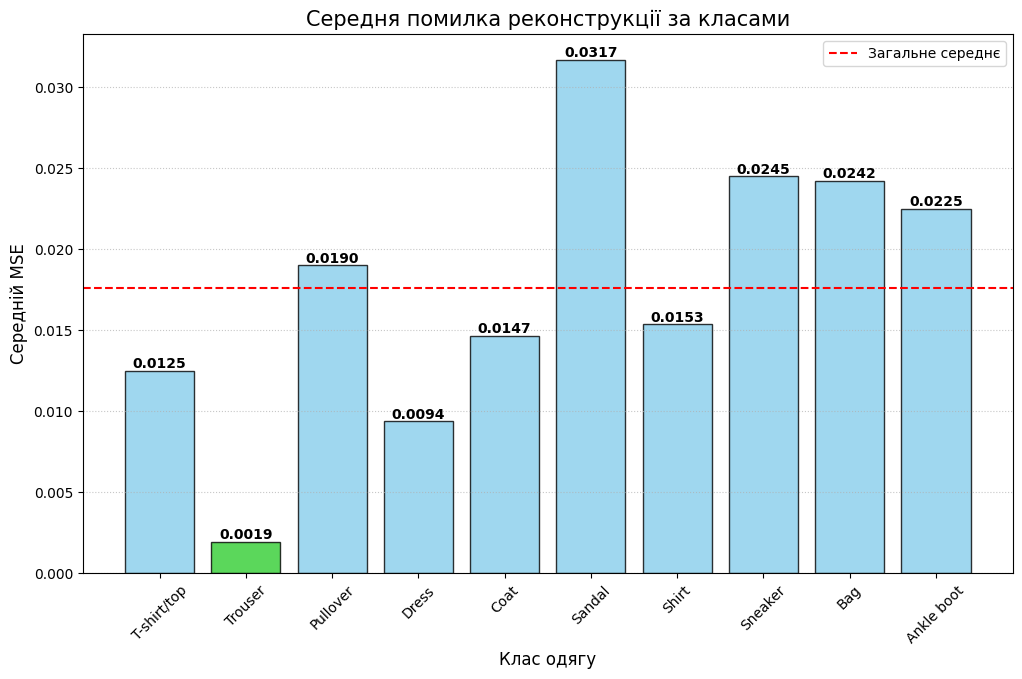


ЕКСПЕРИМЕНТ: Клас Pullover (2)
Epoch [1/30] - 1.33s
  Train MSE Loss: 0.0335 | Val MSE Loss: 0.0199
--------------------------------------------------
Epoch [2/30] - 1.28s
  Train MSE Loss: 0.0167 | Val MSE Loss: 0.0158
--------------------------------------------------
Epoch [3/30] - 1.50s
  Train MSE Loss: 0.0134 | Val MSE Loss: 0.0137
--------------------------------------------------
Epoch [4/30] - 1.28s
  Train MSE Loss: 0.0112 | Val MSE Loss: 0.0111
--------------------------------------------------
Epoch [5/30] - 1.29s
  Train MSE Loss: 0.0099 | Val MSE Loss: 0.0089
--------------------------------------------------
Epoch [6/30] - 1.28s
  Train MSE Loss: 0.0087 | Val MSE Loss: 0.0095
--------------------------------------------------
Epoch [7/30] - 1.28s
  Train MSE Loss: 0.0085 | Val MSE Loss: 0.0074
--------------------------------------------------
Epoch [8/30] - 1.29s
  Train MSE Loss: 0.0079 | Val MSE Loss: 0.0070
--------------------------------------------------
Epoch [9

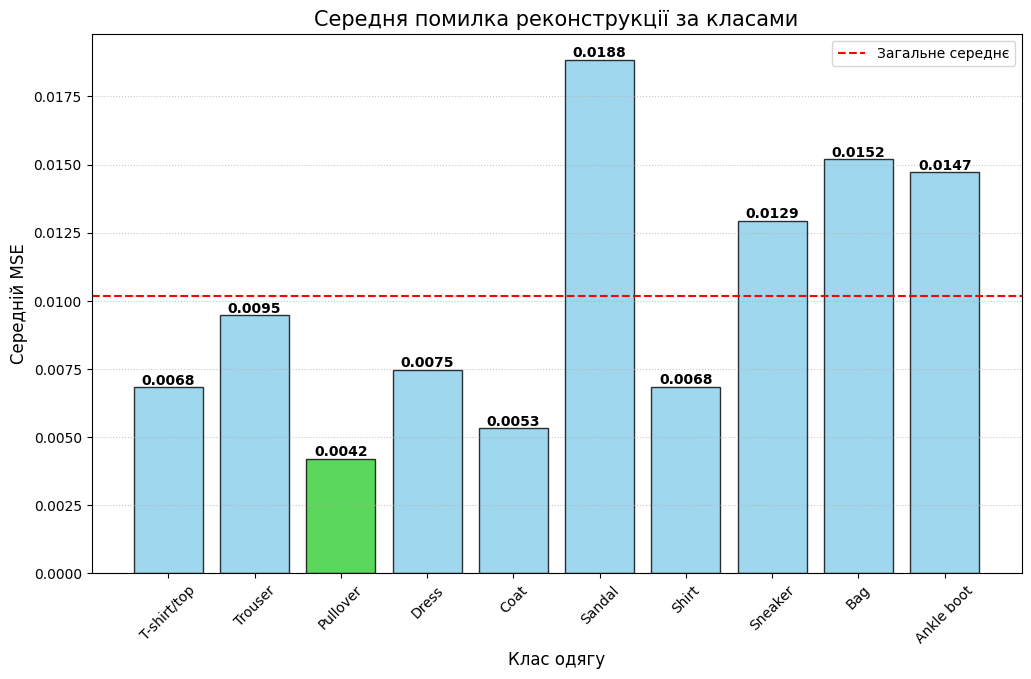


ЕКСПЕРИМЕНТ: Клас Dress (3)
Epoch [1/30] - 1.29s
  Train MSE Loss: 0.0289 | Val MSE Loss: 0.0184
--------------------------------------------------
Epoch [2/30] - 1.29s
  Train MSE Loss: 0.0152 | Val MSE Loss: 0.0150
--------------------------------------------------
Epoch [3/30] - 1.29s
  Train MSE Loss: 0.0118 | Val MSE Loss: 0.0108
--------------------------------------------------
Epoch [4/30] - 1.31s
  Train MSE Loss: 0.0109 | Val MSE Loss: 0.0114
--------------------------------------------------
Epoch [5/30] - 1.33s
  Train MSE Loss: 0.0094 | Val MSE Loss: 0.0087
--------------------------------------------------
Epoch [6/30] - 1.31s
  Train MSE Loss: 0.0088 | Val MSE Loss: 0.0090
--------------------------------------------------
Epoch [7/30] - 1.29s
  Train MSE Loss: 0.0077 | Val MSE Loss: 0.0073
--------------------------------------------------
Epoch [8/30] - 1.29s
  Train MSE Loss: 0.0072 | Val MSE Loss: 0.0069
--------------------------------------------------
Epoch [9/30

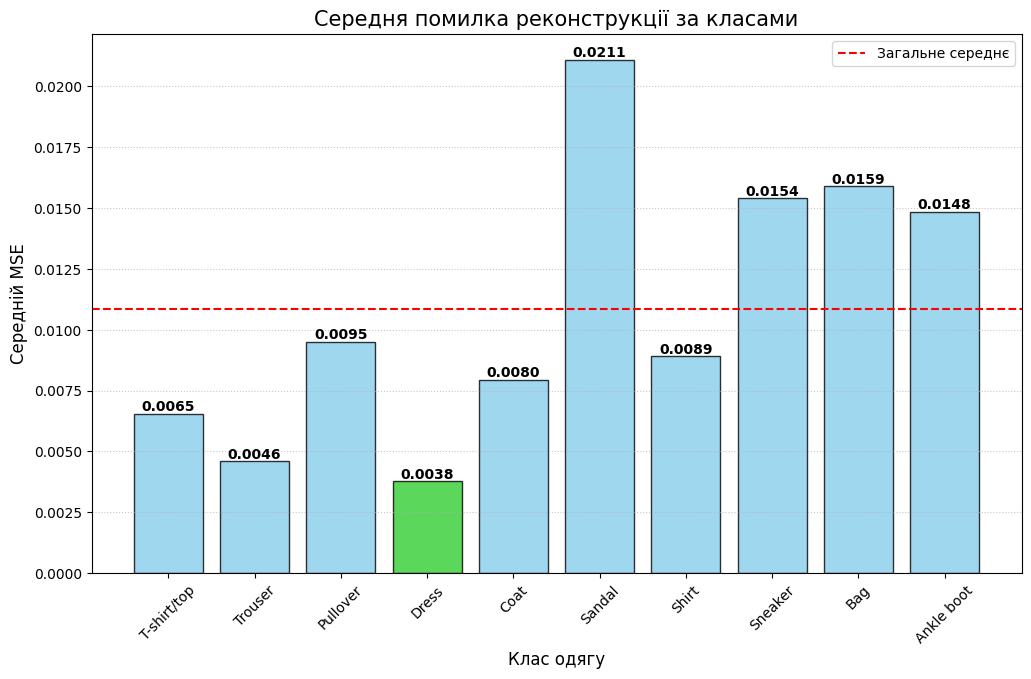


ЕКСПЕРИМЕНТ: Клас Coat (4)
Epoch [1/30] - 1.34s
  Train MSE Loss: 0.0307 | Val MSE Loss: 0.0177
--------------------------------------------------
Epoch [2/30] - 1.28s
  Train MSE Loss: 0.0152 | Val MSE Loss: 0.0150
--------------------------------------------------
Epoch [3/30] - 1.28s
  Train MSE Loss: 0.0124 | Val MSE Loss: 0.0135
--------------------------------------------------
Epoch [4/30] - 1.28s
  Train MSE Loss: 0.0109 | Val MSE Loss: 0.0116
--------------------------------------------------
Epoch [5/30] - 1.28s
  Train MSE Loss: 0.0102 | Val MSE Loss: 0.0105
--------------------------------------------------
Epoch [6/30] - 1.28s
  Train MSE Loss: 0.0086 | Val MSE Loss: 0.0086
--------------------------------------------------
Epoch [7/30] - 1.28s
  Train MSE Loss: 0.0080 | Val MSE Loss: 0.0091
--------------------------------------------------
Epoch [8/30] - 1.28s
  Train MSE Loss: 0.0074 | Val MSE Loss: 0.0076
--------------------------------------------------
Epoch [9/30]

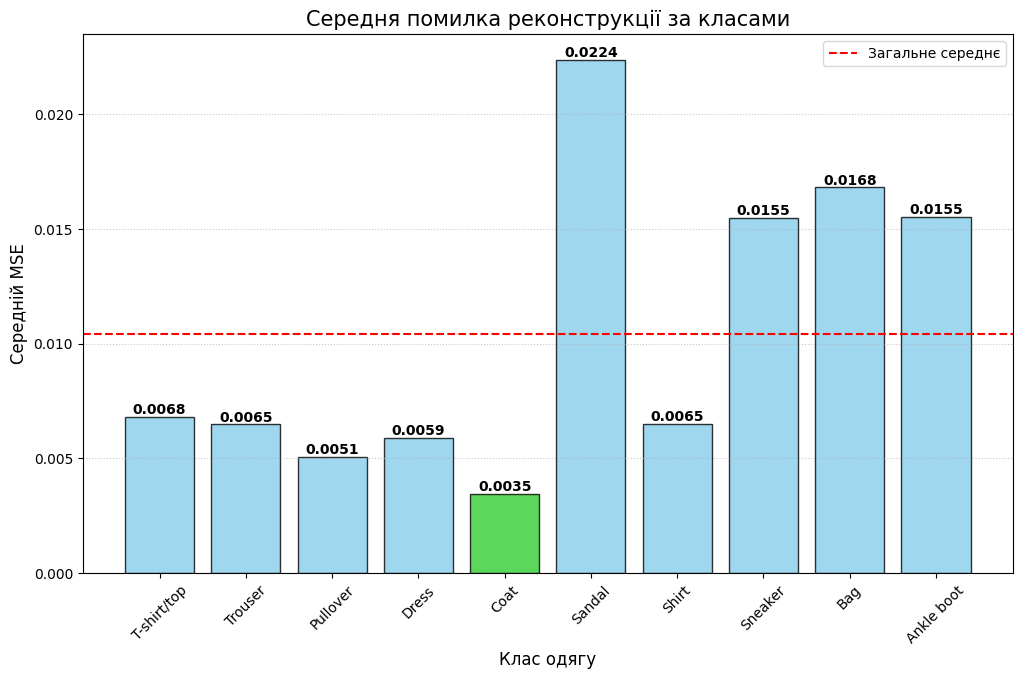


ЕКСПЕРИМЕНТ: Клас Sandal (5)
Epoch [1/30] - 1.28s
  Train MSE Loss: 0.0370 | Val MSE Loss: 0.0256
--------------------------------------------------
Epoch [2/30] - 1.28s
  Train MSE Loss: 0.0190 | Val MSE Loss: 0.0179
--------------------------------------------------
Epoch [3/30] - 1.28s
  Train MSE Loss: 0.0148 | Val MSE Loss: 0.0128
--------------------------------------------------
Epoch [4/30] - 1.30s
  Train MSE Loss: 0.0122 | Val MSE Loss: 0.0149
--------------------------------------------------
Epoch [5/30] - 1.34s
  Train MSE Loss: 0.0113 | Val MSE Loss: 0.0108
--------------------------------------------------
Epoch [6/30] - 1.33s
  Train MSE Loss: 0.0100 | Val MSE Loss: 0.0095
--------------------------------------------------
Epoch [7/30] - 1.28s
  Train MSE Loss: 0.0090 | Val MSE Loss: 0.0107
--------------------------------------------------
Epoch [8/30] - 1.29s
  Train MSE Loss: 0.0085 | Val MSE Loss: 0.0081
--------------------------------------------------
Epoch [9/3

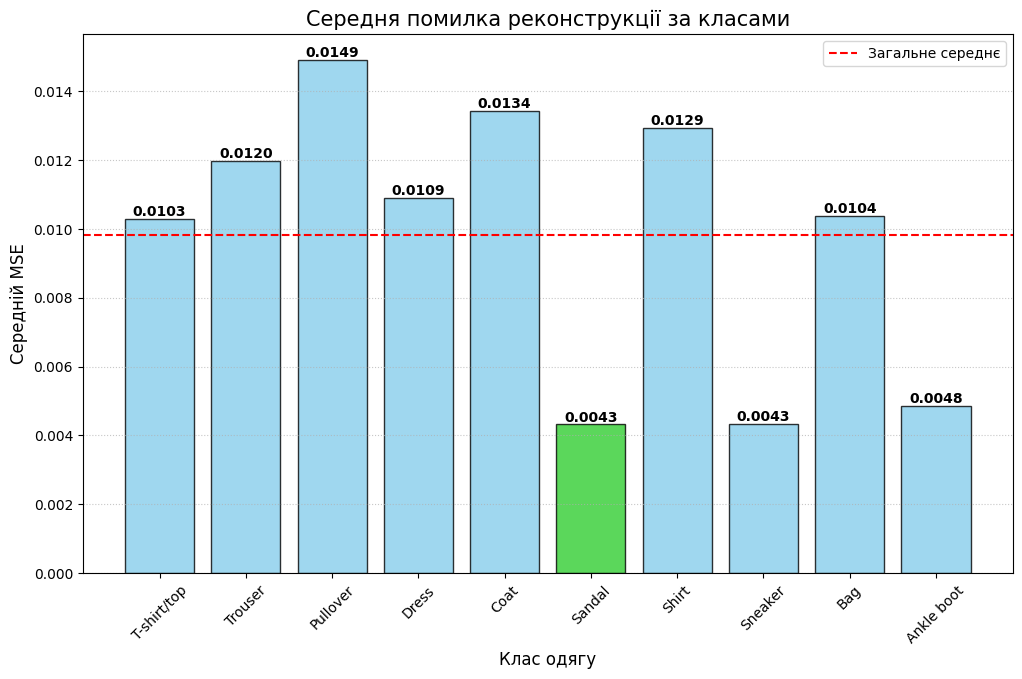


ЕКСПЕРИМЕНТ: Клас Shirt (6)
Epoch [1/30] - 1.35s
  Train MSE Loss: 0.0326 | Val MSE Loss: 0.0231
--------------------------------------------------
Epoch [2/30] - 1.28s
  Train MSE Loss: 0.0167 | Val MSE Loss: 0.0147
--------------------------------------------------
Epoch [3/30] - 1.28s
  Train MSE Loss: 0.0135 | Val MSE Loss: 0.0117
--------------------------------------------------
Epoch [4/30] - 1.29s
  Train MSE Loss: 0.0119 | Val MSE Loss: 0.0112
--------------------------------------------------
Epoch [5/30] - 1.29s
  Train MSE Loss: 0.0107 | Val MSE Loss: 0.0101
--------------------------------------------------
Epoch [6/30] - 1.29s
  Train MSE Loss: 0.0102 | Val MSE Loss: 0.0092
--------------------------------------------------
Epoch [7/30] - 1.28s
  Train MSE Loss: 0.0093 | Val MSE Loss: 0.0087
--------------------------------------------------
Epoch [8/30] - 1.28s
  Train MSE Loss: 0.0088 | Val MSE Loss: 0.0091
--------------------------------------------------
Epoch [9/30

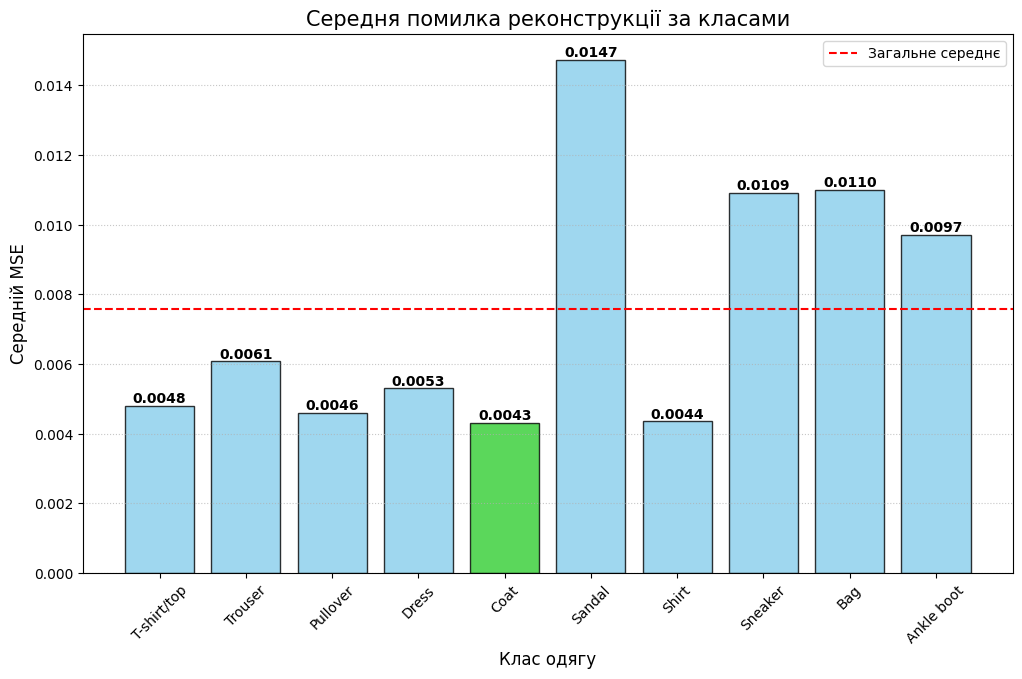


ЕКСПЕРИМЕНТ: Клас Sneaker (7)
Epoch [1/30] - 1.28s
  Train MSE Loss: 0.0237 | Val MSE Loss: 0.0136
--------------------------------------------------
Epoch [2/30] - 1.28s
  Train MSE Loss: 0.0124 | Val MSE Loss: 0.0130
--------------------------------------------------
Epoch [3/30] - 1.28s
  Train MSE Loss: 0.0108 | Val MSE Loss: 0.0113
--------------------------------------------------
Epoch [4/30] - 1.28s
  Train MSE Loss: 0.0097 | Val MSE Loss: 0.0099
--------------------------------------------------
Epoch [5/30] - 1.33s
  Train MSE Loss: 0.0086 | Val MSE Loss: 0.0083
--------------------------------------------------
Epoch [6/30] - 1.35s
  Train MSE Loss: 0.0076 | Val MSE Loss: 0.0073
--------------------------------------------------
Epoch [7/30] - 1.28s
  Train MSE Loss: 0.0071 | Val MSE Loss: 0.0072
--------------------------------------------------
Epoch [8/30] - 1.28s
  Train MSE Loss: 0.0069 | Val MSE Loss: 0.0064
--------------------------------------------------
Epoch [9/

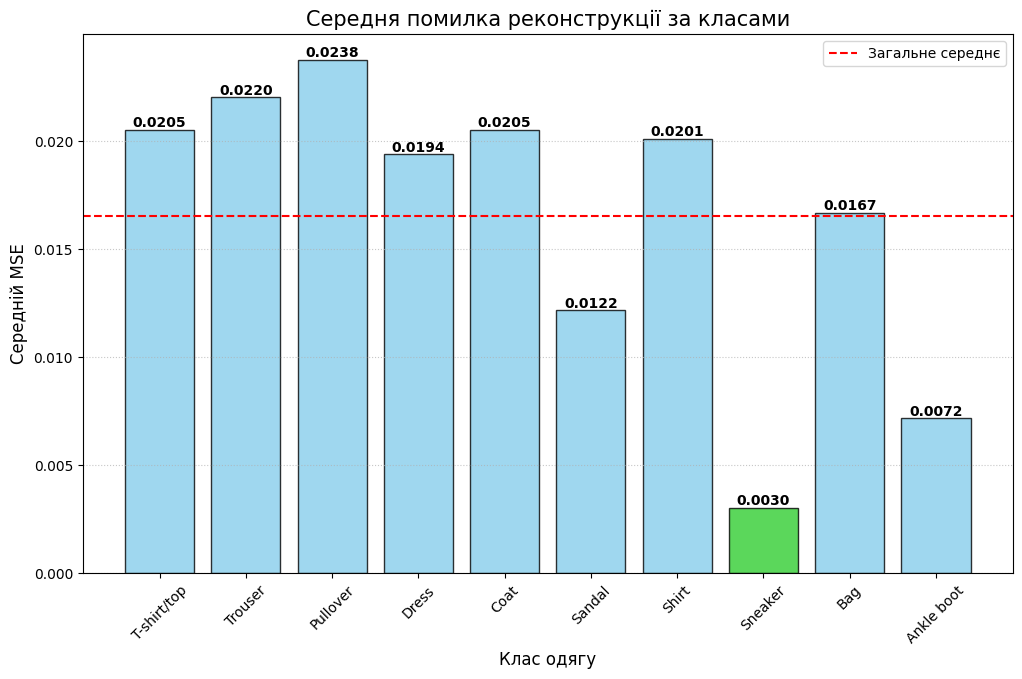


ЕКСПЕРИМЕНТ: Клас Bag (8)
Epoch [1/30] - 1.34s
  Train MSE Loss: 0.0371 | Val MSE Loss: 0.0228
--------------------------------------------------
Epoch [2/30] - 1.31s
  Train MSE Loss: 0.0207 | Val MSE Loss: 0.0195
--------------------------------------------------
Epoch [3/30] - 1.28s
  Train MSE Loss: 0.0179 | Val MSE Loss: 0.0176
--------------------------------------------------
Epoch [4/30] - 1.28s
  Train MSE Loss: 0.0146 | Val MSE Loss: 0.0129
--------------------------------------------------
Epoch [5/30] - 1.28s
  Train MSE Loss: 0.0131 | Val MSE Loss: 0.0118
--------------------------------------------------
Epoch [6/30] - 1.28s
  Train MSE Loss: 0.0119 | Val MSE Loss: 0.0113
--------------------------------------------------
Epoch [7/30] - 1.29s
  Train MSE Loss: 0.0105 | Val MSE Loss: 0.0101
--------------------------------------------------
Epoch [8/30] - 1.29s
  Train MSE Loss: 0.0096 | Val MSE Loss: 0.0097
--------------------------------------------------
Epoch [9/30] 

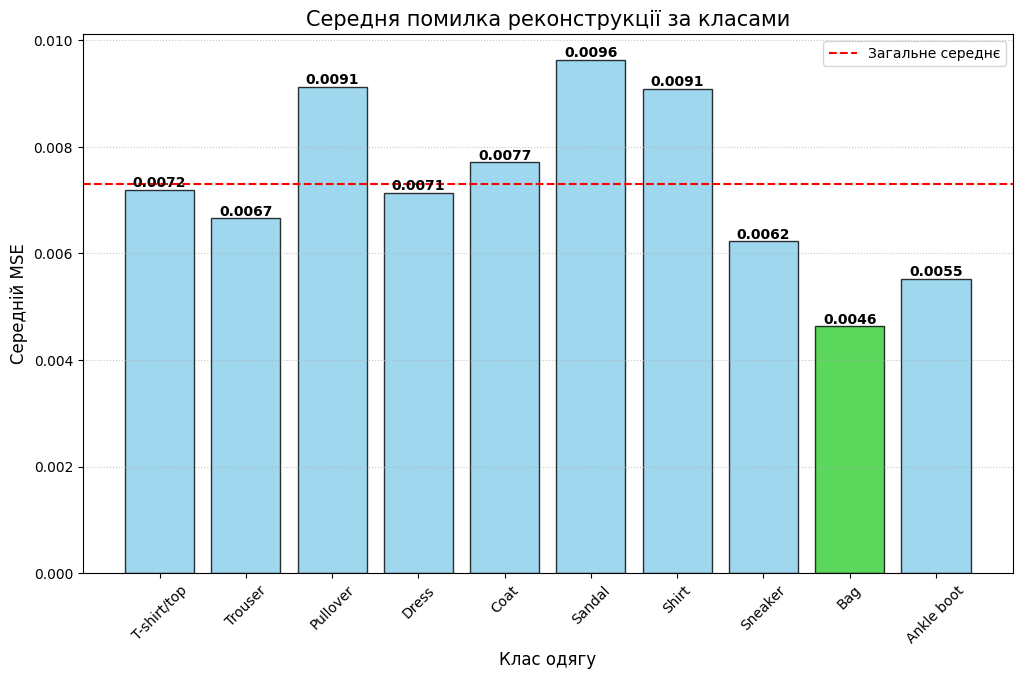


ЕКСПЕРИМЕНТ: Клас Ankle boot (9)
Epoch [1/30] - 1.29s
  Train MSE Loss: 0.0323 | Val MSE Loss: 0.0178
--------------------------------------------------
Epoch [2/30] - 1.28s
  Train MSE Loss: 0.0142 | Val MSE Loss: 0.0143
--------------------------------------------------
Epoch [3/30] - 1.28s
  Train MSE Loss: 0.0107 | Val MSE Loss: 0.0094
--------------------------------------------------
Epoch [4/30] - 1.28s
  Train MSE Loss: 0.0091 | Val MSE Loss: 0.0087
--------------------------------------------------
Epoch [5/30] - 1.33s
  Train MSE Loss: 0.0080 | Val MSE Loss: 0.0081
--------------------------------------------------
Epoch [6/30] - 1.34s
  Train MSE Loss: 0.0072 | Val MSE Loss: 0.0080
--------------------------------------------------
Epoch [7/30] - 1.29s
  Train MSE Loss: 0.0067 | Val MSE Loss: 0.0060
--------------------------------------------------
Epoch [8/30] - 1.28s
  Train MSE Loss: 0.0062 | Val MSE Loss: 0.0059
--------------------------------------------------
Epoch 

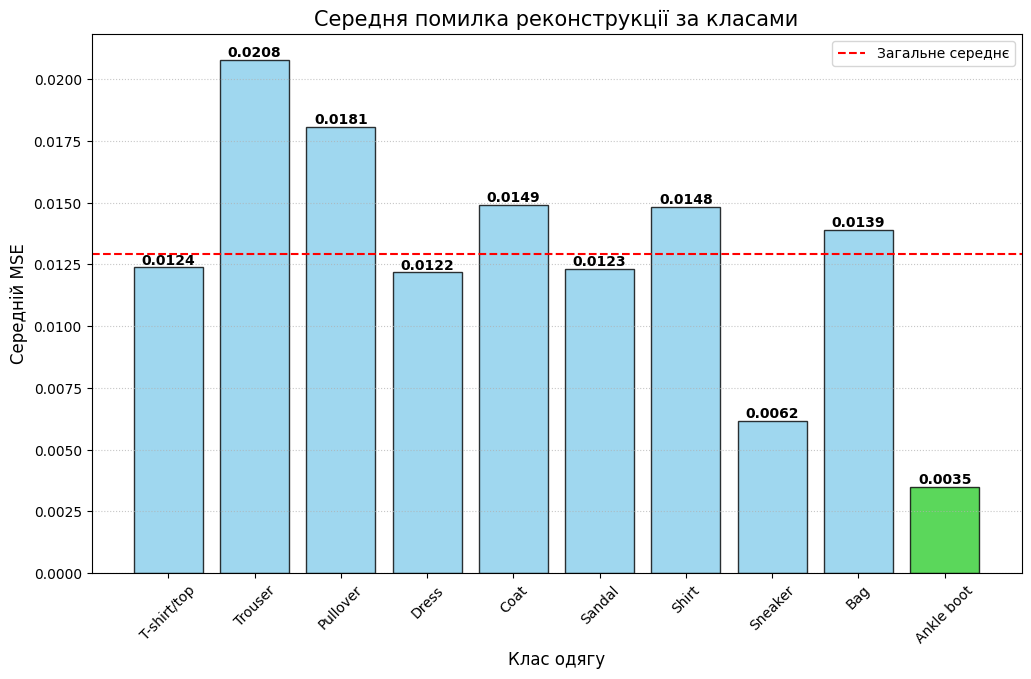


>>> Усі 10 моделей успішно навчено та збережено в словнику 'trained_models' <<<


In [ ]:
import copy

trained_models = {}
error_matrix = np.zeros((10, 10))

for target_class, class_name in fashion_mnist_labels.items():
    print(f"\n" + "="*50)
    print(f"ЕКСПЕРИМЕНТ: Клас {class_name} ({target_class})")
    print("="*50)

    train_one, val_one = get_single_class_train_val_loaders(train_dataset, target_class)

    current_model = ResidualAutoEncoder_v4().to(device)
    current_optimizer = torch.optim.Adam(current_model.parameters(), lr=1e-3)
    early_stop = EarlyStopping(patience=10, min_delta=0.0001, verbose=False, path='convolutional_autoencoder_for_anomaly_detection.pth')

    perform_learning(current_model, 30, current_optimizer, train_one, val_one, device, early_stop)

    trained_models[target_class] = current_model

    errors, labels = analyze_anomalies(current_model, train_loader, device)
    plot_average_error_per_class(errors, labels, fashion_mnist_labels)

    for j in range(10):
        class_j_errors = errors[labels == j]
        if len(class_j_errors) > 0:
            error_matrix[target_class, j] = np.mean(class_j_errors)

    torch.cuda.empty_cache()

print("\n>>> Усі 10 моделей успішно навчено та збережено в словнику 'trained_models' <<<")

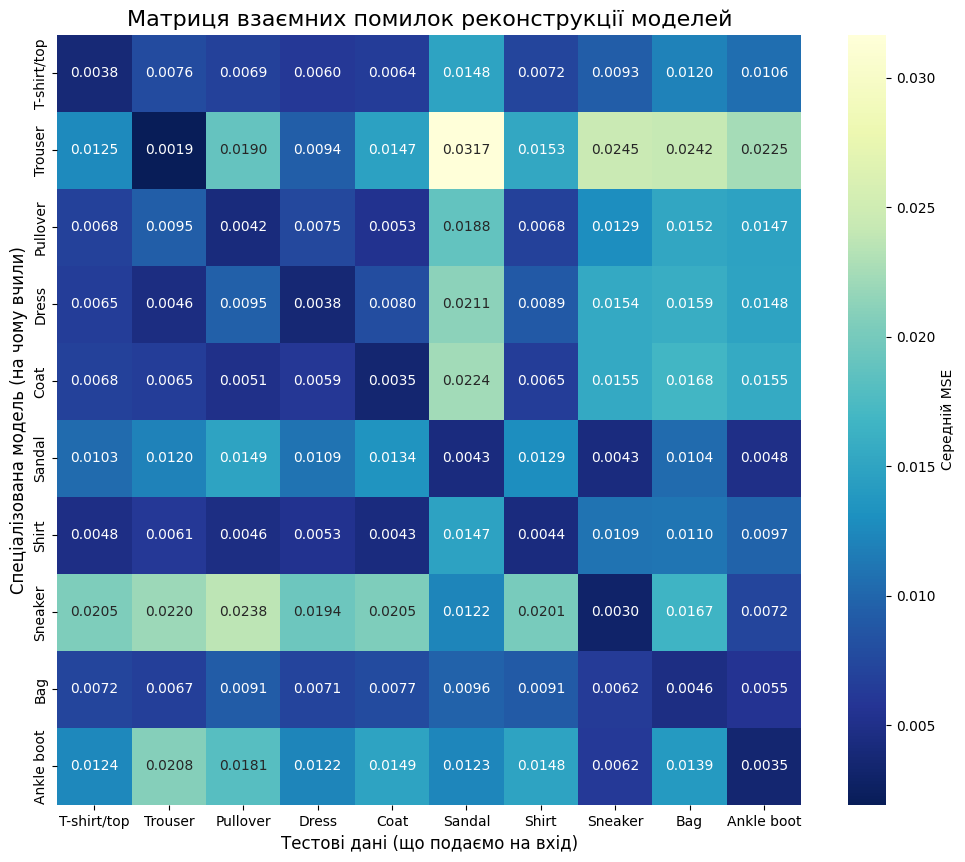

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

def plot_error_heatmap(matrix, label_names):
    plt.figure(figsize=(12, 10))

    df_cm = pd.DataFrame(matrix, index=label_names.values(), columns=label_names.values())

    sns.heatmap(df_cm, annot=True, fmt=".4f", cmap='YlGnBu_r', cbar_kws={'label': 'Середній MSE'})

    plt.title("Матриця взаємних помилок реконструкції моделей", fontsize=16)
    plt.xlabel("Тестові дані (що подаємо на вхід)", fontsize=12)
    plt.ylabel("Спеціалізована модель (на чому вчили)", fontsize=12)
    plt.show()

plot_error_heatmap(error_matrix, fashion_mnist_labels)

In [ ]:
def predict_ensemble(models_dict, images, device):
    batch_size = images.size(0)
    all_errors = torch.zeros(batch_size, 10).to(device)

    for class_id, model in models_dict.items():
        model.eval()
        with torch.no_grad():
            input_images = images
            if input_images.dim() == 2:
                input_images = input_images.view(-1, 1, 28, 28)

            output = model(input_images)
            reconstructed = output[0] if isinstance(output, tuple) else output

            error = torch.mean((reconstructed - input_images)**2, dim=[1, 2, 3])
            all_errors[:, class_id] = error

    preds = torch.argmin(all_errors, dim=1)
    return preds

In [ ]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import seaborn as sns

def evaluate_ensemble(models_dict, loader, device, label_names):
    all_preds = []
    all_labels = []


    for images, labels in loader:
        images = images.to(device)
        preds = predict_ensemble(models_dict, images, device)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())

    acc = accuracy_score(all_labels, all_preds)
    print(f"\nЗАГАЛЬНА ТОЧНІСТЬ АНСАМБЛЮ: {acc*100:.2f}%")

    cm = confusion_matrix(all_labels, all_preds)
    plt.figure(figsize=(12, 10))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=label_names.values(),
                yticklabels=label_names.values())
    plt.title("Confusion Matrix: Ensemble of ResNet Autoencoders")
    plt.xlabel("Передбачено ансамблем")
    plt.ylabel("Реальний клас")
    plt.show()

    print("\nДетальний звіт:")
    print(classification_report(all_labels, all_preds, target_names=label_names.values()))



ЗАГАЛЬНА ТОЧНІСТЬ АНСАМБЛЮ: 87.22%


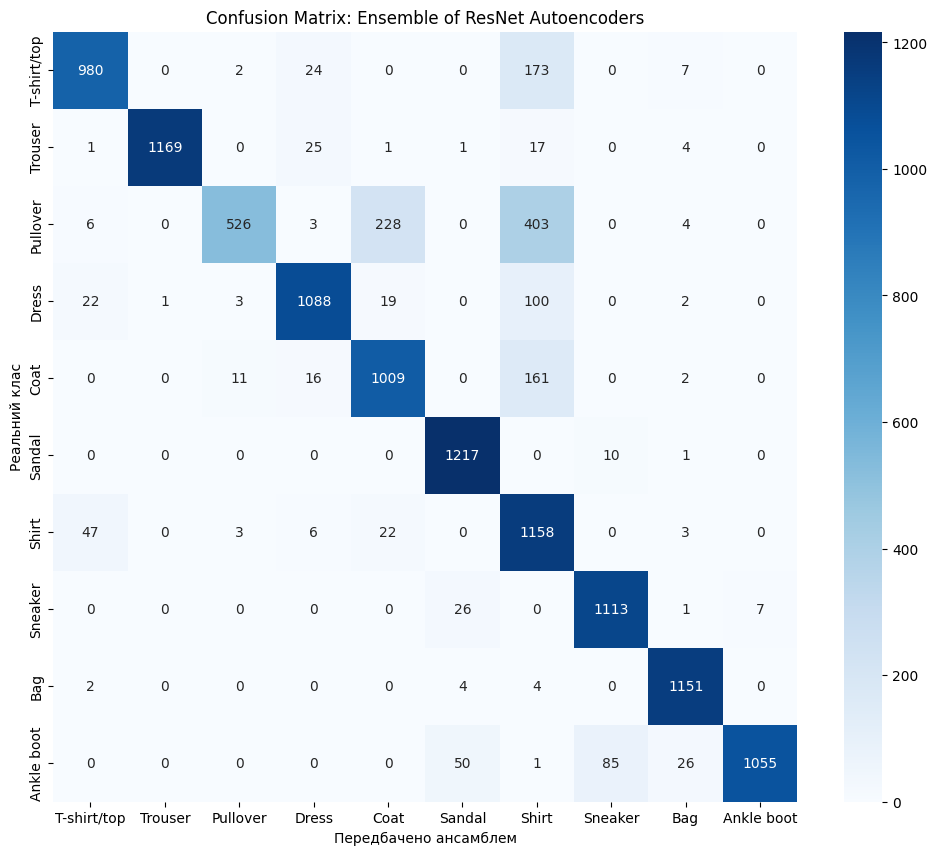


Детальний звіт:
              precision    recall  f1-score   support

 T-shirt/top       0.93      0.83      0.87      1186
     Trouser       1.00      0.96      0.98      1218
    Pullover       0.97      0.45      0.61      1170
       Dress       0.94      0.88      0.91      1235
        Coat       0.79      0.84      0.81      1199
      Sandal       0.94      0.99      0.96      1228
       Shirt       0.57      0.93      0.71      1239
     Sneaker       0.92      0.97      0.95      1147
         Bag       0.96      0.99      0.97      1161
  Ankle boot       0.99      0.87      0.93      1217

    accuracy                           0.87     12000
   macro avg       0.90      0.87      0.87     12000
weighted avg       0.90      0.87      0.87     12000



In [ ]:
evaluate_ensemble(trained_models, val_loader, device, fashion_mnist_labels)